
# Clasificación de OSNR Haciendo Nested Cross-Validation 5×5 + predicciones outer-fold (OOF) + SHAP + tiempo de inferencia (KDE)
## Primero para monitoreo asistido

## RDF 32GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_KDE_correct.csv
Muestras: 9307
Características: 31
NORMAL: 5805
ALARMA: 3502
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como característica de entrada.

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RANDOM FOREST

OUTER FOLD 1/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Inner CV Best F1: 0.8668

MÉTRICAS OUTER FOLD:
Accuracy:    0.9060
Precision:   0.9215
Recall:      0.8203
F1:          0.8679
Specificity: 0.9578
Inference Mean: 25.911 µs/muestra
Inference Std:  0.281 µs/muestra

OUTER FOLD 2/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}


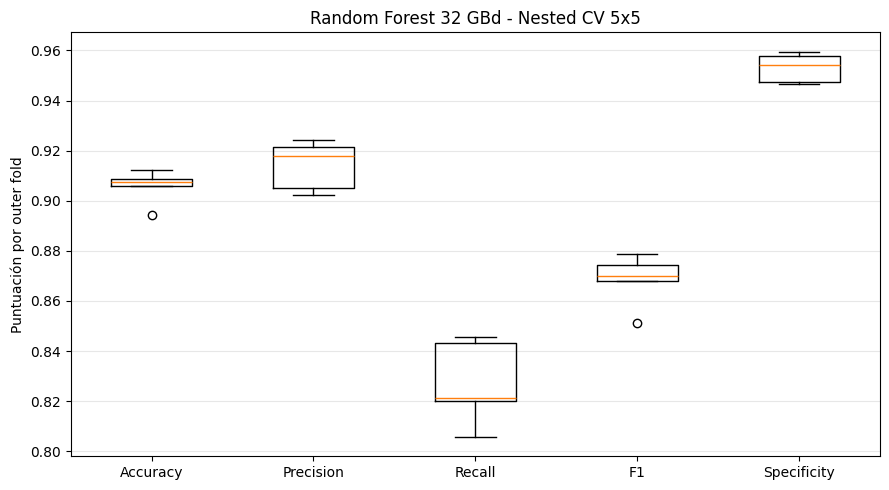


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9058
OOF Precision:   0.9142
OOF Recall:      0.8272
OOF F1:          0.8685
OOF Specificity: 0.9531

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.90      0.95      0.93      5805
      ALARMA       0.91      0.83      0.87      3502

    accuracy                           0.91      9307
   macro avg       0.91      0.89      0.90      9307
weighted avg       0.91      0.91      0.90      9307


Matriz de confusión OOF:
[[5533  272]
 [ 605 2897]]


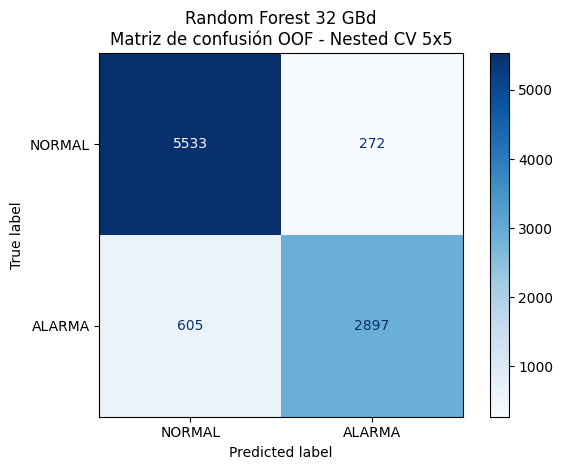


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1        NaN         sqrt                 1                  2           400          0.866844
    2       20.0         sqrt                 1                  2           400          0.867022
    3       20.0         sqrt                 1                  2           400          0.871525
    4        NaN         sqrt                 1                  2           400          0.866116
    5       20.0         sqrt                 1                  5           200          0.867380

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 22.810 µs/muestra
Inference Std:  5.519 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. No es latencia individual.

ENTRENANDO MODELO FINAL - RANDOM FOREST

Mejores parámetros modelo final:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_sp

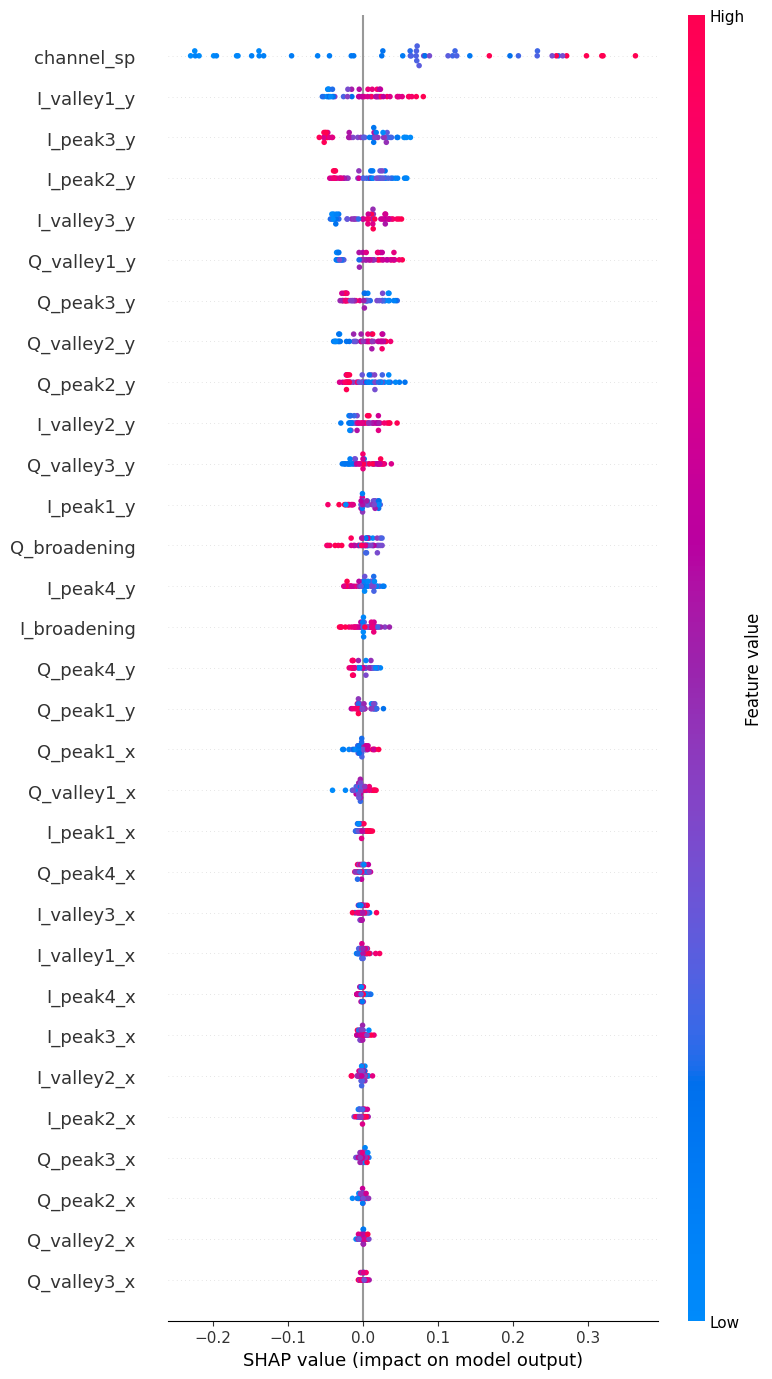

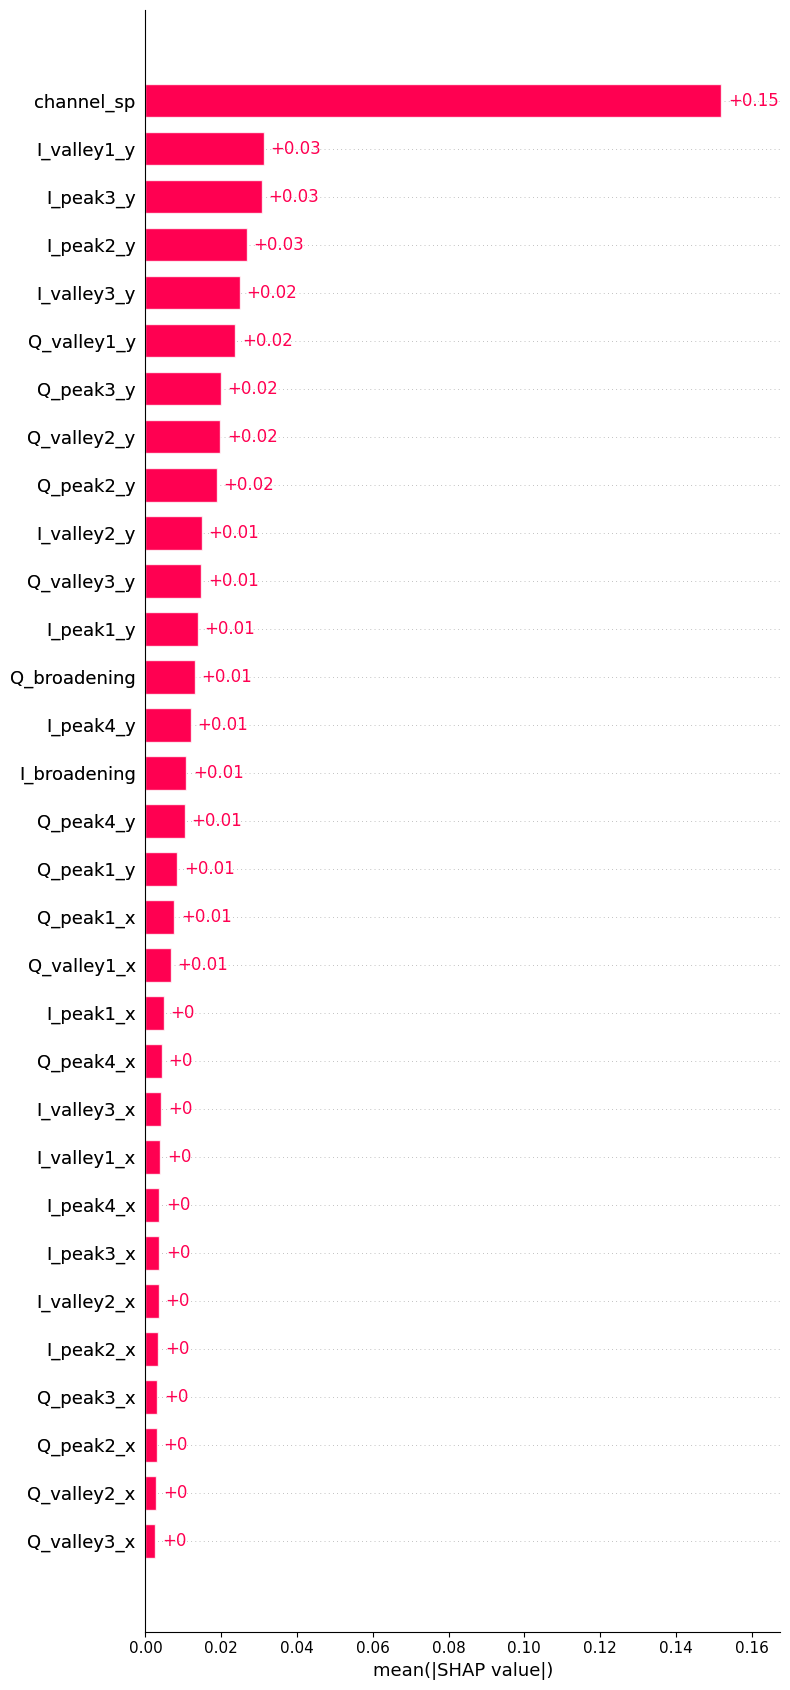

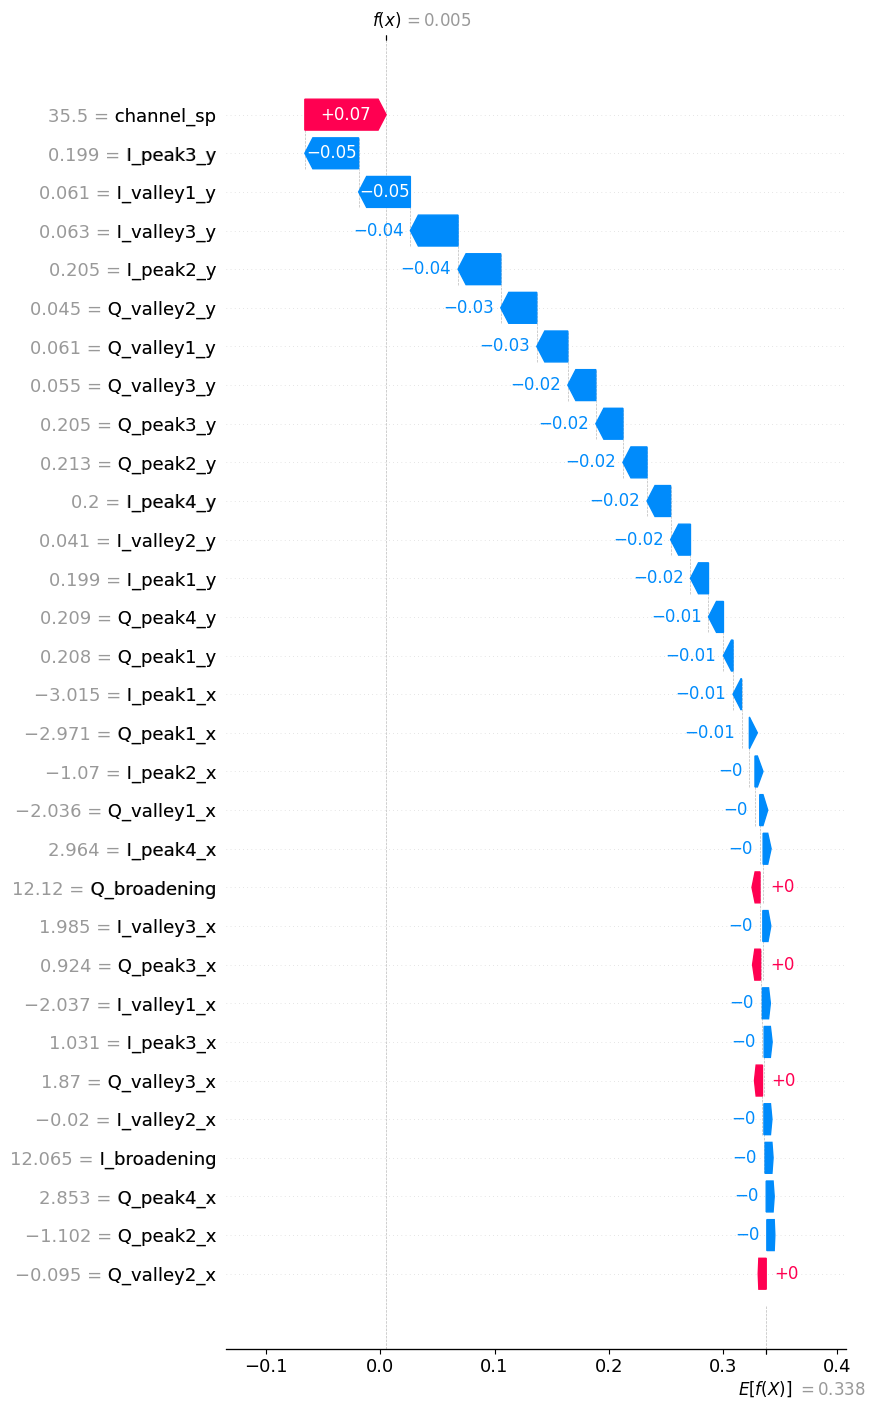


RESUMEN FINAL - RF 32 GBd NESTED CV 5x5
Outer CV Accuracy: 0.9058 ± 0.0062
Outer CV Precision: 0.9142 ± 0.0088
Outer CV Recall: 0.8272 ± 0.0151
Outer CV F1: 0.8685 ± 0.0094
Outer CV Specificity: 0.9531 ± 0.0053
OOF Accuracy: 0.9058
OOF Precision: 0.9142
OOF Recall: 0.8272
OOF F1: 0.8685
OOF Specificity: 0.9531
Inference Mean: 22.810 µs/muestra
Inference Std: 5.519 µs/muestra

Archivos generados:
1. rf_osnr_32GBd_nested_outer_folds.csv
2. rf_osnr_32GBd_nested_oof_predictions.csv
3. rf_osnr_32GBd_nested_best_params.csv
4. rf_osnr_32GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
===============================================================
CLASIFICACIÓN OSNR 32 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, SHAP Y TIEMPO DE INFERENCIA
===============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo original)

METODOLOGÍA:
    - Outer CV: 5 folds estratificados
    - Inner CV: 5 folds estratificados
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF sobre todas las muestras
    - Métricas por fold y métricas OOF globales
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todo el dataset
    - SHAP para interpretar el modelo final

IMPORTANTE:
    La CV es estratificada por filas, no por escenario.
    Si hay muestras dependientes del mismo experimento,
    considerar validación agrupada.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# =============================================================
# 1. CONFIGURACIÓN GENERAL
# =============================================================

CSV_PATH = "matriz32GBd_KDE_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# =============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# =============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# =============================================================
# 3. CARGAR Y VALIDAR DATASET
# =============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas son las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# La columna 32 contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Convertir OSNR a clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para realizar los outer folds."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: channel_sp "
    "se utiliza como característica de entrada."
)

# =============================================================
# 4. MODELO Y GRID DE HIPERPARÁMETROS
# =============================================================

def build_rf():
    """
    Crea una instancia nueva de Random Forest.

    n_jobs=1 evita paralelismo anidado:
    GridSearchCV utiliza n_jobs=-1.
    """
    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el mismo grid del código original.
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# =============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# =============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada posición corresponde a una fila del dataset.
# Se rellena únicamente cuando esa muestra está
# en el outer test de un fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Número de fold donde se evaluó cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RANDOM FOREST")
print("=" * 65)

# =============================================================
# 6. BUCLE PRINCIPAL: OUTER CV
# =============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # ---------------------------------------------------------
    # 6.1 DATOS DE ENTRENAMIENTO Y TEST EXTERNOS
    # ---------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # ---------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # ---------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # IMPORTANTE:
    # GridSearchCV solo recibe el outer train.
    # El outer test permanece completamente separado.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # ---------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # ---------------------------------------------------------

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar en las posiciones originales.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # ---------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # ---------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # ---------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # ---------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(X_outer_test)

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # ---------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS
    # ---------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# =============================================================
# 7. VERIFICAR PREDICCIONES OOF
# =============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# =============================================================
# 8. RESULTADOS POR OUTER FOLD
# =============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_32GBd_nested_outer_folds.csv",
    index=False
)

# =============================================================
# 9. PROMEDIO Y DESVIACIÓN ESTÁNDAR OUTER CV
# =============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# =============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# =============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 11. MÉTRICAS GLOBALES OOF
# =============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# =============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# =============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 13. GUARDAR PREDICCIONES OOF
# =============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_32GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# =============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# =============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_32GBd_nested_best_params.csv",
    index=False
)

# =============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# =============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "No es latencia individual."
)

# =============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# =============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RANDOM FOREST")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# =============================================================
# 17. SHAP - TREEEXPLAINER
# =============================================================

# Explicamos P(ALARMA) = P(clase 1).
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    reduce la probabilidad de ALARMA.
#
# Las muestras explicadas fueron utilizadas
# para entrenar el modelo final.
# Por eso este SHAP es descriptivo y NO OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# Diferentes versiones de SHAP devuelven:
#
# Versión antigua:
#   lista [SHAP clase 0, SHAP clase 1]
#
# Versión reciente:
#   array (n_muestras, n_features, n_clases)

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base de probabilidad ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# =============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# =============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_32GBd_nested_importancia_shap.csv",
    index=False
)

# =============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# =============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# =============================================================
# 20. GRÁFICAS SHAP
# =============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall: primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# =============================================================
# 21. RESUMEN FINAL
# =============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF 32 GBd NESTED CV 5x5")
print("=" * 65)

print(
    f"Outer CV Accuracy: "
    f"{results_df['accuracy'].mean():.4f} ± "
    f"{results_df['accuracy'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Precision: "
    f"{results_df['precision'].mean():.4f} ± "
    f"{results_df['precision'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Recall: "
    f"{results_df['recall'].mean():.4f} ± "
    f"{results_df['recall'].std(ddof=0):.4f}"
)

print(
    f"Outer CV F1: "
    f"{results_df['f1'].mean():.4f} ± "
    f"{results_df['f1'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Specificity: "
    f"{results_df['specificity'].mean():.4f} ± "
    f"{results_df['specificity'].std(ddof=0):.4f}"
)

print(
    f"OOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_32GBd_nested_outer_folds.csv")
print("2. rf_osnr_32GBd_nested_oof_predictions.csv")
print("3. rf_osnr_32GBd_nested_best_params.csv")
print("4. rf_osnr_32GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 32GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_KDE_correct.csv
Muestras: 9307
Características: 31
NORMAL: 5805
ALARMA: 3502
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - SVM 32 GBd

OUTER FOLD 1/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 'scale'}
Inner CV Best F1: 0.8596

MÉTRICAS OUTER FOLD:
Accuracy:    0.8910
Precision:   0.8458
Recall:      0.8688
F1:          0.8571
Specificity: 0.9044
Inference Mean: 89.589 µs/muestra
Inference Std:  0.248 µs/muestra

OUTER FOLD 2/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 'scale'}
Inner CV Best F1: 0.8590

MÉTRICAS OUTER FOLD:
Accuracy:    0.9023
Precision:   0.9074
Recall:      0.8245
F1:          0.8640
Specificity: 0.9492

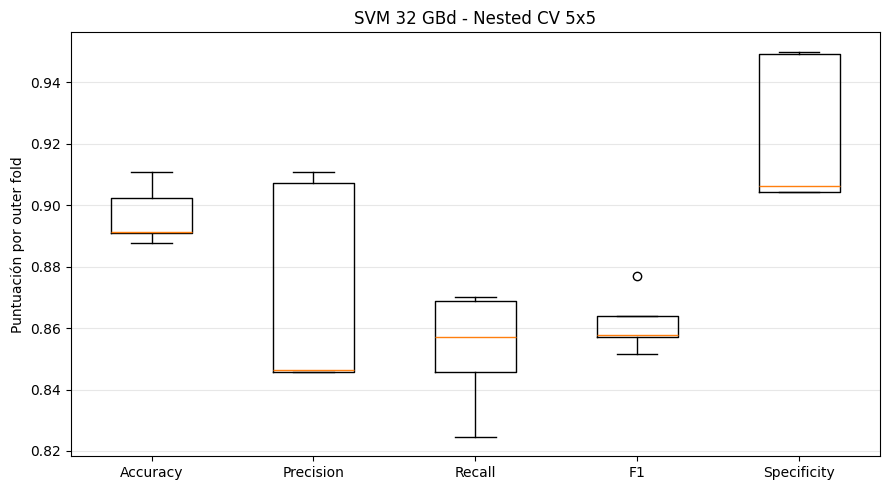


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8966
OOF Precision:   0.8696
OOF Recall:      0.8532
OOF F1:          0.8613
OOF Specificity: 0.9228

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.91      0.92      0.92      5805
      ALARMA       0.87      0.85      0.86      3502

    accuracy                           0.90      9307
   macro avg       0.89      0.89      0.89      9307
weighted avg       0.90      0.90      0.90      9307


Matriz de confusión OOF:
[[5357  448]
 [ 514 2988]]


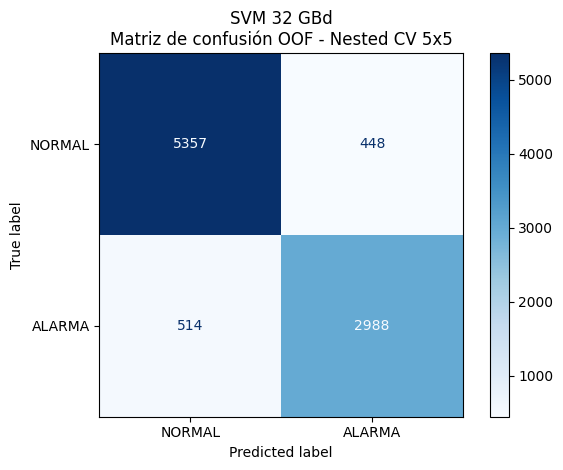


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight svm__gamma  inner_cv_best_f1
    1      10          balanced      scale          0.859582
    2      10              None      scale          0.858957
    3       1          balanced      scale          0.860600
    4     100          balanced       0.01          0.858804
    5      10              None      scale          0.858337

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 91.609 µs/muestra
Inference Std:  9.135 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM

Mejores parámetros modelo final:
{'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 'scale'}
F1 GridSearch final: 0.8617

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
  channel_sp      1.759458             47.17%
 I_valley1_y      0.204509              5.48%
   Q_peak2_y      0.163450              4.38%
   I_peak2_y      0.157931              4.23%
 Q_valley1_y      0.139601              3.74%
   Q_peak3_y      0.133352              3.57%
   I_peak3_y      0.126282              3.39%
   Q_peak4_y      0.123813              3.32%
   Q_peak1_x      0.091628              2.46%
 I_valley3_y      0.089974              2.41%
Q_broadening      0.087264              2.34%
   Q_peak1_y      0.071504              1.92%
   I_peak4_y      0.071467              1.92%
 Q_valley3_y      0.068940              1.85%
   Q_peak3_x      0.066106              1.77%
 Q_valley1_x      0.061013              1.64%
 Q_valley2_y      0.052270              1.40%
   Q_peak2_x      0.051883              1.39%
I_broadening      0.049081              1.32%
   I_peak2_x      0.037408              

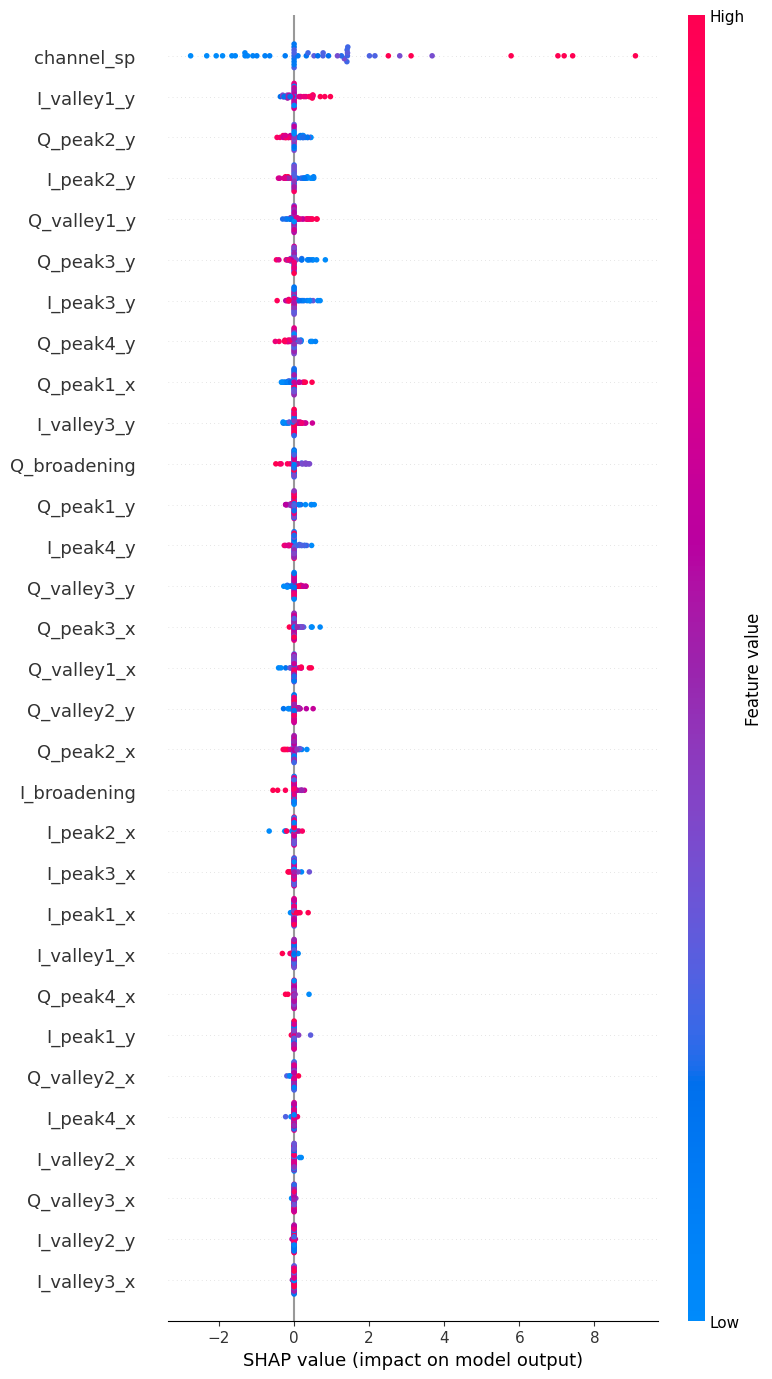

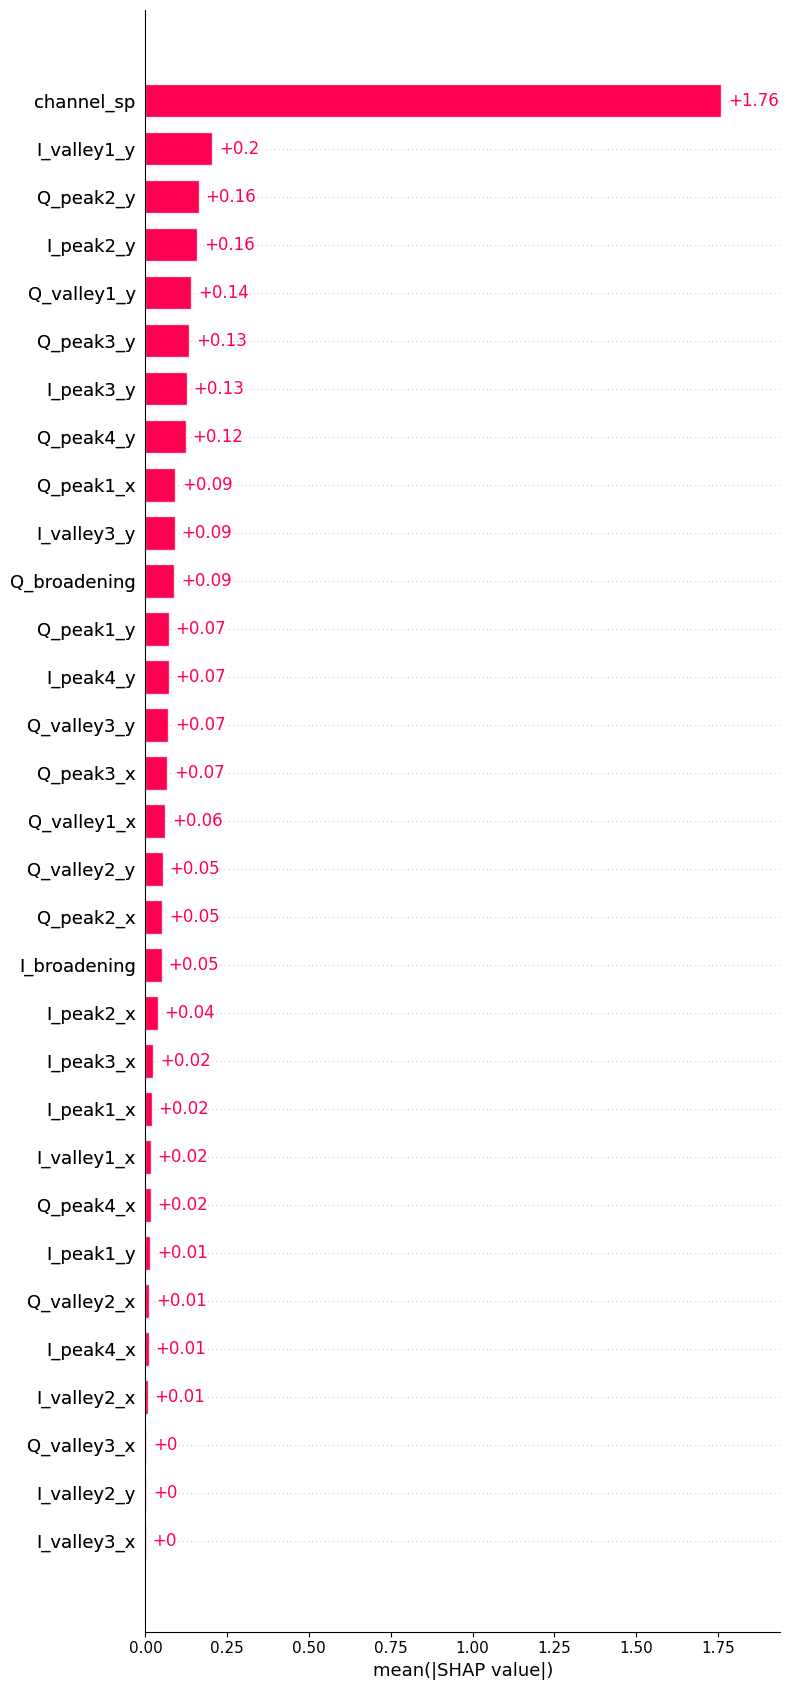

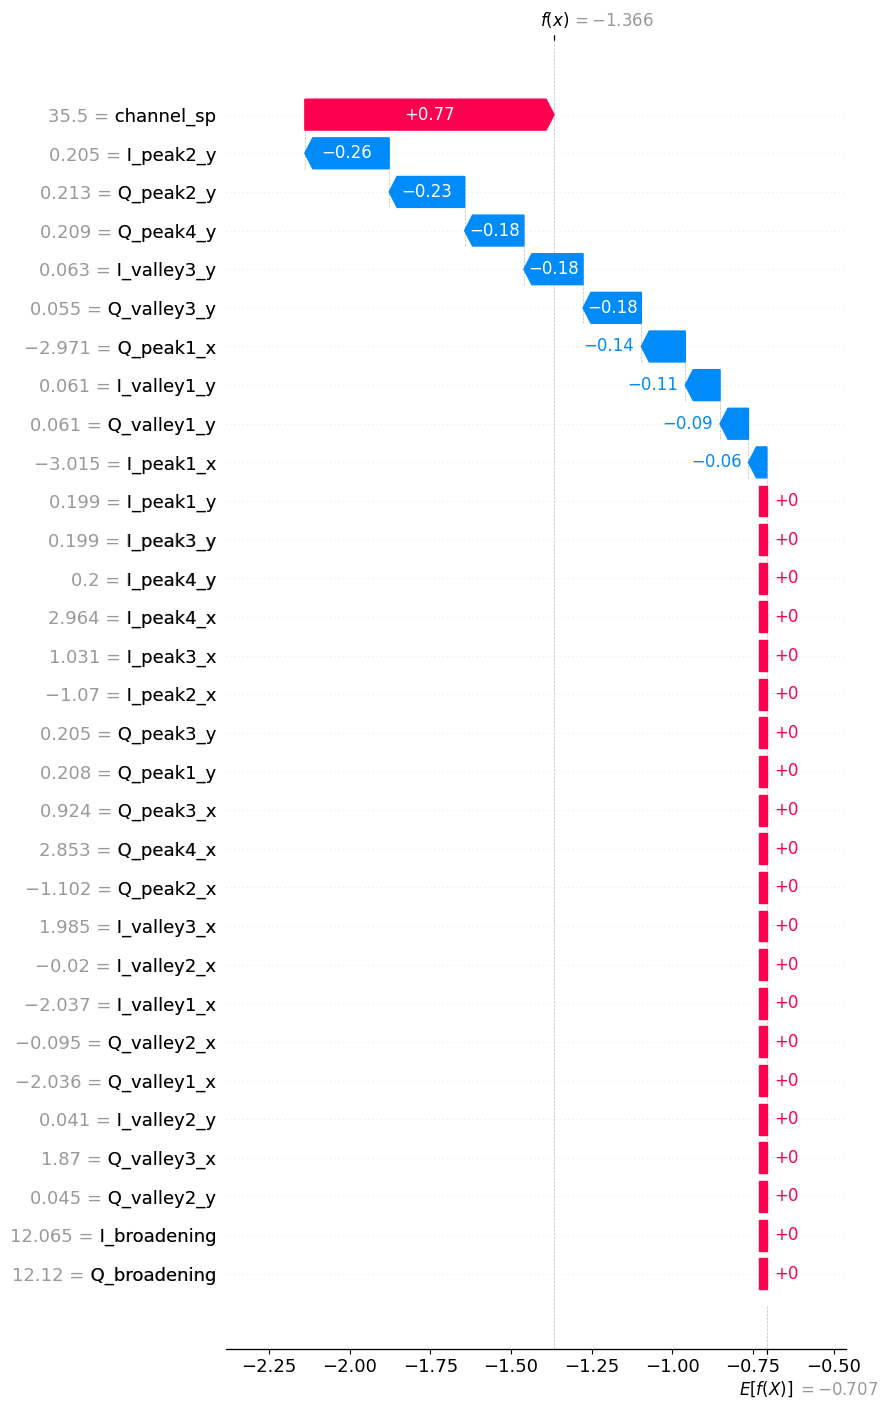


RESUMEN FINAL - SVM 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8966 ± 0.0086
Outer CV PRECISION   : 0.8712 ± 0.0309
Outer CV RECALL      : 0.8532 ± 0.0168
Outer CV F1          : 0.8615 ± 0.0087
Outer CV SPECIFICITY : 0.9228 ± 0.0219

OOF Accuracy: 0.8966
OOF Precision: 0.8696
OOF Recall: 0.8532
OOF F1: 0.8613
OOF Specificity: 0.9228

Inference Mean: 91.609 µs/muestra
Inference Std: 9.135 µs/muestra

Archivos generados:
1. svm_osnr_32GBd_nested_outer_folds.csv
2. svm_osnr_32GBd_nested_oof_predictions.csv
3. svm_osnr_32GBd_nested_best_params.csv
4. svm_osnr_32GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 32 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV en cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen realizaciones del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_KDE_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las features.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuaciones de decision_function.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearch solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_32GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_32GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_32GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_32GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_32GBd_nested_outer_folds.csv")
print("2. svm_osnr_32GBd_nested_oof_predictions.csv")
print("3. svm_osnr_32GBd_nested_best_params.csv")
print("4. svm_osnr_32GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 32GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_KDE_correct.csv
Muestras: 9307
Características: 31
NORMAL: 5805
ALARMA: 3502
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - KNN 32 GBd

OUTER FOLD 1/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 7, 'knn__p': 2, 'knn__weights': 'distance'}
Inner CV Best F1: 0.8274

MÉTRICAS OUTER FOLD:
Accuracy:    0.8743
Precision:   0.8543
Recall:      0.8031
F1:          0.8279
Specificity: 0.9173
Inference Mean: 3.461 µs/muestra
Inference Std:  0.173 µs/muestra

OUTER FOLD 2/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 7, 'knn__p': 2, 'knn__weights': 'distance'}
Inner CV Best F1: 0.8191

MÉTRICAS OUTER FOLD:
Accuracy:    0.8813
Precision:   0.8529
Recall:      0.8274
F1:          0.8400
Specificity: 0.9139
Infere

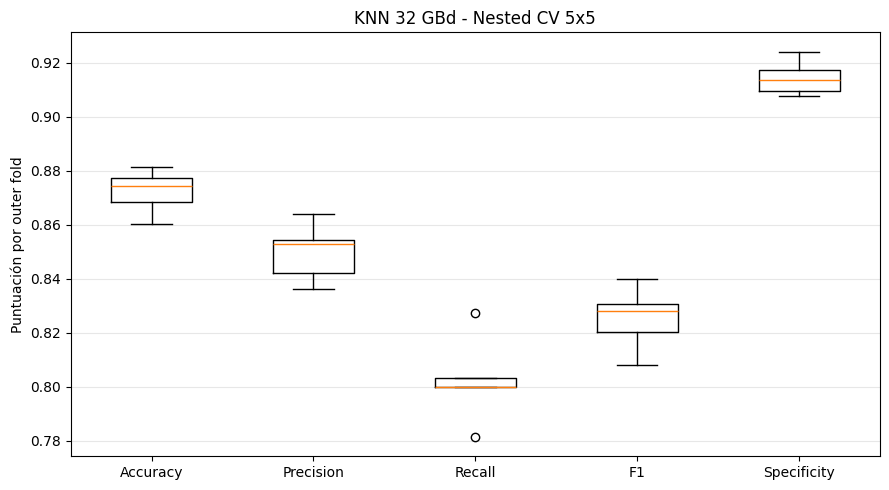


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8724
OOF Precision:   0.8500
OOF Recall:      0.8024
OOF F1:          0.8255
OOF Specificity: 0.9146

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.88      0.91      0.90      5805
      ALARMA       0.85      0.80      0.83      3502

    accuracy                           0.87      9307
   macro avg       0.87      0.86      0.86      9307
weighted avg       0.87      0.87      0.87      9307


Matriz de confusión OOF:
[[5309  496]
 [ 692 2810]]


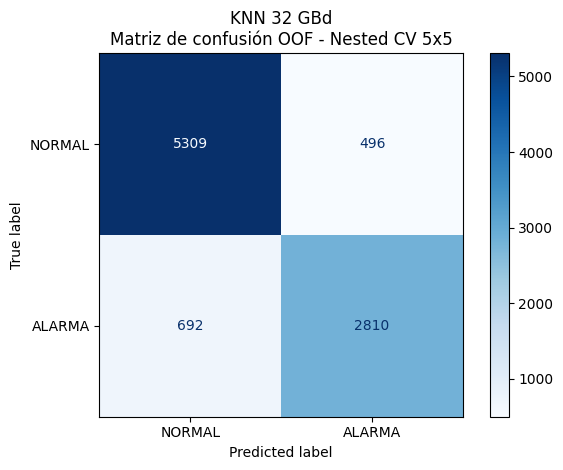


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                 7       2     distance          0.827399
    2                 7       2     distance          0.819107
    3                 5       2     distance          0.822356
    4                11       2     distance          0.822503
    5                11       2     distance          0.819763

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 3.816 µs/muestra
Inference Std:  0.473 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN

Mejores parámetros modelo final:
{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
F1 GridSearch final: 0.8284

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
  channel_sp      0.101849             21.40%
   I_peak3_y      0.023291              4.89%
Q_broadening      0.021556              4.53%
I_broadening      0.020501              4.31%
 Q_valley3_y      0.018750              3.94%
 Q_valley1_y      0.017330              3.64%
   Q_peak2_y      0.017120              3.60%
 I_valley1_y      0.017100              3.59%
 I_valley2_y      0.016190              3.40%
 Q_valley2_y      0.015818              3.32%
   I_peak2_x      0.014799              3.11%
   I_peak2_y      0.014783              3.11%
   Q_peak4_y      0.014210              2.99%
 I_valley3_y      0.014151              2.97%
   I_peak4_y      0.013112              2.75%
   Q_peak3_x      0.011102              2.33%
   Q_peak1_x      0.011084              2.33%
   I_peak4_x      0.011004              2.31%
   I_peak3_x      0.010759              2.26%
   Q_peak3_y      0.010342              

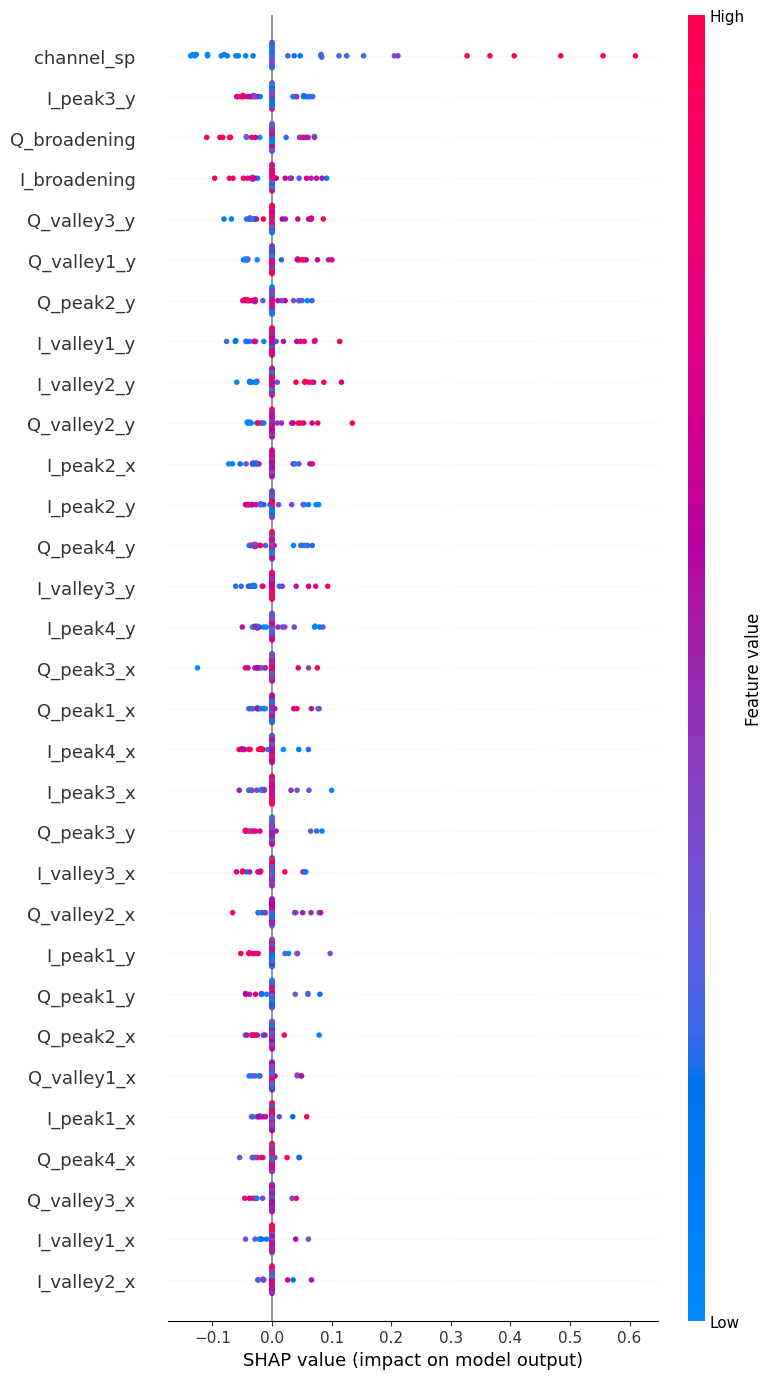

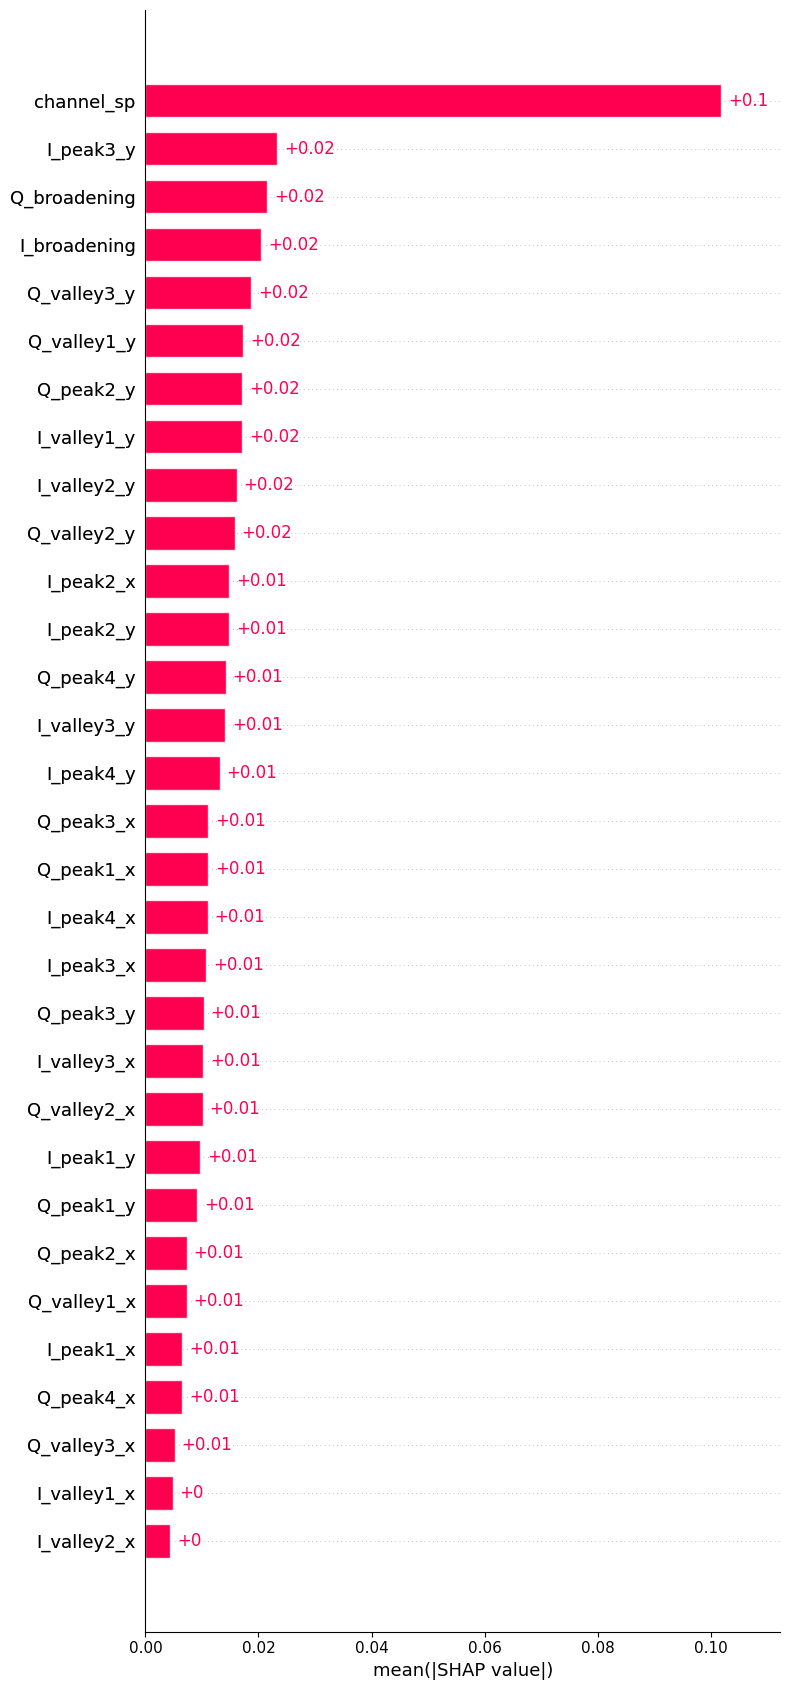

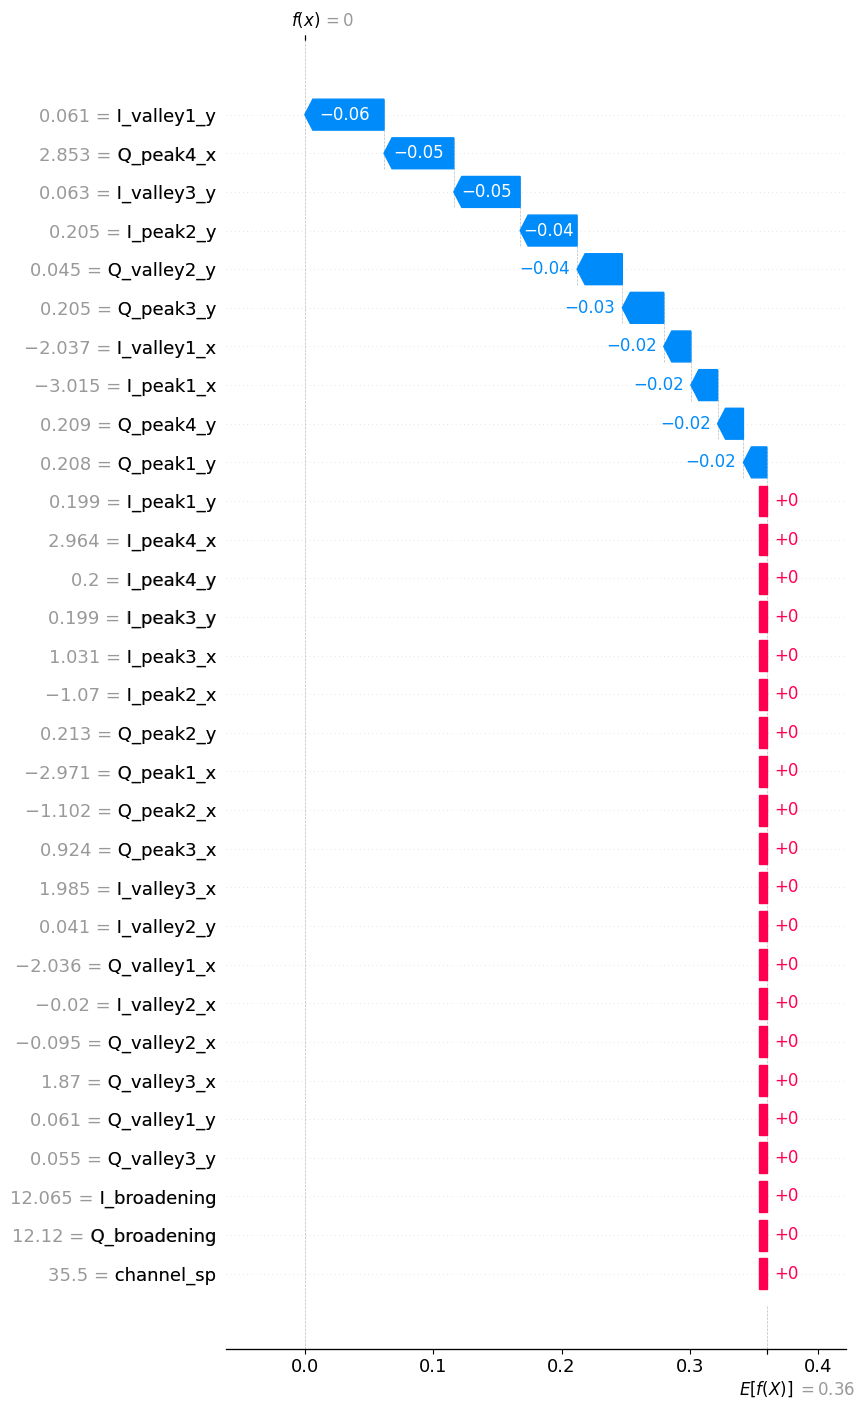


RESUMEN FINAL - KNN 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8724 ± 0.0074
Outer CV PRECISION   : 0.8500 ± 0.0098
Outer CV RECALL      : 0.8024 ± 0.0147
Outer CV F1          : 0.8255 ± 0.0107
Outer CV SPECIFICITY : 0.9146 ± 0.0059

OOF Accuracy: 0.8724
OOF Precision: 0.8500
OOF Recall: 0.8024
OOF F1: 0.8255
OOF Specificity: 0.9146

Inference Mean: 3.816 µs/muestra
Inference Std: 0.473 µs/muestra

Archivos generados:
1. knn_osnr_32GBd_nested_outer_folds.csv
2. knn_osnr_32GBd_nested_oof_predictions.csv
3. knn_osnr_32GBd_nested_best_params.csv
4. knn_osnr_32GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 32 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_KDE_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # GridSearchCV solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_32GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_32GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_32GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_32GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_32GBd_nested_outer_folds.csv")
print("2. knn_osnr_32GBd_nested_oof_predictions.csv")
print("3. knn_osnr_32GBd_nested_best_params.csv")
print("4. knn_osnr_32GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


#Ahora para 16GBd

## RDF 16GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_KDE.csv
Muestras: 243
Características: 31
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como característica de entrada.

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RANDOM FOREST

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Inner CV Best F1: 0.9575

MÉTRICAS OUTER FOLD:
Accuracy:    0.9796
Precision:   1.0000
Recall:      0.9524
F1:          0.9756
Specificity: 1.0000
Inference Mean: 42.489 µs/muestra
Inference Std:  1.083 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Inner CV Best F

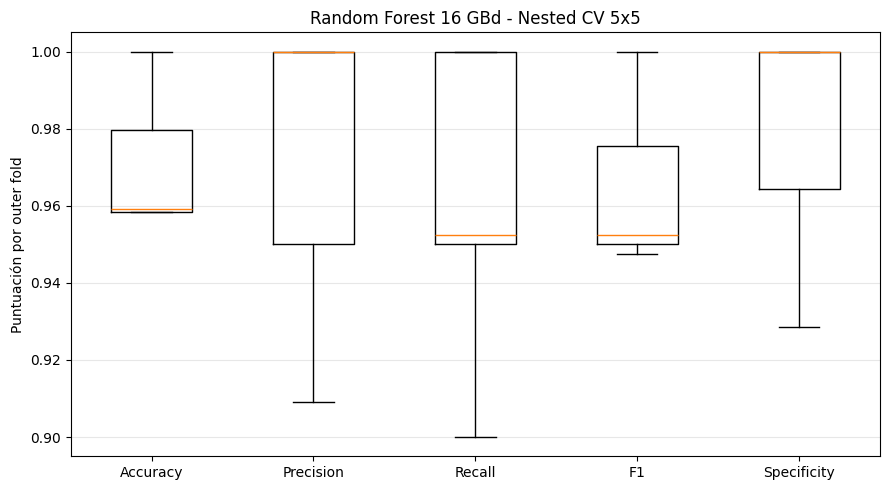


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9712
OOF Precision:   0.9703
OOF Recall:      0.9608
OOF F1:          0.9655
OOF Specificity: 0.9787

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.97      0.98      0.98       141
      ALARMA       0.97      0.96      0.97       102

    accuracy                           0.97       243
   macro avg       0.97      0.97      0.97       243
weighted avg       0.97      0.97      0.97       243


Matriz de confusión OOF:
[[138   3]
 [  4  98]]


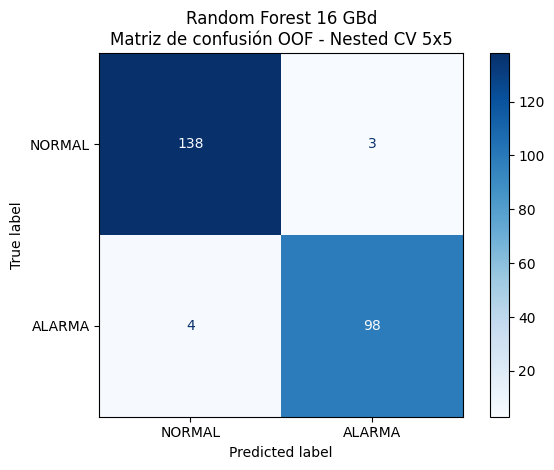


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1      None         log2                 1                  2           100          0.957454
    2      None         log2                 1                  2           400          0.955508
    3      None         log2                 1                  2           200          0.969675
    4      None         sqrt                 2                  2           200          0.957486
    5      None         log2                 1                  2           400          0.975000

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 95.134 µs/muestra
Inference Std:  39.469 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. No es latencia individual.

ENTRENANDO MODELO FINAL - RANDOM FOREST

Mejores parámetros modelo final:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split

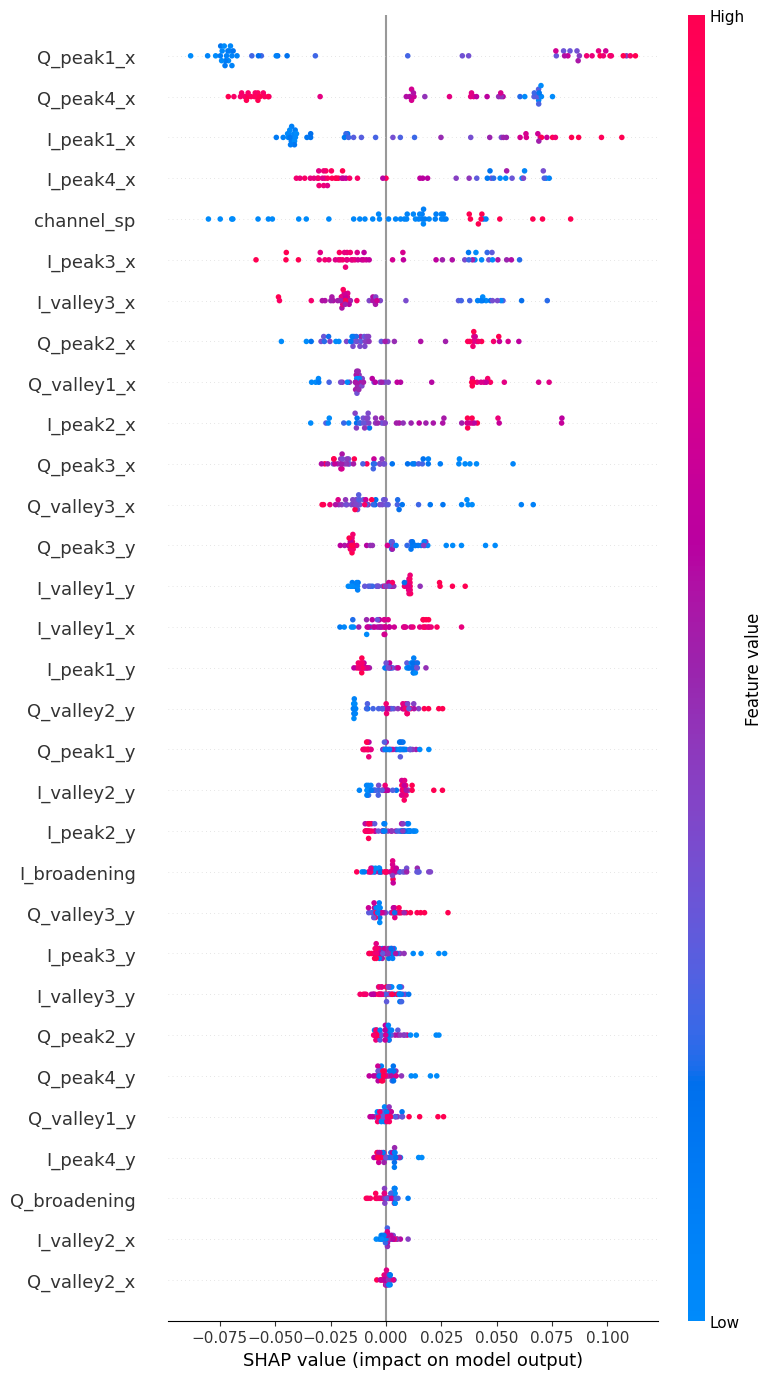

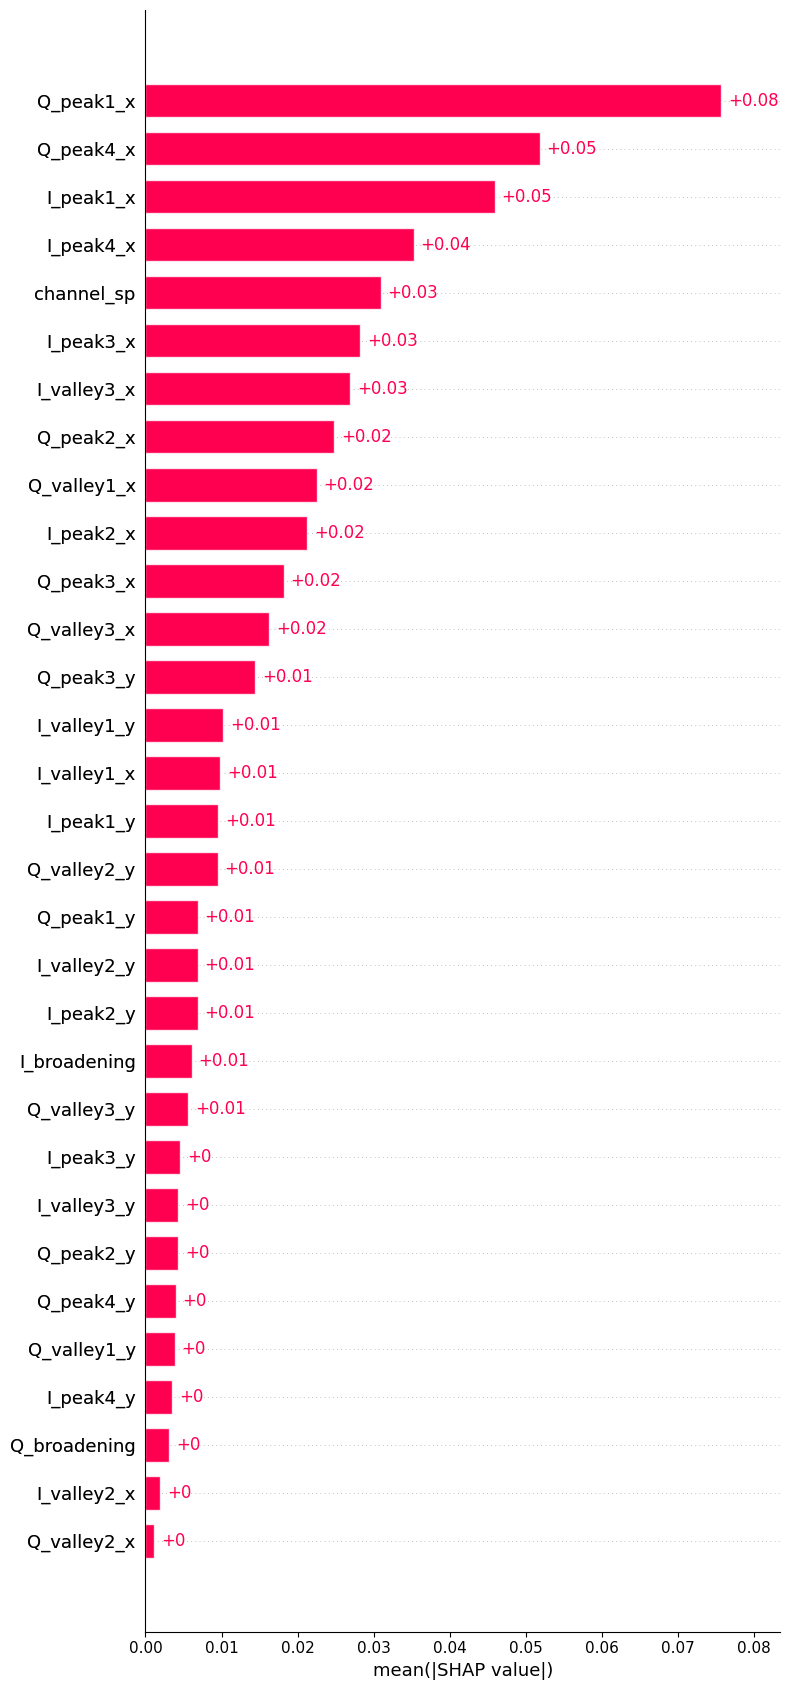

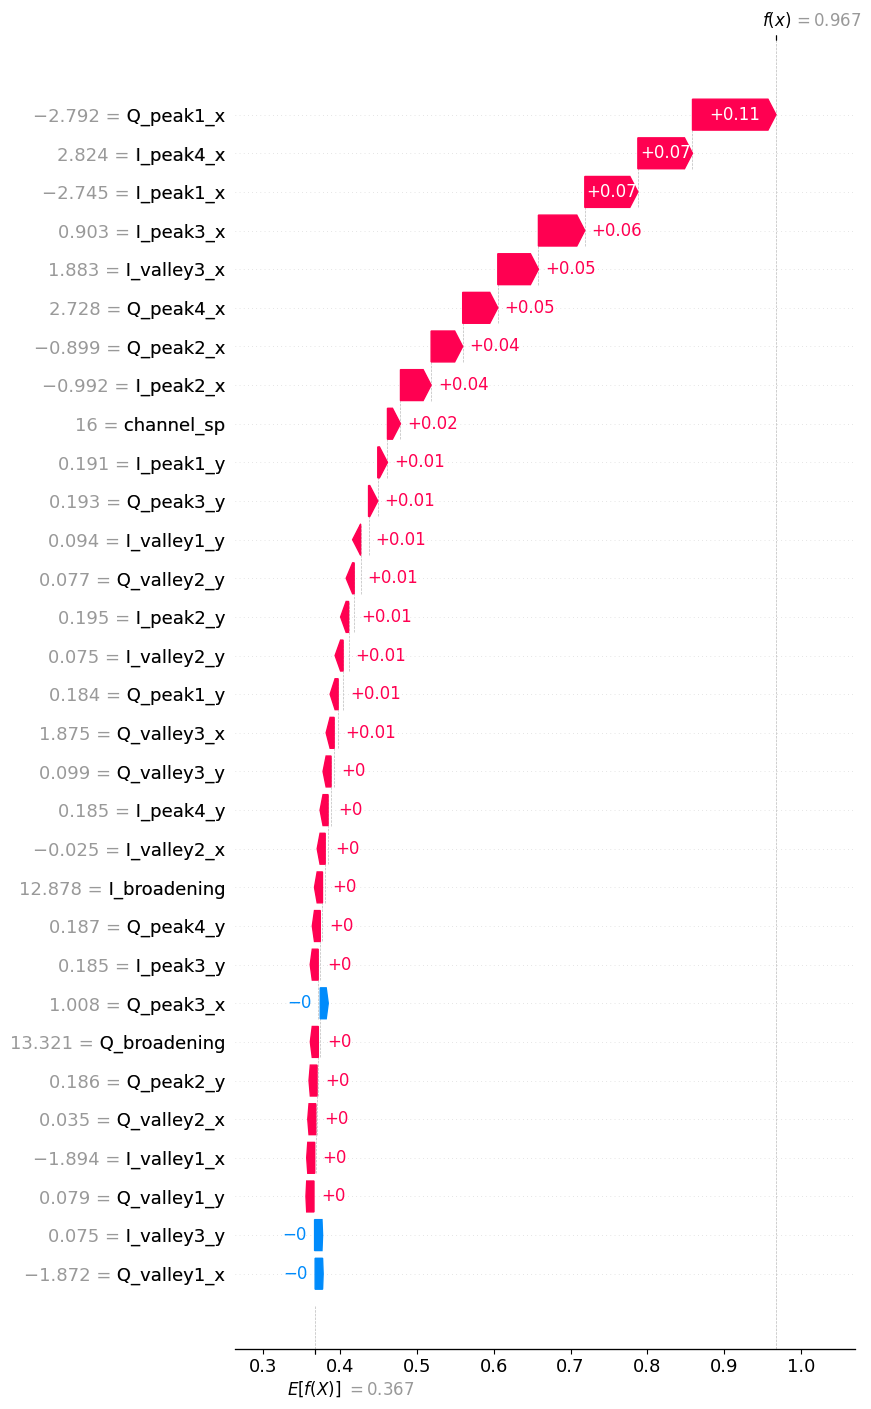


RESUMEN FINAL - RF 16 GBd NESTED CV 5x5
Outer CV Accuracy: 0.9711 ± 0.0166
Outer CV Precision: 0.9718 ± 0.0369
Outer CV Recall: 0.9605 ± 0.0373
Outer CV F1: 0.9651 ± 0.0202
Outer CV Specificity: 0.9786 ± 0.0286
OOF Accuracy: 0.9712
OOF Precision: 0.9703
OOF Recall: 0.9608
OOF F1: 0.9655
OOF Specificity: 0.9787
Inference Mean: 95.134 µs/muestra
Inference Std: 39.469 µs/muestra

Archivos generados:
1. rf_osnr_16GBd_nested_outer_folds.csv
2. rf_osnr_16GBd_nested_oof_predictions.csv
3. rf_osnr_16GBd_nested_best_params.csv
4. rf_osnr_16GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
===============================================================
CLASIFICACIÓN OSNR 16 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, SHAP Y TIEMPO DE INFERENCIA
===============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo original)

METODOLOGÍA:
    - Outer CV: 5 folds estratificados
    - Inner CV: 5 folds estratificados
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF sobre todas las muestras
    - Métricas por fold y métricas OOF globales
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todo el dataset
    - SHAP para interpretar el modelo final

IMPORTANTE:
    La CV es estratificada por filas, no por escenario.
    Si hay muestras dependientes del mismo experimento,
    considerar validación agrupada.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# =============================================================
# 1. CONFIGURACIÓN GENERAL
# =============================================================

CSV_PATH = "matriz16GBd_KDE.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# =============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# =============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# =============================================================
# 3. CARGAR Y VALIDAR DATASET
# =============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas son las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# La columna 32 contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Convertir OSNR a clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para realizar los outer folds."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: channel_sp "
    "se utiliza como característica de entrada."
)

# =============================================================
# 4. MODELO Y GRID DE HIPERPARÁMETROS
# =============================================================

def build_rf():
    """
    Crea una instancia nueva de Random Forest.

    n_jobs=1 evita paralelismo anidado:
    GridSearchCV utiliza n_jobs=-1.
    """
    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el mismo grid del código original.
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# =============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# =============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada posición corresponde a una fila del dataset.
# Se rellena únicamente cuando esa muestra está
# en el outer test de un fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Número de fold donde se evaluó cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RANDOM FOREST")
print("=" * 65)

# =============================================================
# 6. BUCLE PRINCIPAL: OUTER CV
# =============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # ---------------------------------------------------------
    # 6.1 DATOS DE ENTRENAMIENTO Y TEST EXTERNOS
    # ---------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # ---------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # ---------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # IMPORTANTE:
    # GridSearchCV solo recibe el outer train.
    # El outer test permanece completamente separado.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # ---------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # ---------------------------------------------------------

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar en las posiciones originales.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # ---------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # ---------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # ---------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # ---------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(X_outer_test)

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # ---------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS
    # ---------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# =============================================================
# 7. VERIFICAR PREDICCIONES OOF
# =============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# =============================================================
# 8. RESULTADOS POR OUTER FOLD
# =============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_16GBd_nested_outer_folds.csv",
    index=False
)

# =============================================================
# 9. PROMEDIO Y DESVIACIÓN ESTÁNDAR OUTER CV
# =============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# =============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# =============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 11. MÉTRICAS GLOBALES OOF
# =============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# =============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# =============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 13. GUARDAR PREDICCIONES OOF
# =============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_16GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# =============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# =============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_16GBd_nested_best_params.csv",
    index=False
)

# =============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# =============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "No es latencia individual."
)

# =============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# =============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RANDOM FOREST")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# =============================================================
# 17. SHAP - TREEEXPLAINER
# =============================================================

# Explicamos P(ALARMA) = P(clase 1).
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    reduce la probabilidad de ALARMA.
#
# Las muestras explicadas fueron utilizadas
# para entrenar el modelo final.
# Por eso este SHAP es descriptivo y NO OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# Diferentes versiones de SHAP devuelven:
#
# Versión antigua:
#   lista [SHAP clase 0, SHAP clase 1]
#
# Versión reciente:
#   array (n_muestras, n_features, n_clases)

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base de probabilidad ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# =============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# =============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_16GBd_nested_importancia_shap.csv",
    index=False
)

# =============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# =============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# =============================================================
# 20. GRÁFICAS SHAP
# =============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall: primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# =============================================================
# 21. RESUMEN FINAL
# =============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF 16 GBd NESTED CV 5x5")
print("=" * 65)

print(
    f"Outer CV Accuracy: "
    f"{results_df['accuracy'].mean():.4f} ± "
    f"{results_df['accuracy'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Precision: "
    f"{results_df['precision'].mean():.4f} ± "
    f"{results_df['precision'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Recall: "
    f"{results_df['recall'].mean():.4f} ± "
    f"{results_df['recall'].std(ddof=0):.4f}"
)

print(
    f"Outer CV F1: "
    f"{results_df['f1'].mean():.4f} ± "
    f"{results_df['f1'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Specificity: "
    f"{results_df['specificity'].mean():.4f} ± "
    f"{results_df['specificity'].std(ddof=0):.4f}"
)

print(
    f"OOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_16GBd_nested_outer_folds.csv")
print("2. rf_osnr_16GBd_nested_oof_predictions.csv")
print("3. rf_osnr_16GBd_nested_best_params.csv")
print("4. rf_osnr_16GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 16GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_KDE.csv
Muestras: 243
Características: 31
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - SVM 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 'scale'}
Inner CV Best F1: 0.9871

MÉTRICAS OUTER FOLD:
Accuracy:    0.9592
Precision:   1.0000
Recall:      0.9048
F1:          0.9500
Specificity: 1.0000
Inference Mean: 10.342 µs/muestra
Inference Std:  0.383 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 0.1}
Inner CV Best F1: 0.9818

MÉTRICAS OUTER FOLD:
Accuracy:    1.0000
Precision:   1.0000
Recall:      1.0000
F1:          1.0000
Specificity: 1.0000
Inference Mean: 12.084 µs/

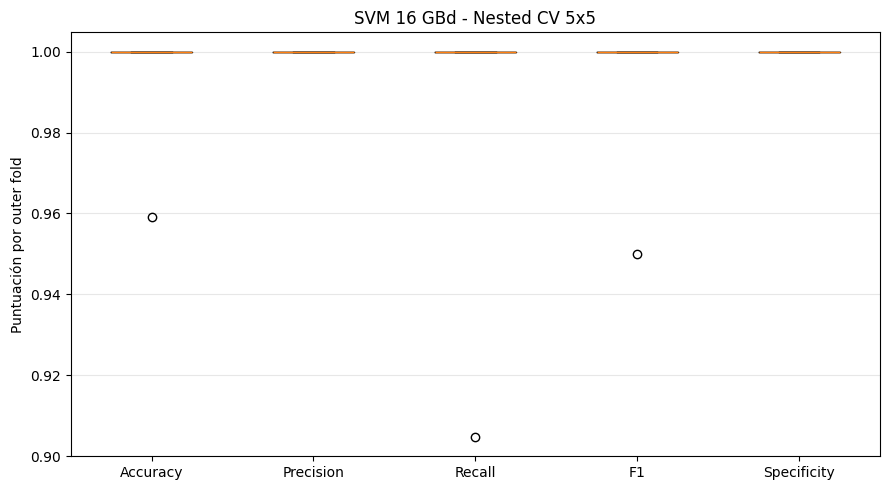


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9918
OOF Precision:   1.0000
OOF Recall:      0.9804
OOF F1:          0.9901
OOF Specificity: 1.0000

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.99      1.00      0.99       141
      ALARMA       1.00      0.98      0.99       102

    accuracy                           0.99       243
   macro avg       0.99      0.99      0.99       243
weighted avg       0.99      0.99      0.99       243


Matriz de confusión OOF:
[[141   0]
 [  2 100]]


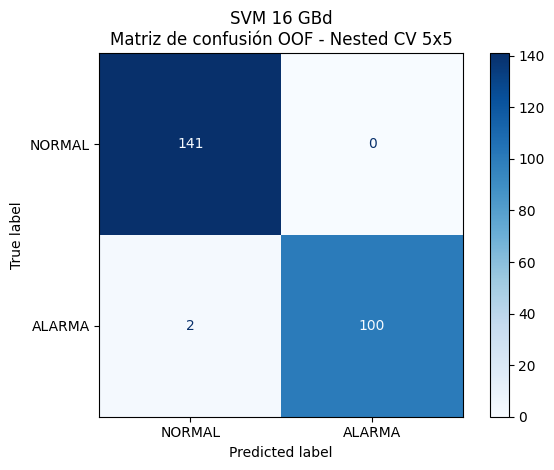


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight svm__gamma  inner_cv_best_f1
    1      10              None      scale          0.987097
    2      10              None        0.1          0.981784
    3     100              None       0.01          0.982175
    4      10              None        0.1          0.981773
    5      10              None        0.1          0.975379

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 11.311 µs/muestra
Inference Std:  1.124 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM

Mejores parámetros modelo final:
{'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 0.1}
F1 GridSearch final: 0.9860

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   Q_peak1_x      0.110962              8.91%
  channel_sp      0.102938              8.27%
   I_peak1_x      0.082245              6.61%
   I_peak4_x      0.074625              5.99%
 Q_valley3_x      0.071598              5.75%
 Q_valley1_x      0.069974              5.62%
   I_peak3_x      0.065658              5.27%
   I_peak2_x      0.060602              4.87%
   Q_peak4_x      0.058257              4.68%
   Q_peak2_x      0.051328              4.12%
 I_valley1_y      0.050665              4.07%
 I_valley3_x      0.050047              4.02%
   I_peak2_y      0.037386              3.00%
   Q_peak3_x      0.036647              2.94%
 I_valley1_x      0.033637              2.70%
   I_peak1_y      0.032457              2.61%
 Q_valley2_x      0.029805              2.39%
 Q_valley3_y      0.029706              2.39%
I_broadening      0.025415              2.04%
   Q_peak4_y      0.021741              

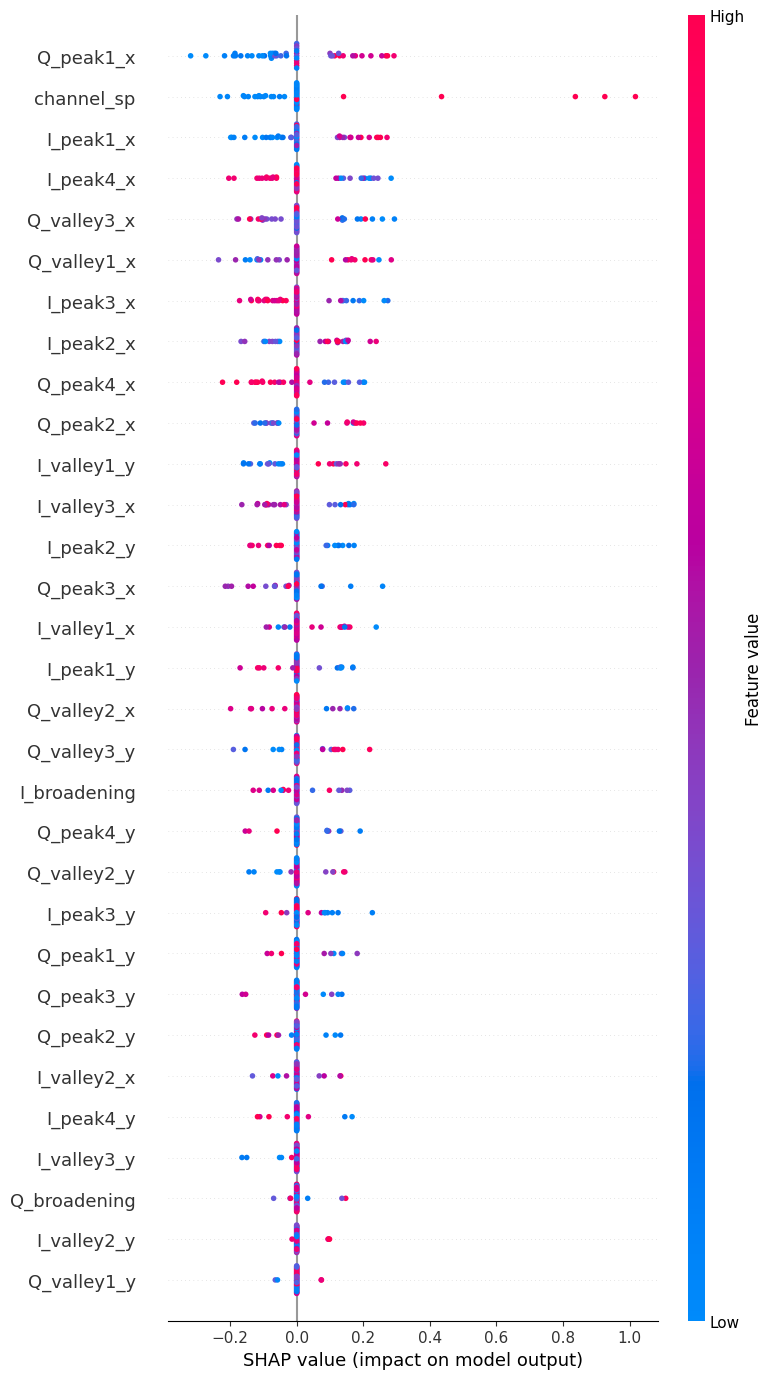

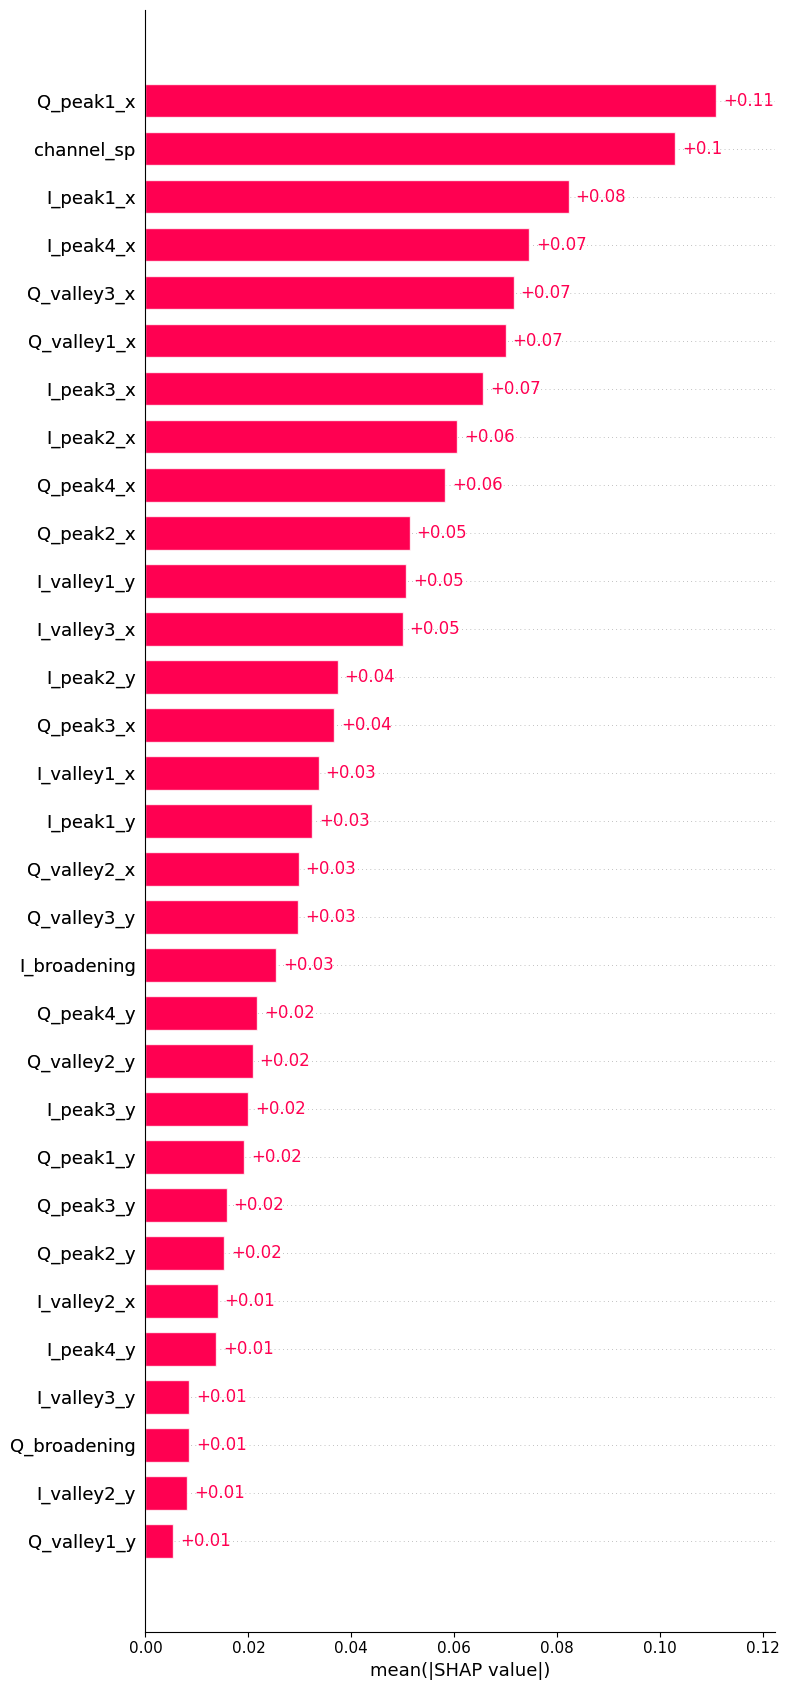

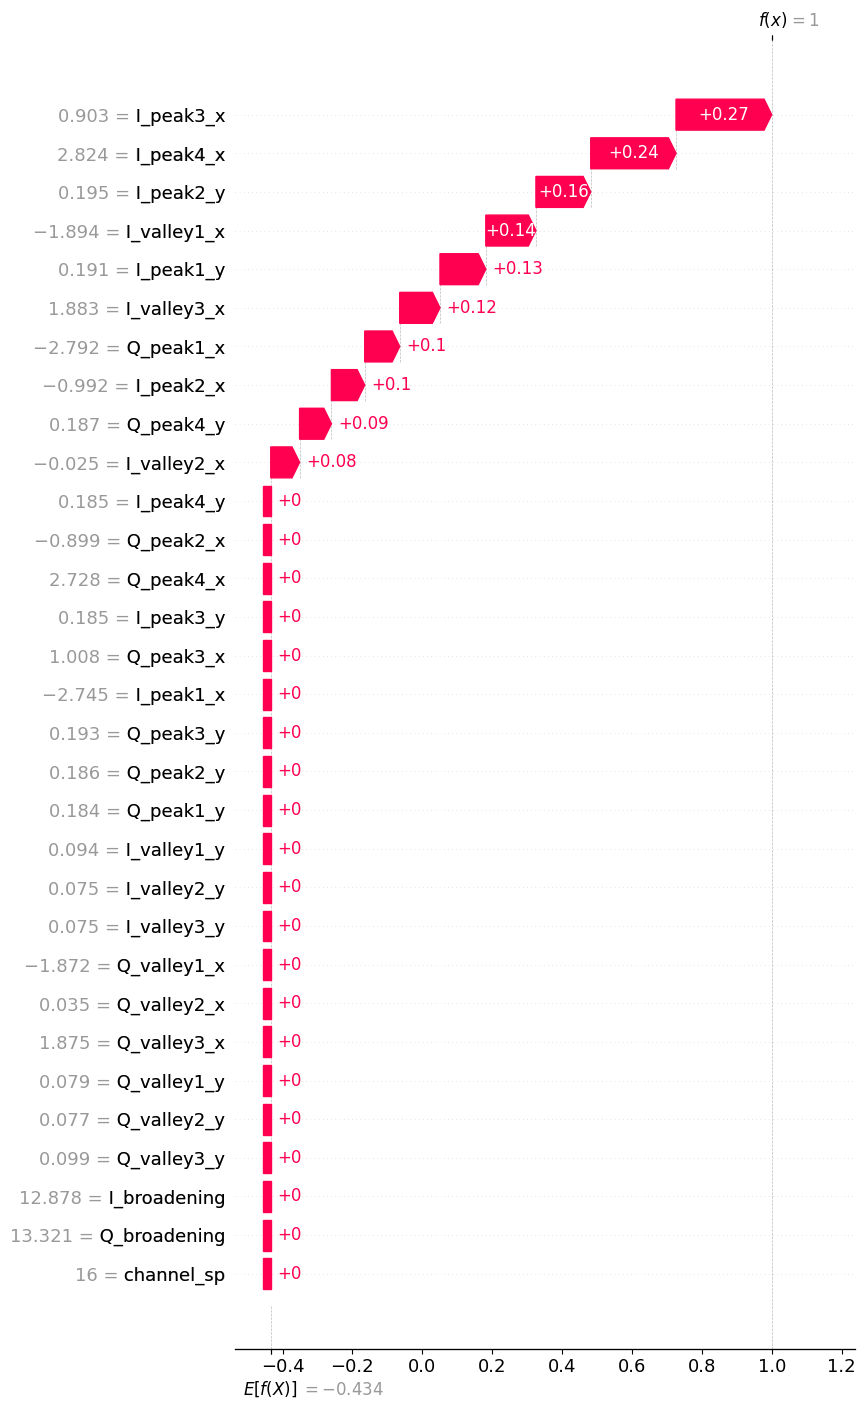


RESUMEN FINAL - SVM 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9918 ± 0.0163
Outer CV PRECISION   : 1.0000 ± 0.0000
Outer CV RECALL      : 0.9810 ± 0.0381
Outer CV F1          : 0.9900 ± 0.0200
Outer CV SPECIFICITY : 1.0000 ± 0.0000

OOF Accuracy: 0.9918
OOF Precision: 1.0000
OOF Recall: 0.9804
OOF F1: 0.9901
OOF Specificity: 1.0000

Inference Mean: 11.311 µs/muestra
Inference Std: 1.124 µs/muestra

Archivos generados:
1. svm_osnr_16GBd_nested_outer_folds.csv
2. svm_osnr_16GBd_nested_oof_predictions.csv
3. svm_osnr_16GBd_nested_best_params.csv
4. svm_osnr_16GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 16 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV en cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen realizaciones del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_KDE.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las features.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuaciones de decision_function.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearch solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_16GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_16GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_16GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_16GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_16GBd_nested_outer_folds.csv")
print("2. svm_osnr_16GBd_nested_oof_predictions.csv")
print("3. svm_osnr_16GBd_nested_best_params.csv")
print("4. svm_osnr_16GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 16GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_KDE.csv
Muestras: 243
Características: 31
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - KNN 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.9564

MÉTRICAS OUTER FOLD:
Accuracy:    0.9184
Precision:   0.9048
Recall:      0.9048
F1:          0.9048
Specificity: 0.9286
Inference Mean: 19.522 µs/muestra
Inference Std:  0.436 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.9511

MÉTRICAS OUTER FOLD:
Accuracy:    0.9592
Precision:   1.0000
Recall:      0.9048
F1:          0.9500
Specificity: 1.0000
Inference Mean: 20.286 µ

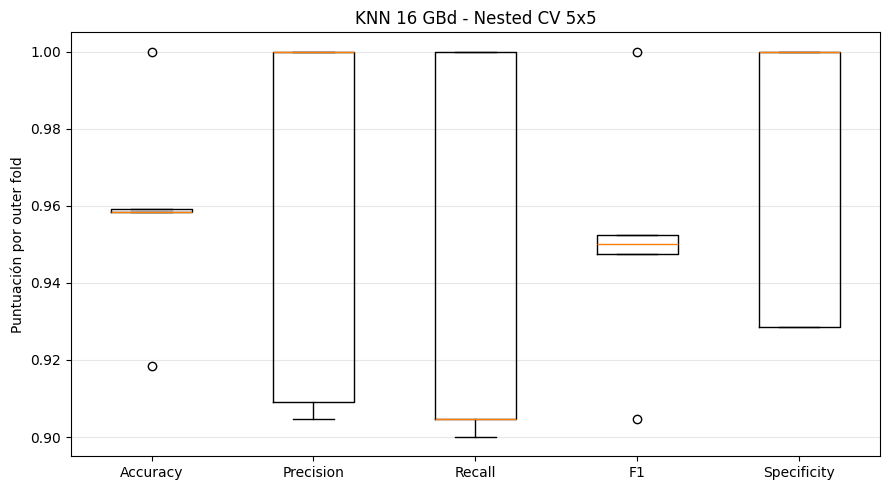


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9588
OOF Precision:   0.9600
OOF Recall:      0.9412
OOF F1:          0.9505
OOF Specificity: 0.9716

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.96      0.97      0.96       141
      ALARMA       0.96      0.94      0.95       102

    accuracy                           0.96       243
   macro avg       0.96      0.96      0.96       243
weighted avg       0.96      0.96      0.96       243


Matriz de confusión OOF:
[[137   4]
 [  6  96]]


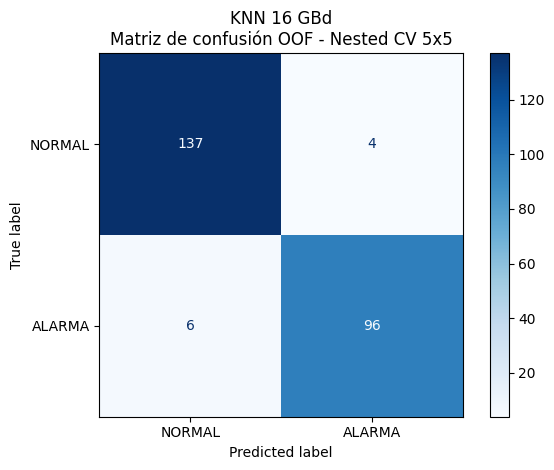


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                 5       2      uniform          0.956380
    2                 5       2      uniform          0.951092
    3                 3       1     distance          0.952509
    4                 5       2      uniform          0.970673
    5                 3       1      uniform          0.956364

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 20.019 µs/muestra
Inference Std:  1.663 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN

Mejores parámetros modelo final:
{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
F1 GridSearch final: 0.9751

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   I_peak4_x      0.034141              7.06%
  channel_sp      0.032703              6.76%
   Q_peak1_x      0.028023              5.79%
   I_peak3_x      0.027312              5.65%
 I_valley3_x      0.022471              4.65%
 Q_valley1_x      0.022283              4.61%
 Q_valley3_x      0.021739              4.49%
   Q_peak2_x      0.021222              4.39%
   Q_peak4_x      0.020888              4.32%
   Q_peak3_x      0.019194              3.97%
   I_peak2_x      0.019130              3.95%
   I_peak1_x      0.017849              3.69%
 Q_valley2_y      0.015858              3.28%
 I_valley1_y      0.013388              2.77%
   Q_peak4_y      0.013002              2.69%
   Q_peak3_y      0.011898              2.46%
   Q_peak1_y      0.011674              2.41%
 I_valley2_y      0.011651              2.41%
I_broadening      0.011246              2.33%
 I_valley3_y      0.011017              

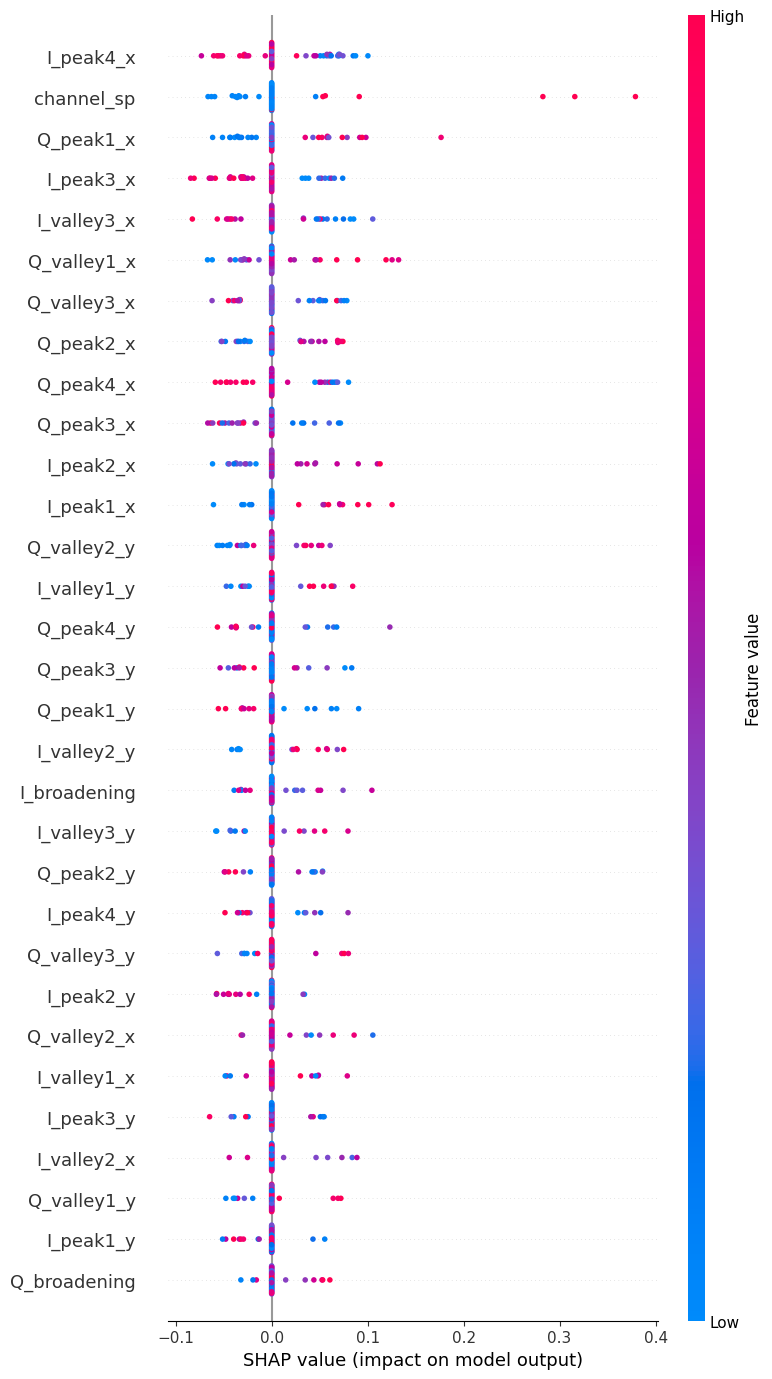

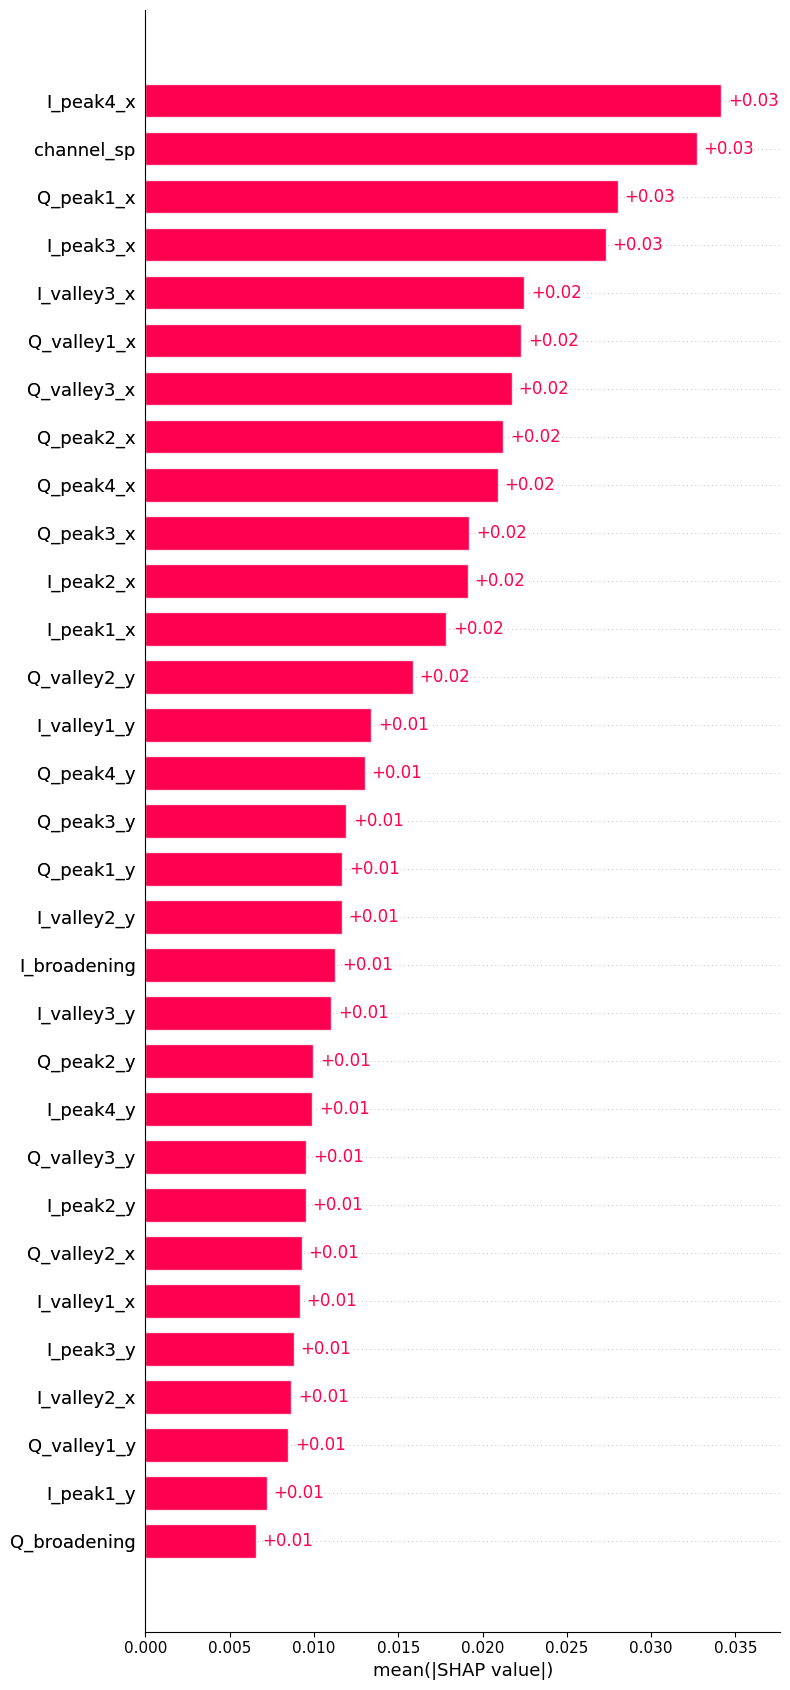

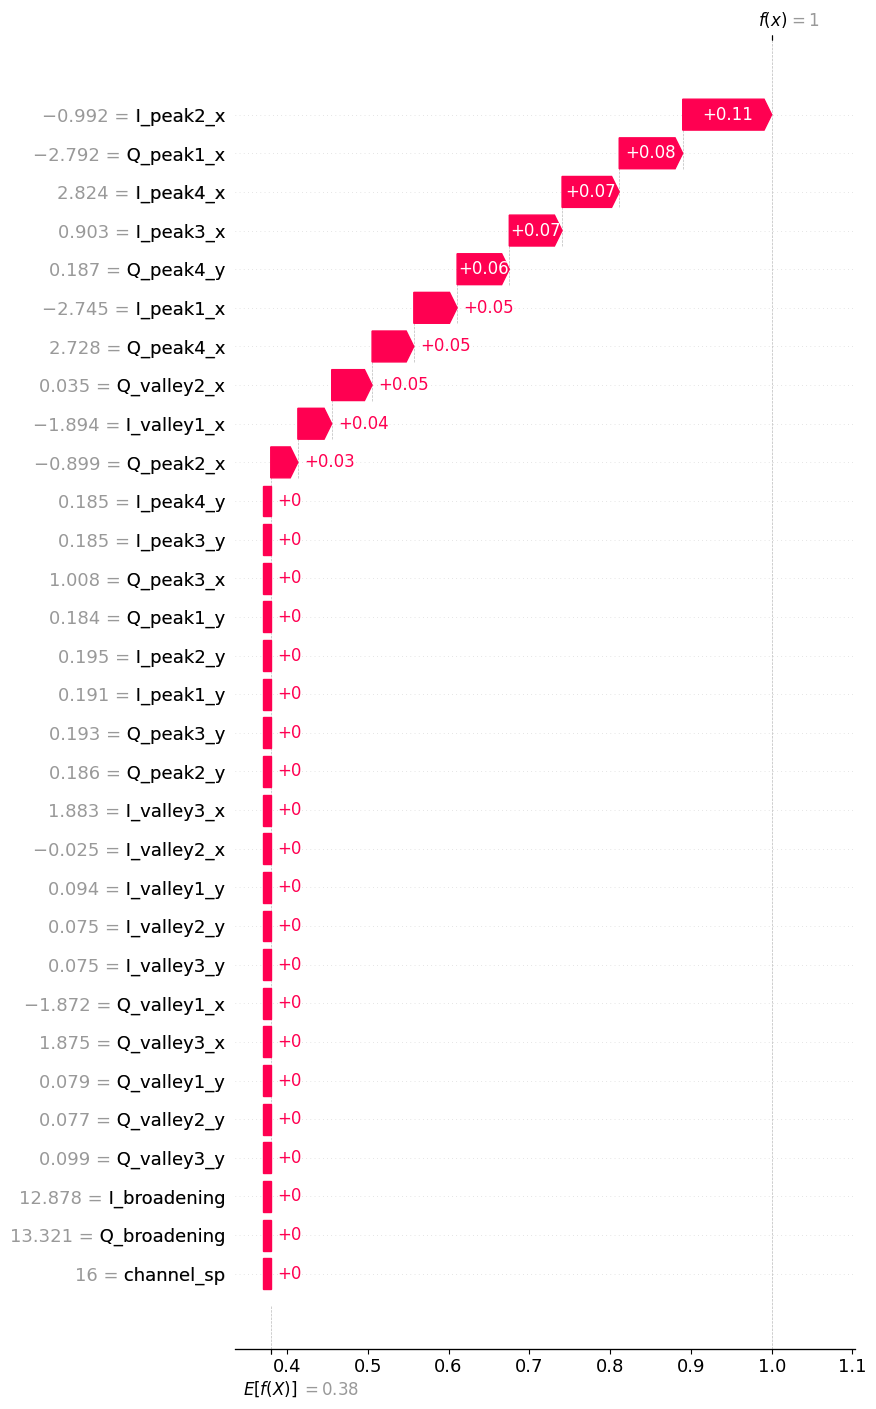


RESUMEN FINAL - KNN 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9588 ± 0.0258
Outer CV PRECISION   : 0.9628 ± 0.0456
Outer CV RECALL      : 0.9419 ± 0.0475
Outer CV F1          : 0.9509 ± 0.0302
Outer CV SPECIFICITY : 0.9714 ± 0.0350

OOF Accuracy: 0.9588
OOF Precision: 0.9600
OOF Recall: 0.9412
OOF F1: 0.9505
OOF Specificity: 0.9716

Inference Mean: 20.019 µs/muestra
Inference Std: 1.663 µs/muestra

Archivos generados:
1. knn_osnr_16GBd_nested_outer_folds.csv
2. knn_osnr_16GBd_nested_oof_predictions.csv
3. knn_osnr_16GBd_nested_best_params.csv
4. knn_osnr_16GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 16 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_KDE.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # GridSearchCV solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_16GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_16GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_16GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_16GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_16GBd_nested_outer_folds.csv")
print("2. knn_osnr_16GBd_nested_oof_predictions.csv")
print("3. knn_osnr_16GBd_nested_best_params.csv")
print("4. knn_osnr_16GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


# AHORA PARA MONITOREO CIEGO (SIN CHANNEL SPACING) PARA CLASIFICAR OSNR

## SVM 16GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_KDE.csv
Muestras: 243
Características utilizadas: 30
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 32

INICIANDO NESTED CV 5x5 - SVM CIEGO 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 'scale'}
Inner CV Best F1: 0.9681

MÉTRICAS OUT

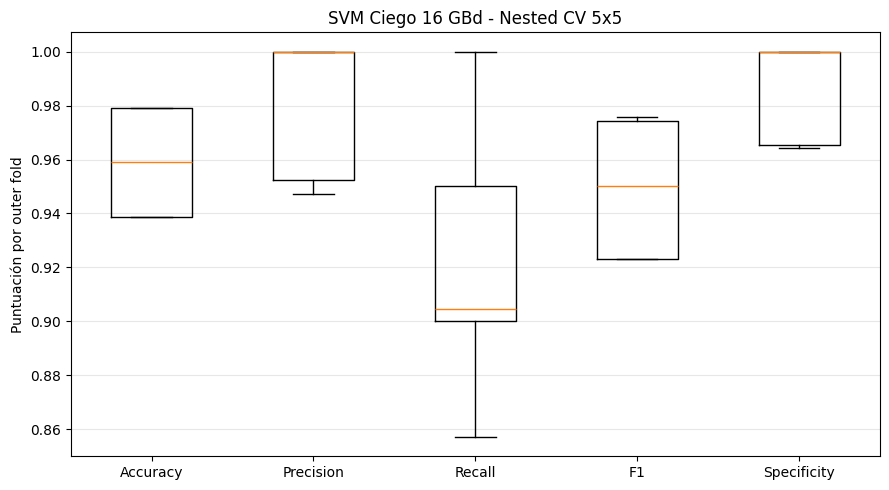


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9588
OOF Precision:   0.9792
OOF Recall:      0.9216
OOF F1:          0.9495
OOF Specificity: 0.9858

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.95      0.99      0.97       141
      ALARMA       0.98      0.92      0.95       102

    accuracy                           0.96       243
   macro avg       0.96      0.95      0.96       243
weighted avg       0.96      0.96      0.96       243


Matriz de confusión OOF:
[[139   2]
 [  8  94]]


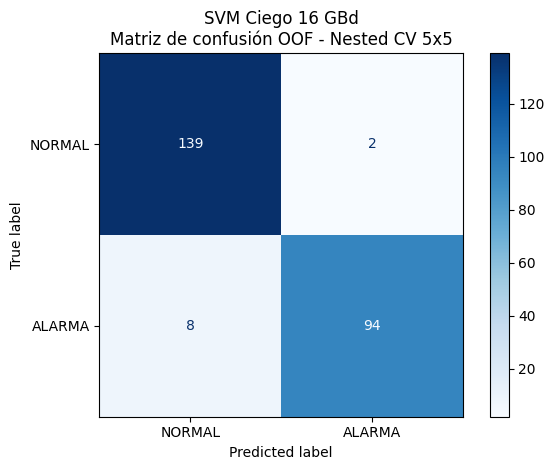


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight svm__gamma  inner_cv_best_f1
    1      10          balanced      scale          0.968145
    2      10              None      scale          0.948152
    3       1              None        0.1          0.963258
    4      10              None        0.1          0.962736
    5       1              None        0.1          0.963636

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 11.569 µs/muestra
Inference Std:  1.041 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM CIEGO

Mejores parámetros modelo final:
{'svm__C': 1, 'svm__class_weight': 'balanced', 'svm__gamma': 0.1}
F1 GridSearch final: 0.9613

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   Q_peak1_x      0.089697              8.61%
   Q_peak4_x      0.083758              8.04%
   I_peak3_x      0.078436              7.53%
 Q_valley1_x      0.073768              7.08%
   Q_peak3_x      0.056882              5.46%
 Q_valley3_x      0.056482              5.42%
   I_peak4_x      0.055162              5.29%
   I_peak1_x      0.054815              5.26%
 I_valley3_x      0.049617              4.76%
   Q_peak2_x      0.044683              4.29%
   I_peak2_x      0.038761              3.72%
 Q_valley2_x      0.029567              2.84%
 I_valley1_y      0.025771              2.47%
 I_valley1_x      0.024941              2.39%
   Q_peak1_y      0.024629              2.36%
   I_peak1_y      0.023736              2.28%
I_broadening      0.023659              2.27%
   Q_peak3_y      0.022554              2.16%
   I_peak2_y      0.022388              2.15%
 Q_valley3_y      0.021077              

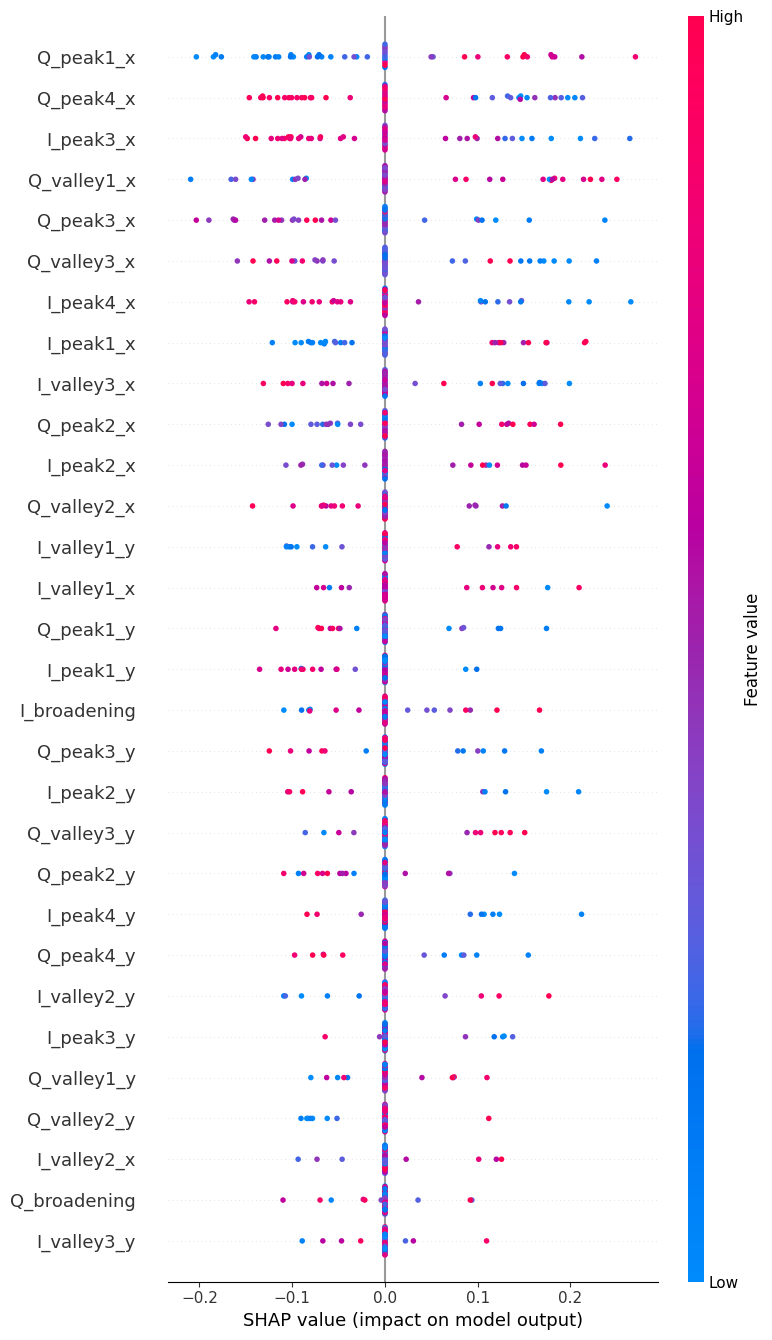

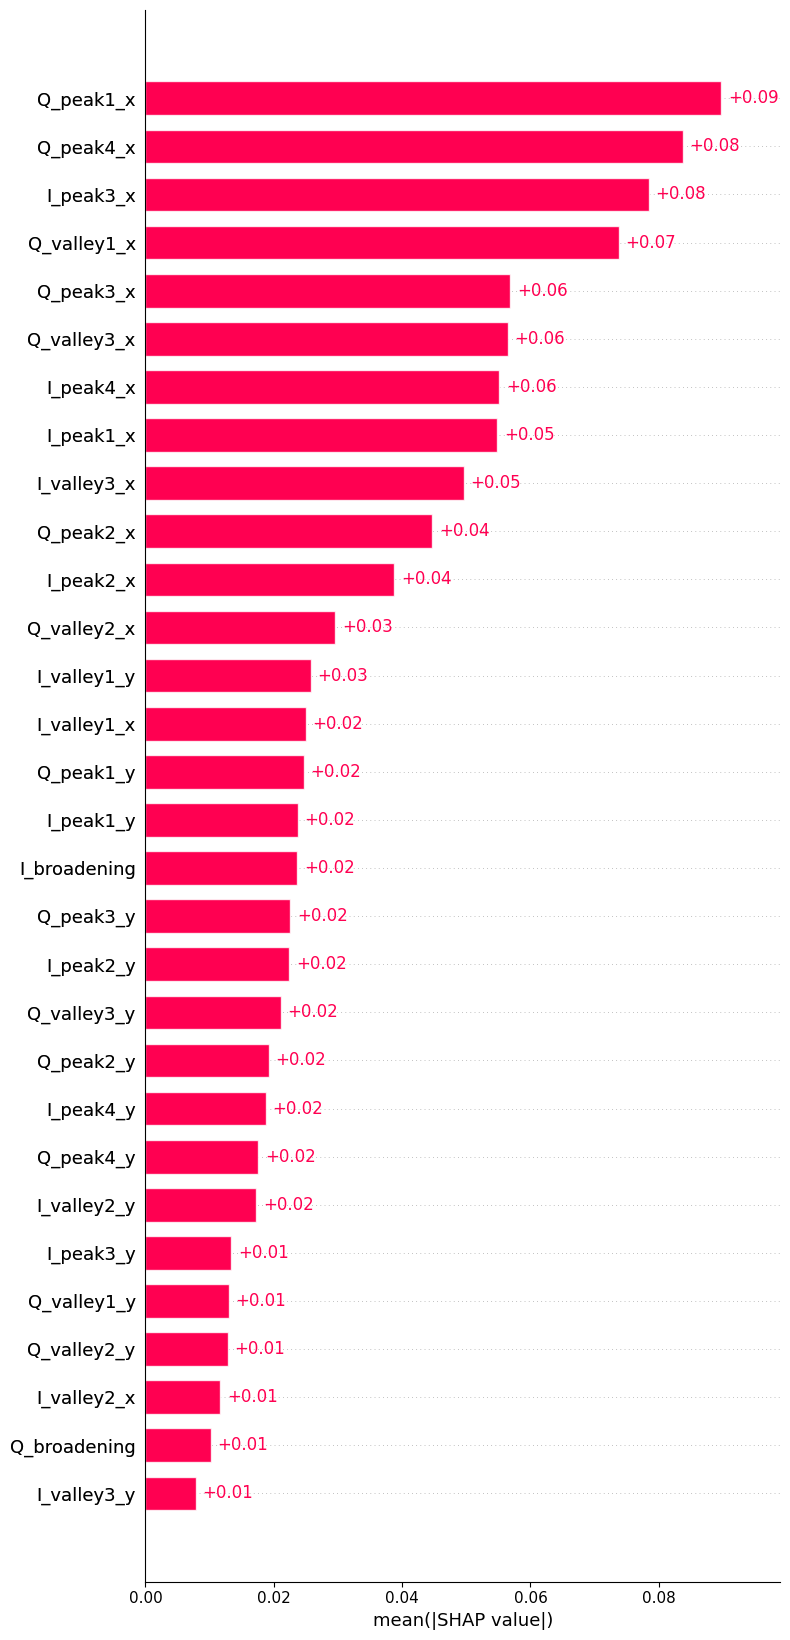

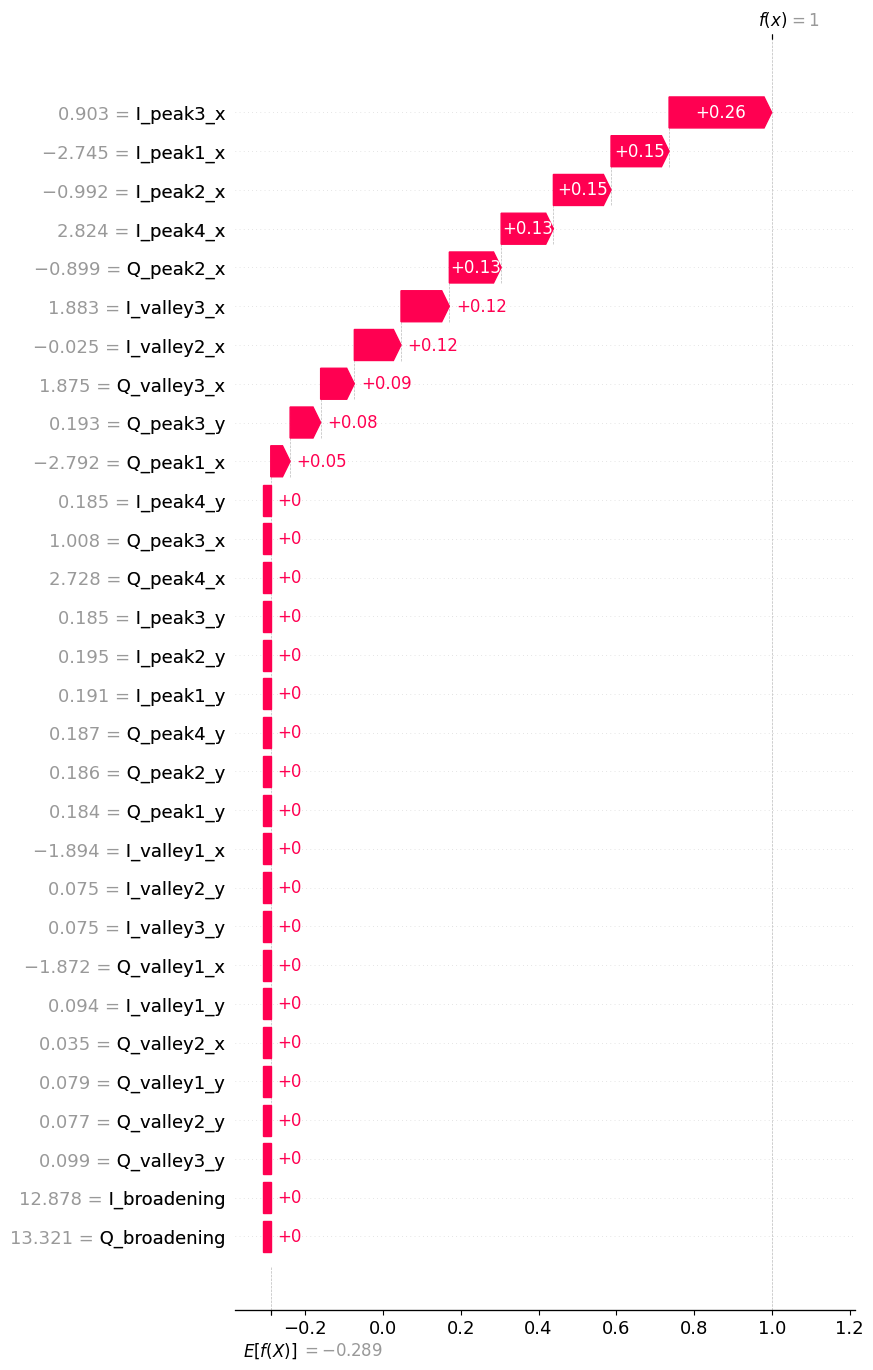


RESUMEN FINAL - SVM CIEGO 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9590 ± 0.0181
Outer CV PRECISION   : 0.9799 ± 0.0246
Outer CV RECALL      : 0.9224 ± 0.0487
Outer CV F1          : 0.9492 ± 0.0232
Outer CV SPECIFICITY : 0.9860 ± 0.0172

OOF Accuracy: 0.9588
OOF Precision: 0.9792
OOF Recall: 0.9216
OOF F1: 0.9495
OOF Specificity: 0.9858

Inference Mean: 11.569 µs/muestra
Inference Std: 1.041 µs/muestra

Archivos generados:
1. svm_osnr_16GBd_ciego_nested_outer_folds.csv
2. svm_osnr_16GBd_ciego_nested_oof_predictions.csv
3. svm_osnr_16GBd_ciego_nested_best_params.csv
4. svm_osnr_16GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 16 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_KDE.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

n_combinations = (
    len(param_grid["svm__C"]) *
    len(param_grid["svm__gamma"]) *
    len(param_grid["svm__class_weight"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuación de decision_function para cada muestra OOF.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM CIEGO 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Puntuación de decisión del SVM.
    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM Ciego 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Ciego 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve la función de decisión del SVM.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM CIEGO 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_16GBd_ciego_nested_outer_folds.csv")
print("2. svm_osnr_16GBd_ciego_nested_oof_predictions.csv")
print("3. svm_osnr_16GBd_ciego_nested_best_params.csv")
print("4. svm_osnr_16GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## RDF 16GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_KDE.csv
Muestras: 243
Características utilizadas: 30
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RF CIEGO 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 10

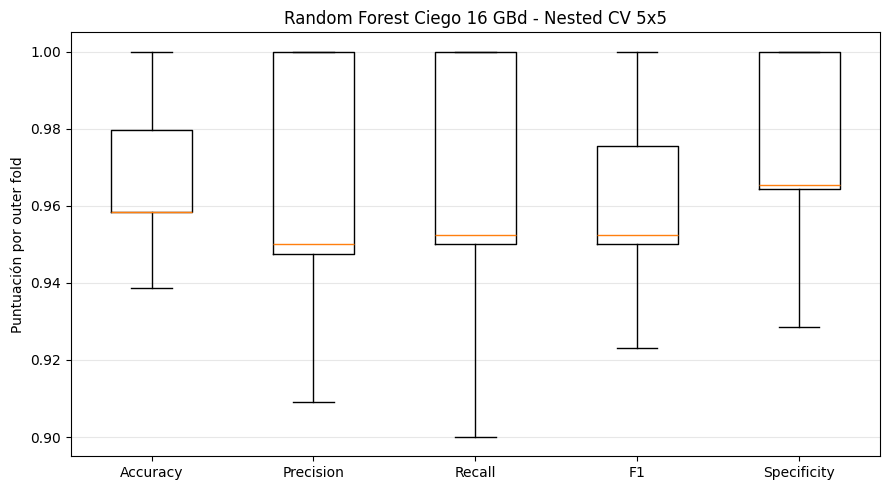


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9671
OOF Precision:   0.9608
OOF Recall:      0.9608
OOF F1:          0.9608
OOF Specificity: 0.9716

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.97      0.97      0.97       141
      ALARMA       0.96      0.96      0.96       102

    accuracy                           0.97       243
   macro avg       0.97      0.97      0.97       243
weighted avg       0.97      0.97      0.97       243


Matriz de confusión OOF:
[[137   4]
 [  4  98]]


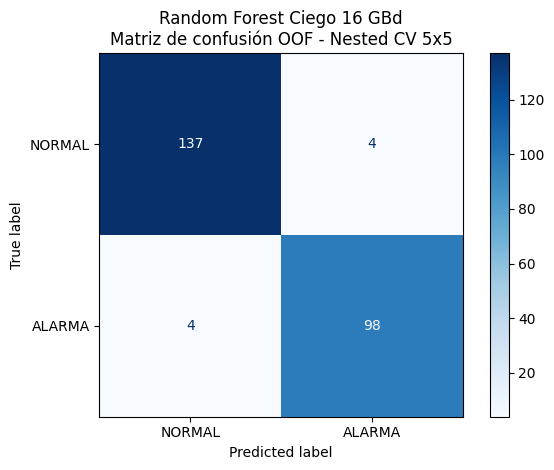


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1      None         sqrt                 1                  2           100          0.957150
    2      None         log2                 1                  2           400          0.950664
    3      None         sqrt                 1                  5           100          0.963993
    4      None         sqrt                 1                  5           100          0.962834
    5      None         sqrt                 1                  2           100          0.969697

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 62.269 µs/muestra
Inference Std:  38.608 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye RandomForest.predict().

ENTRENANDO MODELO FINAL - RF CIEGO

Mejores parámetros modelo final:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split

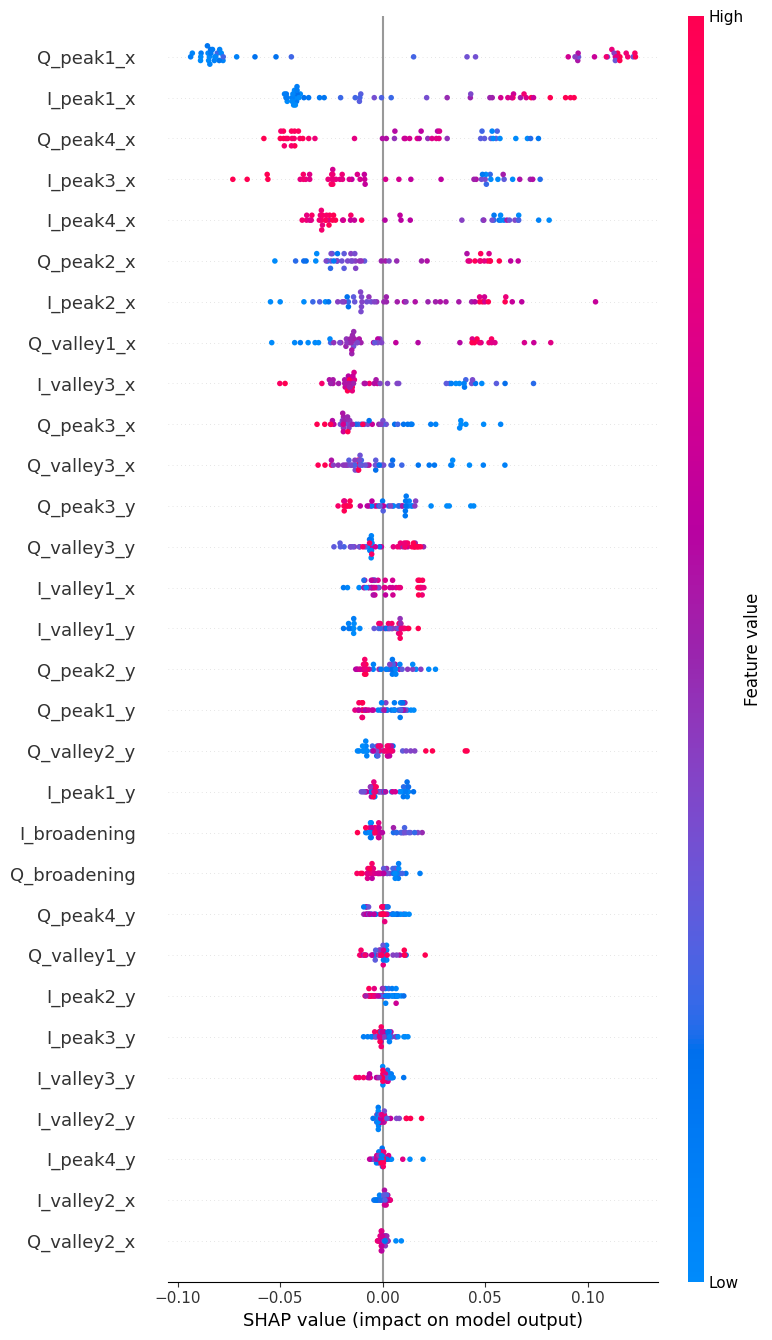

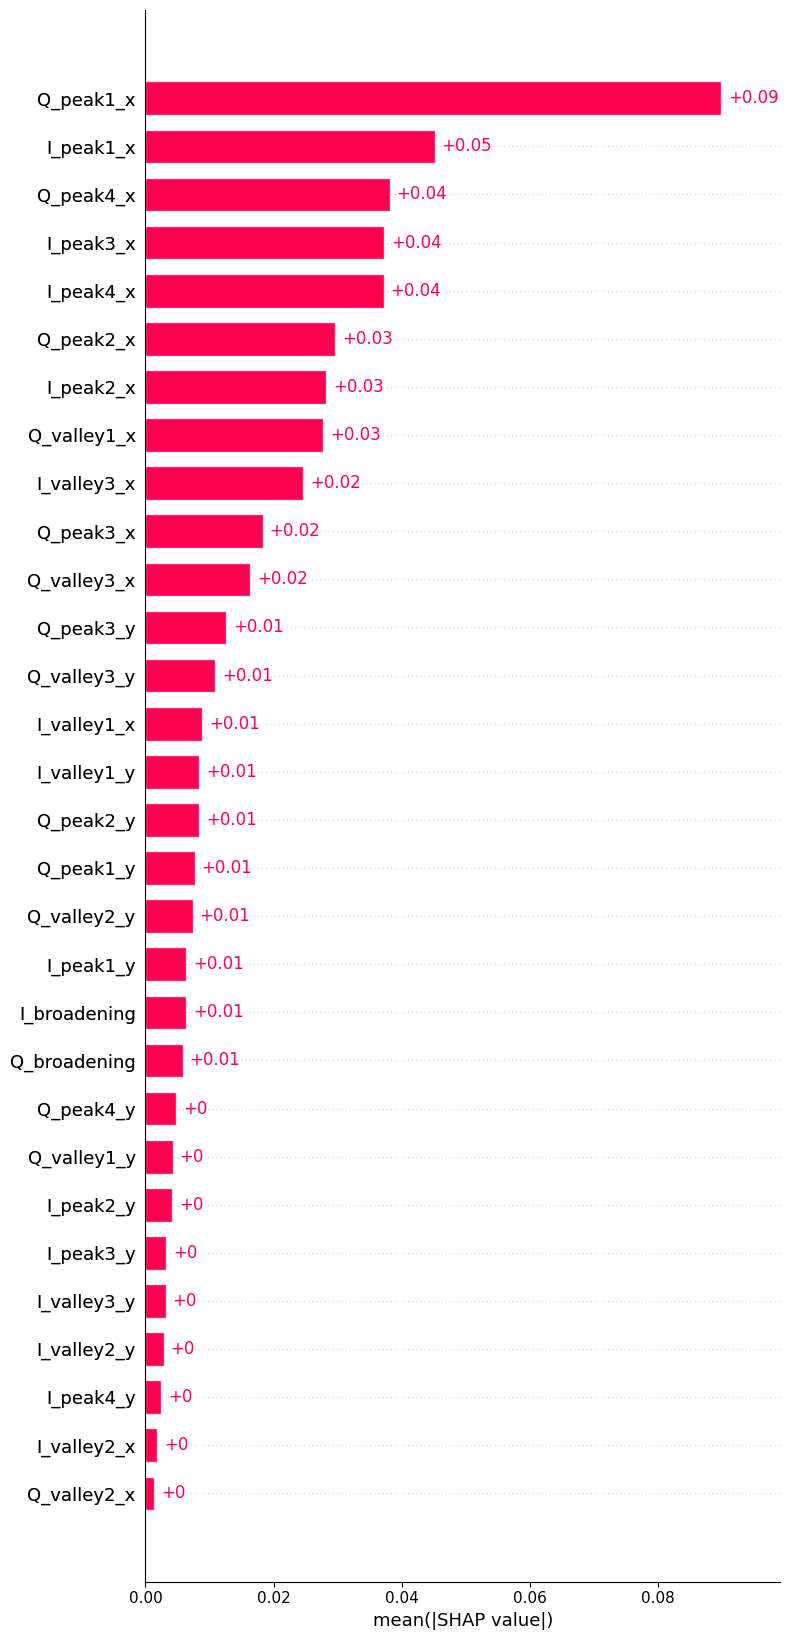

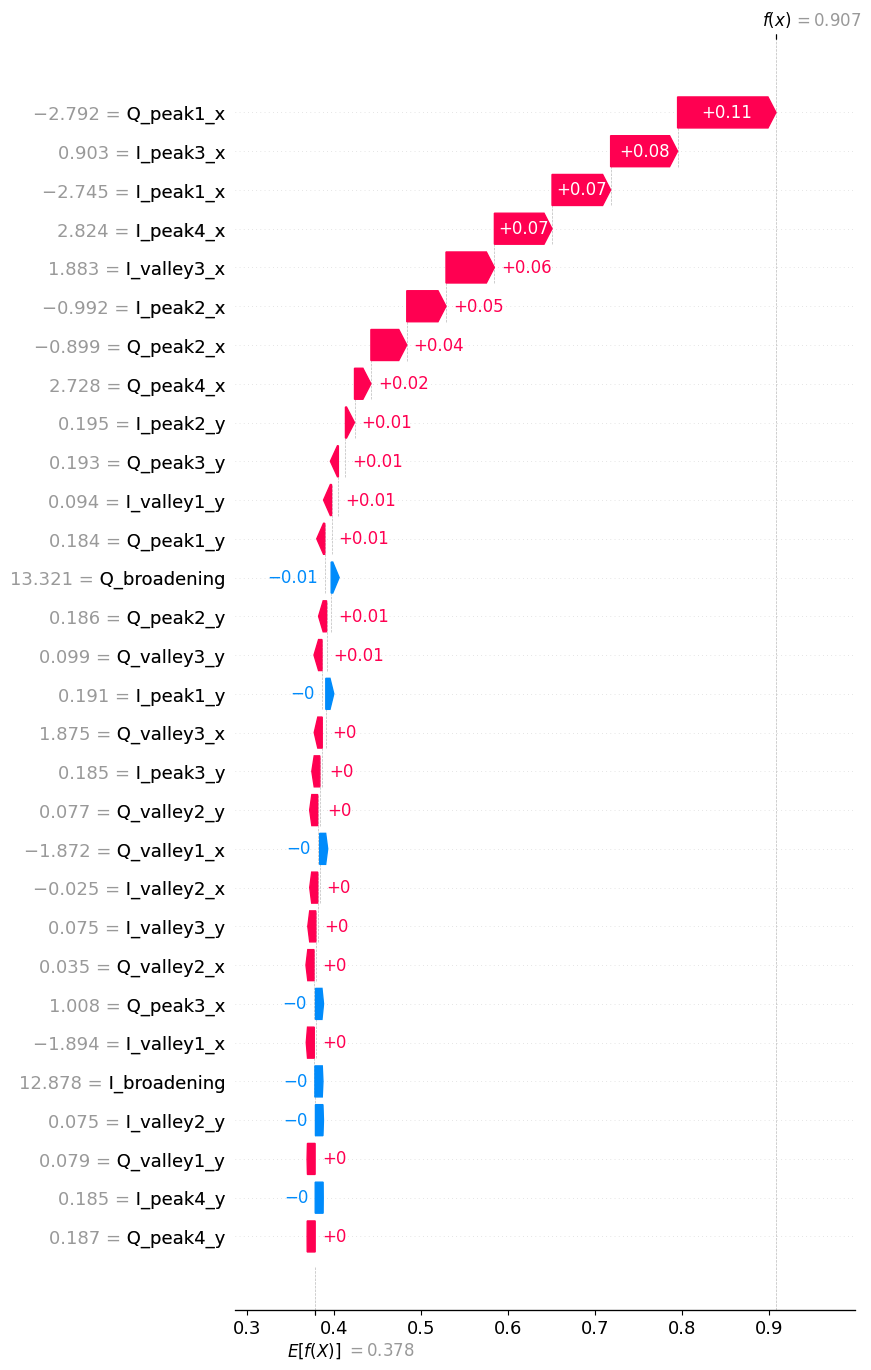


RESUMEN FINAL - RF CIEGO 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9670 ± 0.0209
Outer CV PRECISION   : 0.9613 ± 0.0348
Outer CV RECALL      : 0.9605 ± 0.0373
Outer CV F1          : 0.9602 ± 0.0259
Outer CV SPECIFICITY : 0.9717 ± 0.0267

OOF Accuracy: 0.9671
OOF Precision: 0.9608
OOF Recall: 0.9608
OOF F1: 0.9608
OOF Specificity: 0.9716

Inference Mean: 62.269 µs/muestra
Inference Std: 38.608 µs/muestra

Archivos generados:
1. rf_osnr_16GBd_ciego_nested_outer_folds.csv
2. rf_osnr_16GBd_ciego_nested_oof_predictions.csv
3. rf_osnr_16GBd_ciego_nested_best_params.csv
4. rf_osnr_16GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 16 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_KDE.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR RANDOM FOREST Y GRID
# ============================================================

def build_model():
    """
    Construye un Random Forest nuevo.

    No requiere StandardScaler.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el grid del código original.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RF CIEGO 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_model(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest Ciego 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Ciego 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye RandomForest.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RF CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_model(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - TREEEXPLAINER
# ============================================================

# TreeExplainer explica predict_proba[:, 1].
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# SHAP puede devolver:
# 1. Una lista [clase 0, clase 1].
# 2. Un arreglo (muestras, características, clases).
#
# Se extraen los valores correspondientes a ALARMA.

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    shap_values = (
        arr[:, :, 1]
        if arr.ndim == 3 and arr.shape[2] == 2
        else arr
    )

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base correspondiente a ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF CIEGO 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_16GBd_ciego_nested_outer_folds.csv")
print("2. rf_osnr_16GBd_ciego_nested_oof_predictions.csv")
print("3. rf_osnr_16GBd_ciego_nested_best_params.csv")
print("4. rf_osnr_16GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 16GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_KDE.csv
Muestras: 243
Características utilizadas: 30
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 20

INICIANDO NESTED CV 5x5 - KNN CIEGO 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.9495

MÉTRICAS OUTER FOLD

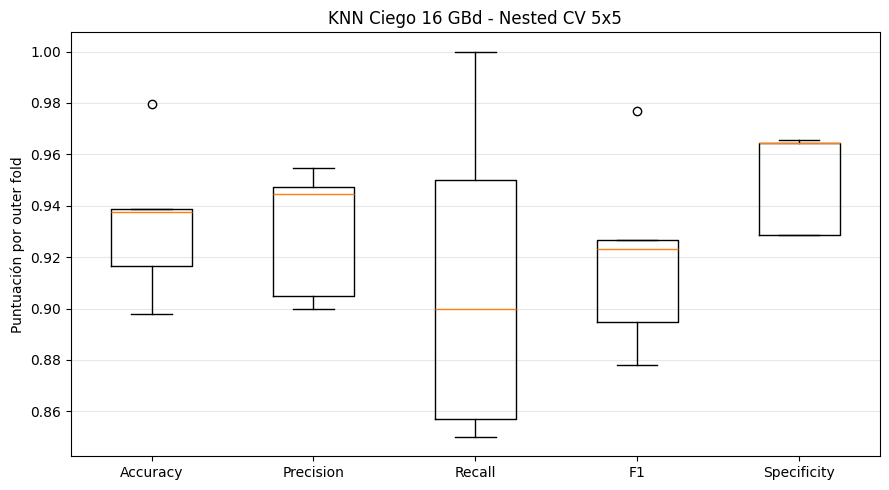


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9342
OOF Precision:   0.9300
OOF Recall:      0.9118
OOF F1:          0.9208
OOF Specificity: 0.9504

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.94      0.95      0.94       141
      ALARMA       0.93      0.91      0.92       102

    accuracy                           0.93       243
   macro avg       0.93      0.93      0.93       243
weighted avg       0.93      0.93      0.93       243


Matriz de confusión OOF:
[[134   7]
 [  9  93]]


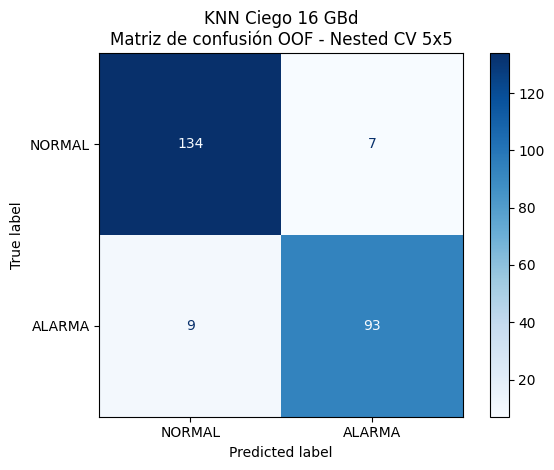


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                 5       2      uniform          0.949499
    2                 3       1      uniform          0.918477
    3                11       2     distance          0.936114
    4                 5       2      uniform          0.937980
    5                 3       1      uniform          0.937781

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 22.556 µs/muestra
Inference Std:  1.586 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN CIEGO

Mejores parámetros modelo final:
{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
F1 GridSearch final: 0.9402

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   I_peak3_x      0.033813              7.41%
   I_peak1_x      0.031307              6.86%
   I_peak4_x      0.026881              5.89%
   Q_peak1_x      0.025409              5.57%
 I_valley3_x      0.024335              5.33%
   Q_peak2_x      0.024194              5.30%
 Q_valley1_x      0.021220              4.65%
   Q_peak3_x      0.020355              4.46%
   I_peak2_x      0.020160              4.42%
 Q_valley3_x      0.018918              4.15%
   Q_peak4_x      0.018177              3.98%
   Q_peak4_y      0.015558              3.41%
   I_peak1_y      0.015176              3.33%
 I_valley1_x      0.014039              3.08%
 I_valley3_y      0.013728              3.01%
I_broadening      0.012916              2.83%
 Q_valley2_x      0.012149              2.66%
 I_valley1_y      0.012129              2.66%
   I_peak2_y      0.010611              2.33%
 I_valley2_y      0.010252              

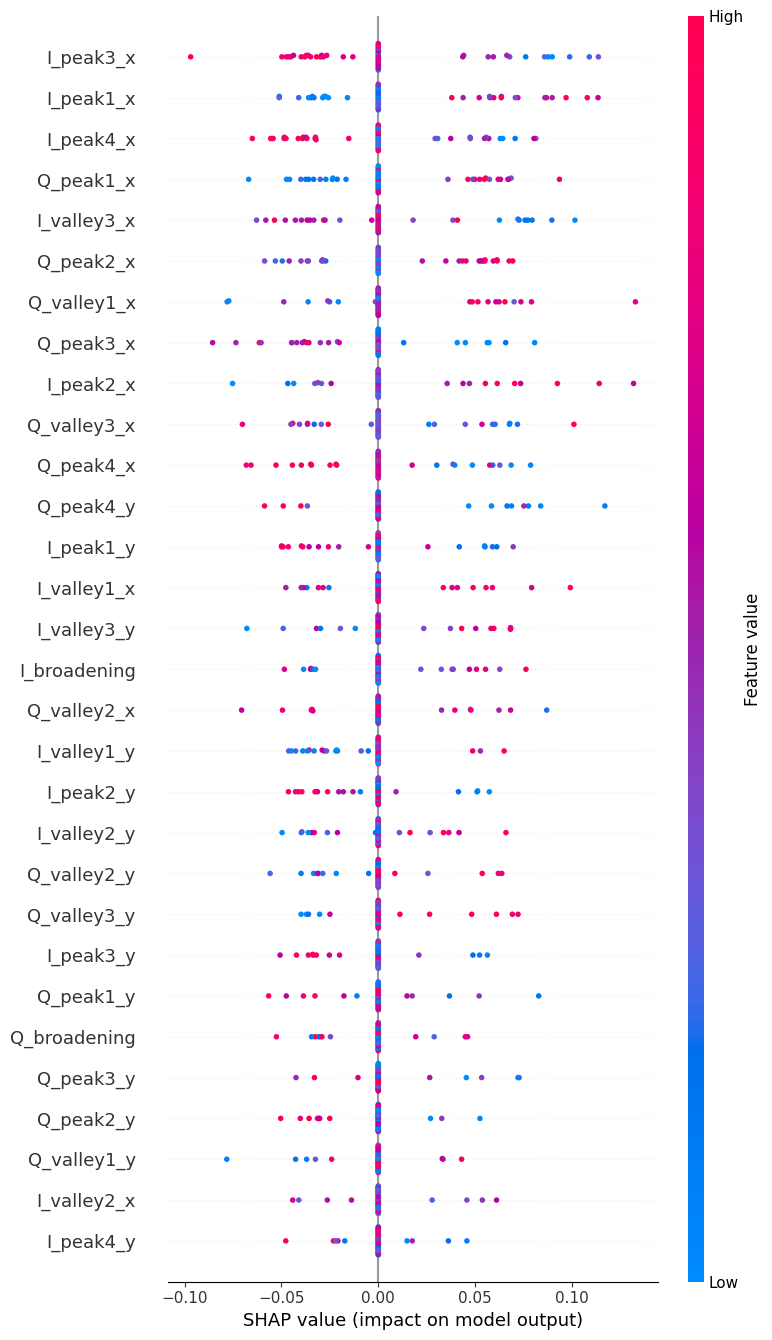

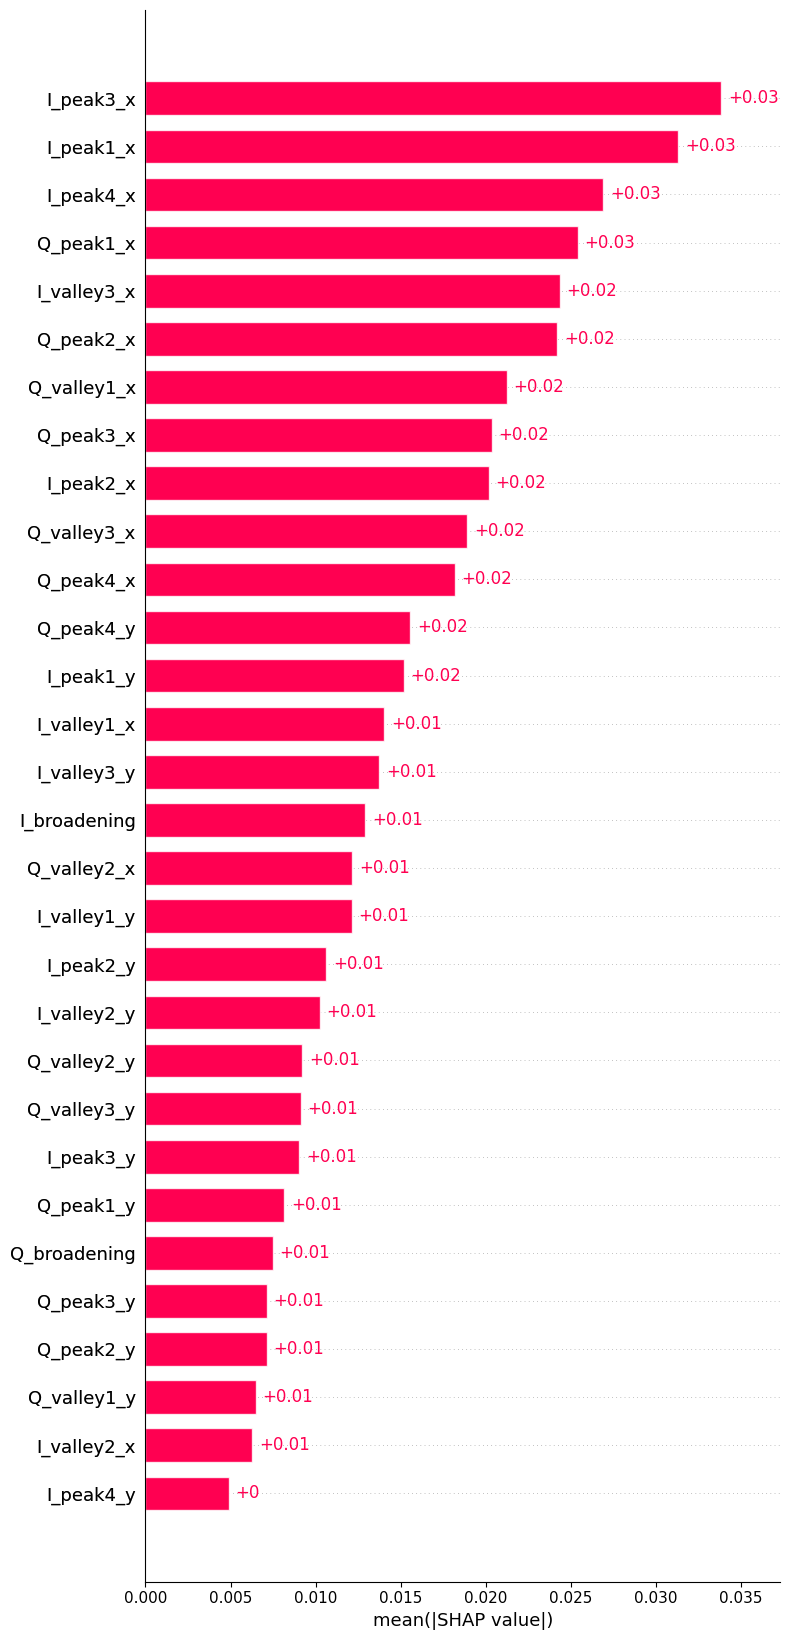

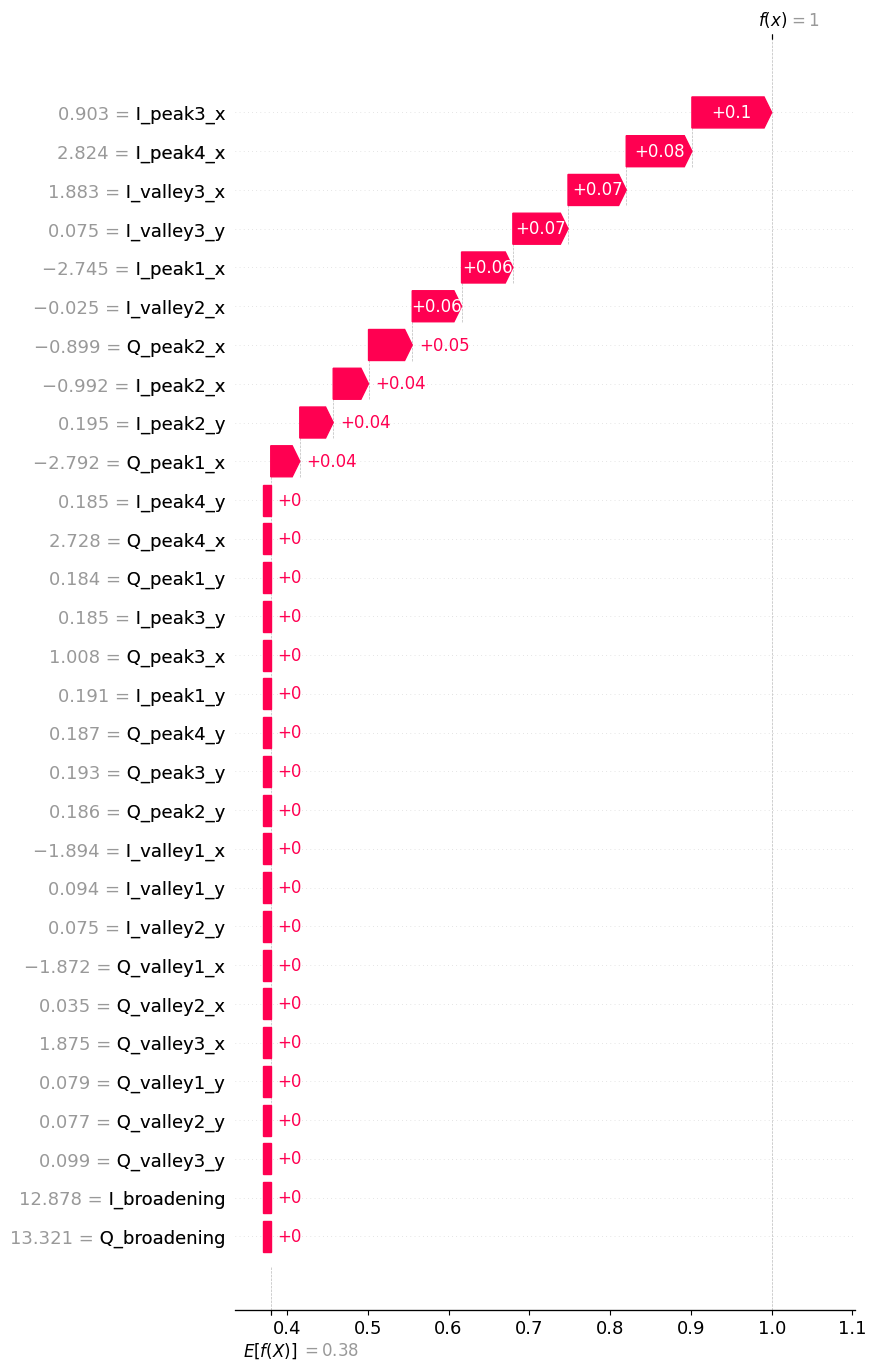


RESUMEN FINAL - KNN CIEGO 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9341 ± 0.0273
Outer CV PRECISION   : 0.9302 ± 0.0230
Outer CV RECALL      : 0.9114 ± 0.0569
Outer CV F1          : 0.9199 ± 0.0337
Outer CV SPECIFICITY : 0.9502 ± 0.0177

OOF Accuracy: 0.9342
OOF Precision: 0.9300
OOF Recall: 0.9118
OOF F1: 0.9208
OOF Specificity: 0.9504

Inference Mean: 22.556 µs/muestra
Inference Std: 1.586 µs/muestra

Archivos generados:
1. knn_osnr_16GBd_ciego_nested_outer_folds.csv
2. knn_osnr_16GBd_ciego_nested_oof_predictions.csv
3. knn_osnr_16GBd_ciego_nested_best_params.csv
4. knn_osnr_16GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 16 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_KDE.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

n_combinations = (
    len(param_grid["knn__n_neighbors"]) *
    len(param_grid["knn__weights"]) *
    len(param_grid["knn__p"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN CIEGO 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN Ciego 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Ciego 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN CIEGO 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_16GBd_ciego_nested_outer_folds.csv")
print("2. knn_osnr_16GBd_ciego_nested_oof_predictions.csv")
print("3. knn_osnr_16GBd_ciego_nested_best_params.csv")
print("4. knn_osnr_16GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


# PRUEBAS PARA JUSTIFICAR
##Para justificar el por qué sin channel spacing la OSNR para 16GBd dio mayor a cuando es conocida

In [ ]:
import numpy as np
import pandas as pd

from scipy.stats import binomtest
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

CSV_PATH = "matriz16GBd_clas.csv"
SEED = 42

matriz = pd.read_csv(CSV_PATH, header=None)
if matriz.shape[1] != 32:
    raise ValueError("Se esperan 32 columnas: 31 características + OSNR")

# Conservamos los índices de fila para identificar los casos que cambian.
indices = np.arange(len(matriz))
y = (matriz.iloc[:, 31].to_numpy() <= 23.0).astype(int)

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

predicciones = {}

for nombre, n_features in [
    ("ciego", 30),
    ("con_spacing", 31),
]:
    X = matriz.iloc[:, :n_features]

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    busqueda = GridSearchCV(
        modelo,
        param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    busqueda.fit(X.iloc[idx_train], y[idx_train])
    predicciones[nombre] = busqueda.predict(X.iloc[idx_test])

    print(f"\n{nombre.upper()}")
    print("Mejores parámetros:", busqueda.best_params_)
    print(
        "Accuracy test:",
        accuracy_score(y[idx_test], predicciones[nombre])
    )
    print(
        "Matriz de confusión:\n",
        confusion_matrix(
            y[idx_test],
            predicciones[nombre],
            labels=[0, 1]
        )
    )

comparacion = pd.DataFrame({
    "fila_original_csv": idx_test,
    "OSNR_dB": matriz.iloc[idx_test, 31].to_numpy(),
    "channel_sp": matriz.iloc[idx_test, 30].to_numpy(),
    "clase_real": y[idx_test],
    "pred_ciego": predicciones["ciego"],
    "pred_con_spacing": predicciones["con_spacing"],
})

comparacion["acierto_ciego"] = (
    comparacion["pred_ciego"] == comparacion["clase_real"]
)
comparacion["acierto_con_spacing"] = (
    comparacion["pred_con_spacing"] == comparacion["clase_real"]
)

print("\nFILAS EN QUE CAMBIA LA PREDICCIÓN:")
print(
    comparacion.loc[
        comparacion["pred_ciego"]
        != comparacion["pred_con_spacing"]
    ].sort_values("fila_original_csv").to_string(index=False)
)

solo_ciego_acierta = (
    comparacion["acierto_ciego"]
    & ~comparacion["acierto_con_spacing"]
).sum()

solo_spacing_acierta = (
    ~comparacion["acierto_ciego"]
    & comparacion["acierto_con_spacing"]
).sum()

print("\nSolo acierta el ciego:", solo_ciego_acierta)
print("Solo acierta el asistido:", solo_spacing_acierta)

# Prueba exacta de McNemar para predicciones emparejadas.
discordancias = solo_ciego_acierta + solo_spacing_acierta
if discordancias:
    p_valor = binomtest(
        min(solo_ciego_acierta, solo_spacing_acierta),
        n=discordancias,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    print(f"McNemar exacto, p = {p_valor:.4f}")


CIEGO
Mejores parámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy test: 0.8571428571428571
Matriz de confusión:
 [[23  5]
 [ 2 19]]

CON_SPACING
Mejores parámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy test: 0.8367346938775511
Matriz de confusión:
 [[23  5]
 [ 3 18]]

FILAS EN QUE CAMBIA LA PREDICCIÓN:
 fila_original_csv  OSNR_dB  channel_sp  clase_real  pred_ciego  pred_con_spacing  acierto_ciego  acierto_con_spacing
                95     23.0        16.5           1           1                 0           True                False

Solo acierta el ciego: 1
Solo acierta el asistido: 0
McNemar exacto, p = 1.0000


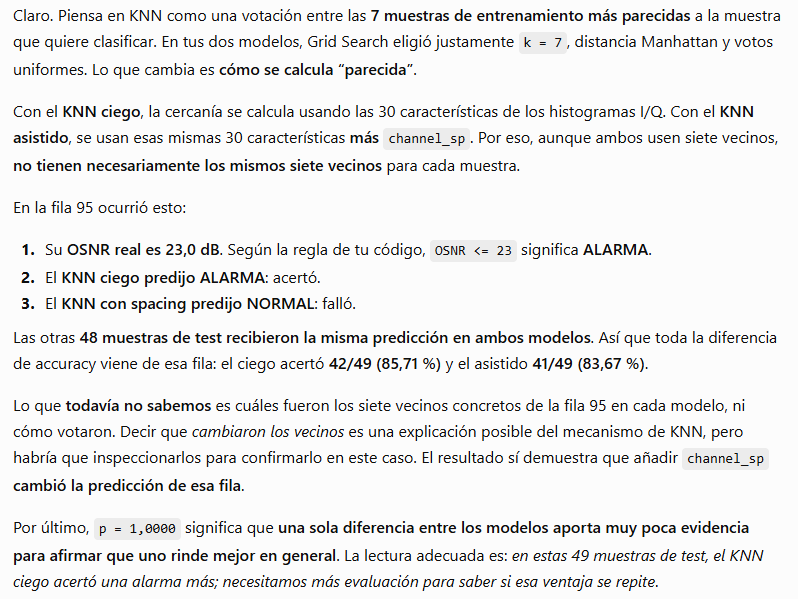

In [ ]:
"""Compara KNN ciego/asistido y muestra sus vecinos para una fila de test."""
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

CSV_PATH = "matriz16GBd_clas.csv"
UMBRAL_OSNR = 23.0
SEED = 42
FILA_A_REVISAR = 95  # Índice de pandas/Python; primera fila del CSV = 0.

matriz = pd.read_csv(CSV_PATH, header=None)
if matriz.shape[1] != 32:
    raise ValueError(f"Se esperan 32 columnas y hay {matriz.shape[1]}.")
matriz = matriz.apply(pd.to_numeric, errors="raise")
if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError("El CSV contiene NaN o valores infinitos.")

# La columna 30 es channel_sp; la 31 es OSNR. OSNR=23 es ALARMA.
y = (matriz.iloc[:, 31].to_numpy() <= UMBRAL_OSNR).astype(int)
indices = np.arange(len(matriz))
idx_train, idx_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

modelos = {}
predicciones = {}
for nombre, n_features in [("ciego", 30), ("con_spacing", 31)]:
    # El ciego utiliza columnas 0..29; el asistido utiliza 0..30.
    X = matriz.iloc[:, :n_features]
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier()),
    ])
    busqueda = GridSearchCV(
        pipeline, param_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True
    )
    busqueda.fit(X.iloc[idx_train], y[idx_train])
    modelos[nombre] = busqueda.best_estimator_
    predicciones[nombre] = modelos[nombre].predict(X.iloc[idx_test])

    print(f"\n=== {nombre.upper()} ===")
    print("Hiperparámetros:", busqueda.best_params_)
    print("Accuracy en test:", f"{accuracy_score(y[idx_test], predicciones[nombre]):.4f}")
    print("Matriz de confusión [NORMAL, ALARMA]:")
    print(confusion_matrix(y[idx_test], predicciones[nombre], labels=[0, 1]))

comparacion = pd.DataFrame({
    "fila_csv": idx_test,
    "OSNR_dB": matriz.iloc[idx_test, 31].to_numpy(),
    "channel_sp": matriz.iloc[idx_test, 30].to_numpy(),
    "clase_real": y[idx_test],
    "pred_ciego": predicciones["ciego"],
    "pred_con_spacing": predicciones["con_spacing"],
})
comparacion["acierto_ciego"] = comparacion["pred_ciego"] == comparacion["clase_real"]
comparacion["acierto_con_spacing"] = (
    comparacion["pred_con_spacing"] == comparacion["clase_real"]
)
print("\n=== FILAS DONDE CAMBIA LA PREDICCIÓN ===")
cambios = comparacion[comparacion["pred_ciego"] != comparacion["pred_con_spacing"]]
print(cambios.sort_values("fila_csv").to_string(index=False) if len(cambios)
      else "Los modelos predijeron lo mismo en todo el test.")

solo_ciego = int((comparacion["acierto_ciego"] & ~comparacion["acierto_con_spacing"]).sum())
solo_asistido = int((~comparacion["acierto_ciego"] & comparacion["acierto_con_spacing"]).sum())
print(f"\nSolo acierta el ciego: {solo_ciego}")
print(f"Solo acierta el asistido: {solo_asistido}")
if solo_ciego + solo_asistido:
    p = binomtest(min(solo_ciego, solo_asistido),
                n=solo_ciego + solo_asistido, p=0.5,
                alternative="two-sided").pvalue
    print(f"McNemar exacto, p = {p:.4f}")

if FILA_A_REVISAR not in idx_test:
    raise ValueError(
        f"La fila {FILA_A_REVISAR} no está en test con esta semilla. "
        "Elige una fila de la tabla de cambios o revisa que uses el mismo CSV."
    )
print(f"\n=== VECINOS DE LA FILA {FILA_A_REVISAR} ===")
print("OSNR real:", matriz.iloc[FILA_A_REVISAR, 31], "dB;")
print("channel_sp:", matriz.iloc[FILA_A_REVISAR, 30])
print("Clase real:", "ALARMA" if y[FILA_A_REVISAR] else "NORMAL")

vecinos_por_modelo = {}
for nombre, n_features in [("ciego", 30), ("con_spacing", 31)]:
    modelo = modelos[nombre]
    X_caso = matriz.iloc[[FILA_A_REVISAR], :n_features]
    caso_escalado = modelo.named_steps["scaler"].transform(X_caso)
    knn = modelo.named_steps["knn"]
    distancias, posiciones = knn.kneighbors(
        caso_escalado, n_neighbors=knn.n_neighbors
    )
    # posiciones se refieren al orden de idx_train utilizado en fit.
    filas_vecinas = idx_train[posiciones[0]]
    vecinos_por_modelo[nombre] = set(filas_vecinas)
    tabla = pd.DataFrame({
        "fila_vecina_csv": filas_vecinas,
        "distancia_escalada": distancias[0],
        "OSNR_vecino_dB": matriz.iloc[filas_vecinas, 31].to_numpy(),
        "channel_sp_vecino": matriz.iloc[filas_vecinas, 30].to_numpy(),
        "voto": np.where(y[filas_vecinas] == 1, "ALARMA", "NORMAL"),
    })
    pred = int(modelo.predict(X_caso)[0])
    print(f"\n--- {nombre.upper()} ---")
    print(tabla.to_string(index=False))
    print("Votos:", tabla["voto"].value_counts().to_dict())
    print("Predicción:", "ALARMA" if pred else "NORMAL")
    print("Pesos:", knn.weights)

comunes = vecinos_por_modelo["ciego"] & vecinos_por_modelo["con_spacing"]
print(f"\nVecinos comunes: {len(comunes)}")
print("Filas comunes:", sorted(comunes))
print("Solo vecinos del ciego:", sorted(vecinos_por_modelo["ciego"] - comunes))
print("Solo vecinos del asistido:", sorted(vecinos_por_modelo["con_spacing"] - comunes))
print("Nota: las distancias numéricas usan distinto número de columnas y no son directamente comparables.")


=== CIEGO ===
Hiperparámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy en test: 0.8571
Matriz de confusión [NORMAL, ALARMA]:
[[23  5]
 [ 2 19]]

=== CON_SPACING ===
Hiperparámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy en test: 0.8367
Matriz de confusión [NORMAL, ALARMA]:
[[23  5]
 [ 3 18]]

=== FILAS DONDE CAMBIA LA PREDICCIÓN ===
 fila_csv  OSNR_dB  channel_sp  clase_real  pred_ciego  pred_con_spacing  acierto_ciego  acierto_con_spacing
       95     23.0        16.5           1           1                 0           True                False

Solo acierta el ciego: 1
Solo acierta el asistido: 0
McNemar exacto, p = 1.0000

=== VECINOS DE LA FILA 95 ===
OSNR real: 23.0 dB;
channel_sp: 16.5
Clase real: ALARMA

--- CIEGO ---
 fila_vecina_csv  distancia_escalada  OSNR_vecino_dB  channel_sp_vecino   voto
              66            9.761303            27.0               16.0 NORMAL
             220           10.778178 

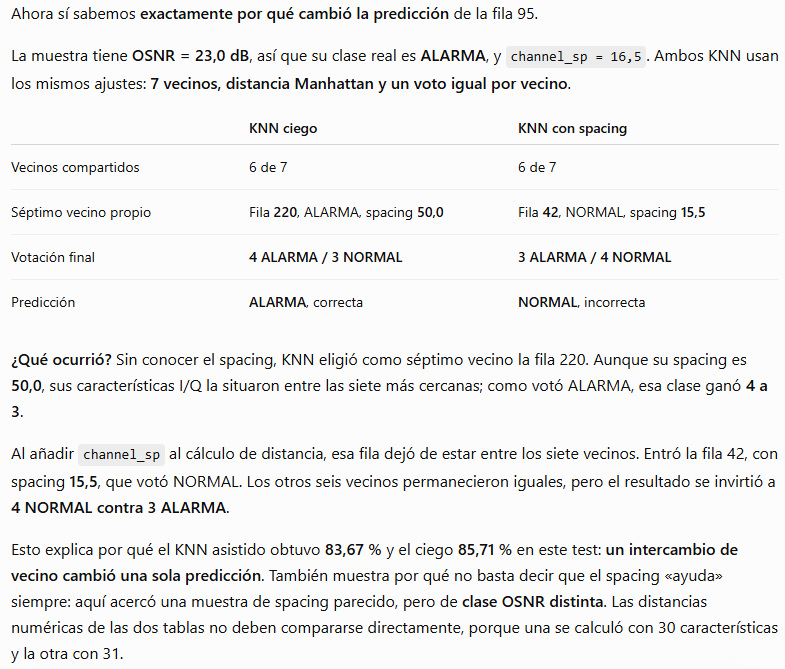

## KNN 32GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_KDE_correct.csv
Muestras: 9307
Características utilizadas: 30
NORMAL: 5805
ALARMA: 3502
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 20

INICIANDO NESTED CV 5x5 - KNN CIEGO 32 GBd

OUTER FOLD 1/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'distance'}
Inner CV Best F1: 0.7305

MÉT

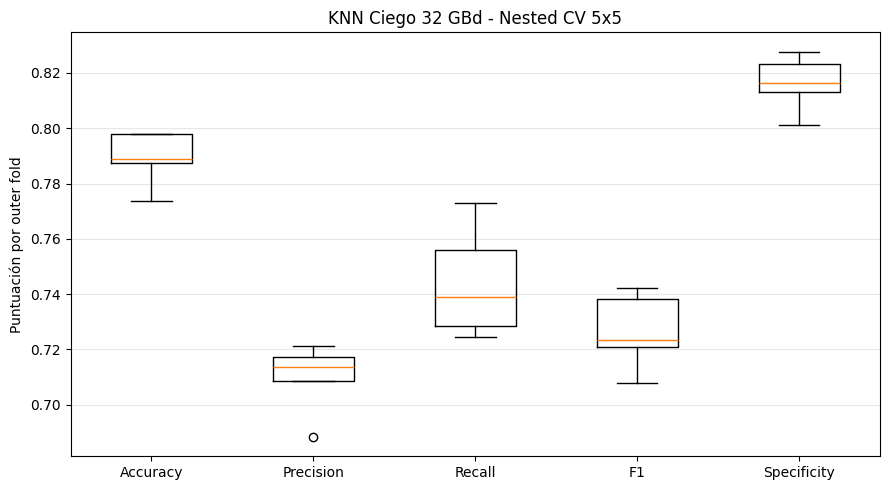


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.7892
OOF Precision:   0.7097
OOF Recall:      0.7441
OOF F1:          0.7265
OOF Specificity: 0.8164

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.84      0.82      0.83      5805
      ALARMA       0.71      0.74      0.73      3502

    accuracy                           0.79      9307
   macro avg       0.78      0.78      0.78      9307
weighted avg       0.79      0.79      0.79      9307


Matriz de confusión OOF:
[[4739 1066]
 [ 896 2606]]


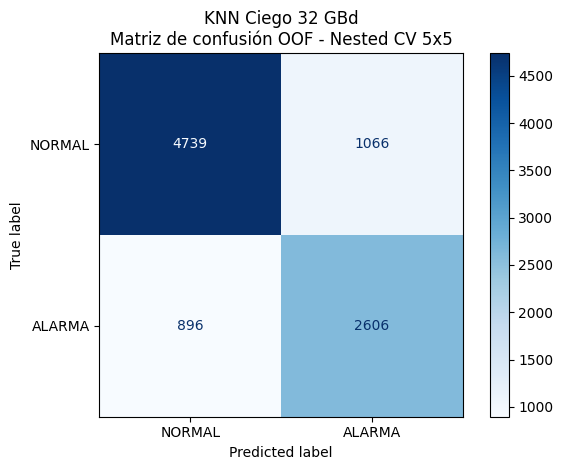


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                15       2     distance          0.730496
    2                11       1     distance          0.730788
    3                15       2     distance          0.727843
    4                15       2     distance          0.726932
    5                15       1     distance          0.722439

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 7.800 µs/muestra
Inference Std:  3.099 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN CIEGO

Mejores parámetros modelo final:
{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
F1 GridSearch final: 0.7346

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
Q_broadening      0.028297              5.82%
   I_peak2_y      0.025884              5.33%
I_broadening      0.025500              5.25%
 I_valley3_y      0.024565              5.05%
   I_peak3_y      0.023811              4.90%
   Q_peak2_y      0.022660              4.66%
   I_peak4_y      0.021968              4.52%
 Q_valley2_y      0.020690              4.26%
 Q_valley3_y      0.018595              3.83%
 Q_valley1_y      0.018515              3.81%
 I_valley1_y      0.017291              3.56%
   Q_peak1_x      0.017268              3.55%
   Q_peak1_y      0.017158              3.53%
   Q_peak3_y      0.016810              3.46%
   I_peak1_y      0.016299              3.35%
   I_peak3_x      0.015822              3.26%
   I_peak1_x      0.015563              3.20%
 I_valley2_y      0.014307              2.94%
 Q_valley1_x      0.013848              2.85%
   Q_peak2_x      0.013483              

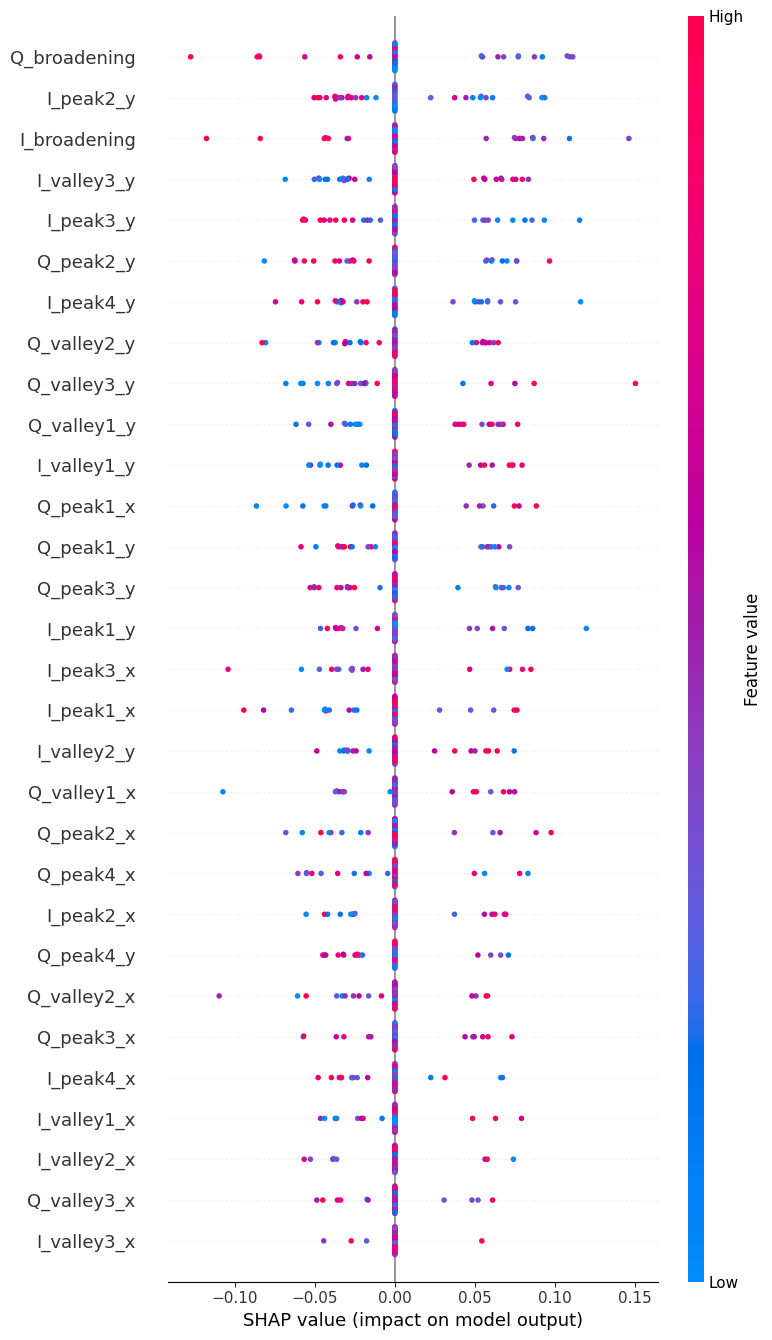

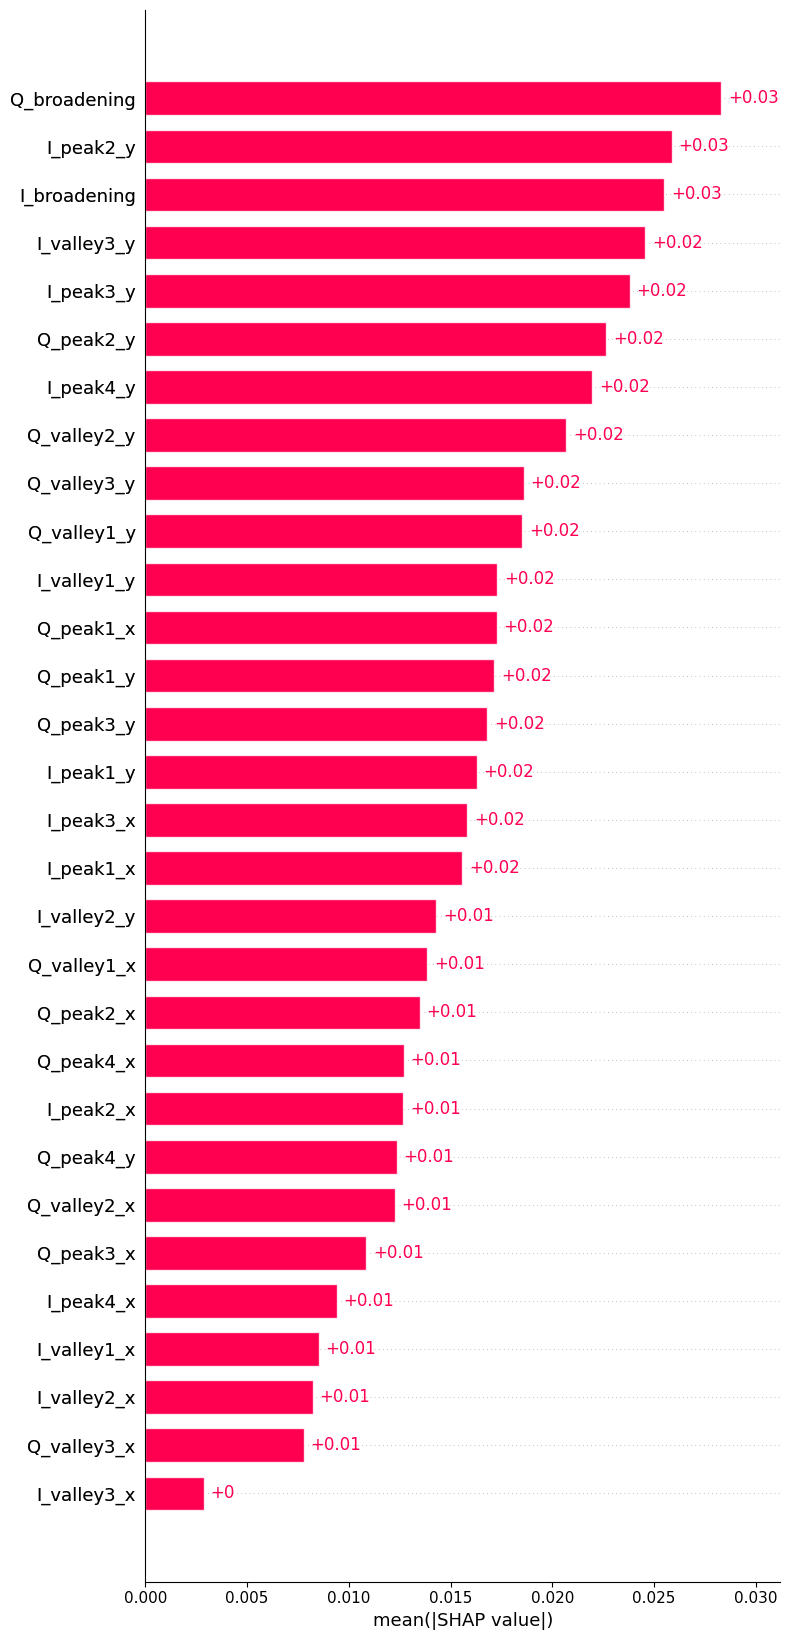

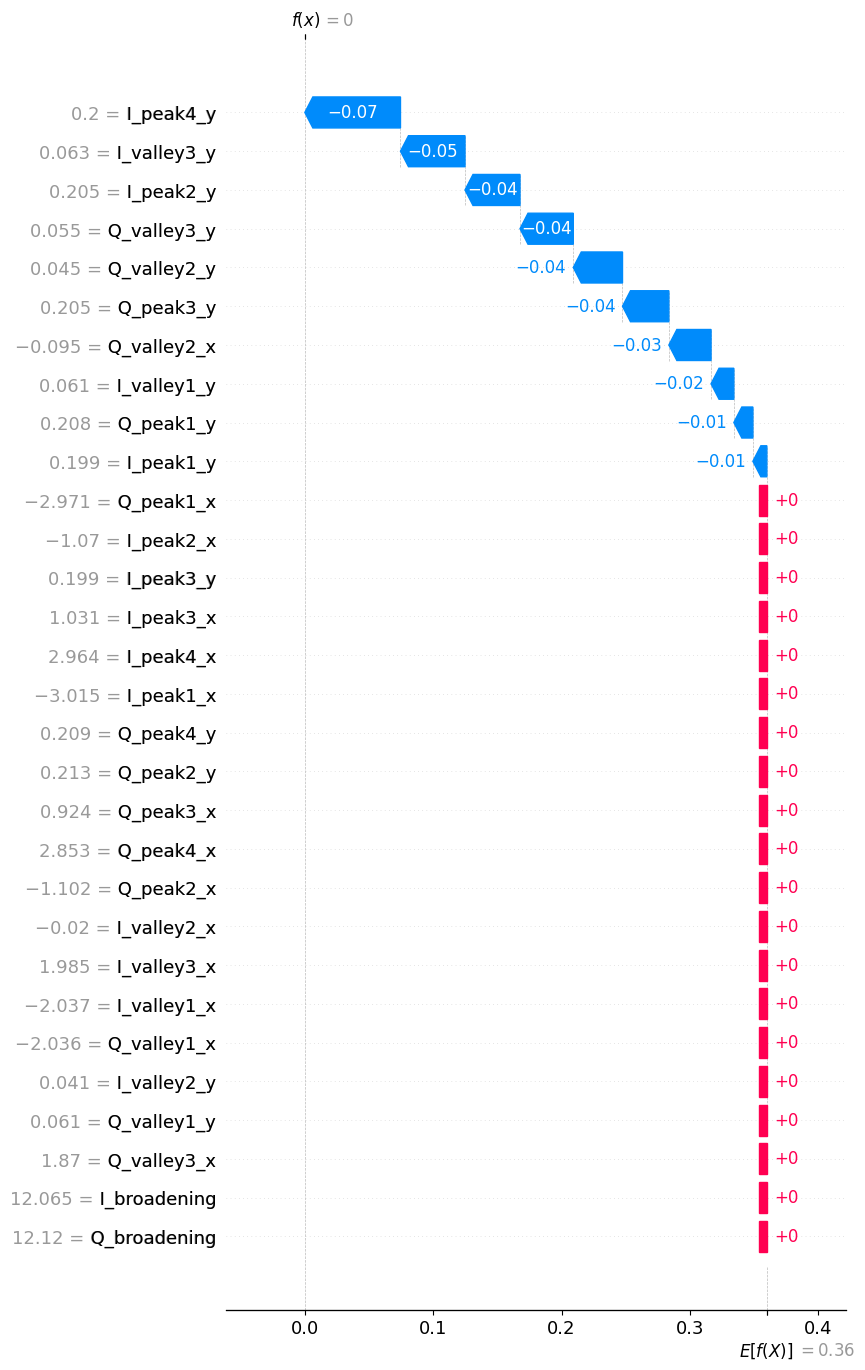


RESUMEN FINAL - KNN CIEGO 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.7892 ± 0.0089
Outer CV PRECISION   : 0.7098 ± 0.0115
Outer CV RECALL      : 0.7441 ± 0.0181
Outer CV F1          : 0.7265 ± 0.0124
Outer CV SPECIFICITY : 0.8164 ± 0.0092

OOF Accuracy: 0.7892
OOF Precision: 0.7097
OOF Recall: 0.7441
OOF F1: 0.7265
OOF Specificity: 0.8164

Inference Mean: 7.800 µs/muestra
Inference Std: 3.099 µs/muestra

Archivos generados:
1. knn_osnr_32GBd_ciego_nested_outer_folds.csv
2. knn_osnr_32GBd_ciego_nested_oof_predictions.csv
3. knn_osnr_32GBd_ciego_nested_best_params.csv
4. knn_osnr_32GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 32 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_KDE_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

n_combinations = (
    len(param_grid["knn__n_neighbors"]) *
    len(param_grid["knn__weights"]) *
    len(param_grid["knn__p"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN CIEGO 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN Ciego 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Ciego 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN CIEGO 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_32GBd_ciego_nested_outer_folds.csv")
print("2. knn_osnr_32GBd_ciego_nested_oof_predictions.csv")
print("3. knn_osnr_32GBd_ciego_nested_best_params.csv")
print("4. knn_osnr_32GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 32GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_KDE_correct.csv
Muestras: 9307
Características utilizadas: 30
NORMAL: 5805
ALARMA: 3502
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 32

INICIANDO NESTED CV 5x5 - SVM CIEGO 32 GBd

OUTER FOLD 1/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.1}
Inner CV Best F1: 0.7504

MÉ

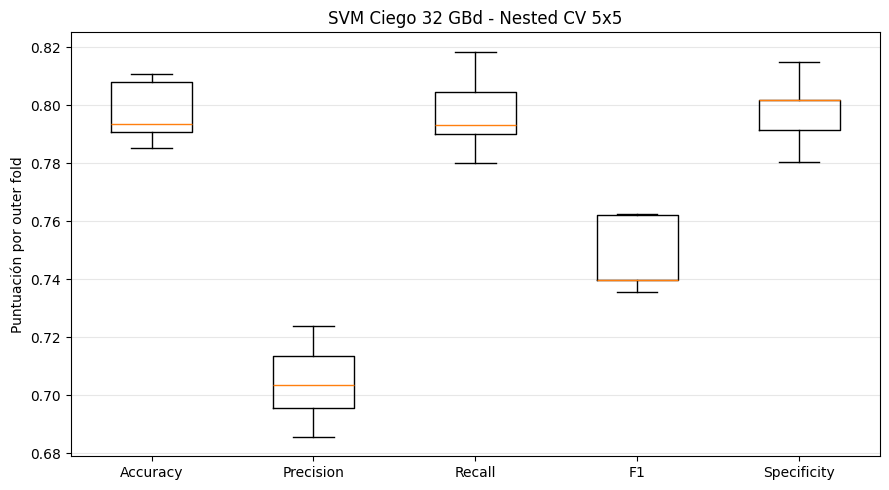


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.7978
OOF Precision:   0.7043
OOF Recall:      0.7973
OOF F1:          0.7479
OOF Specificity: 0.7981

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.87      0.80      0.83      5805
      ALARMA       0.70      0.80      0.75      3502

    accuracy                           0.80      9307
   macro avg       0.79      0.80      0.79      9307
weighted avg       0.81      0.80      0.80      9307


Matriz de confusión OOF:
[[4633 1172]
 [ 710 2792]]


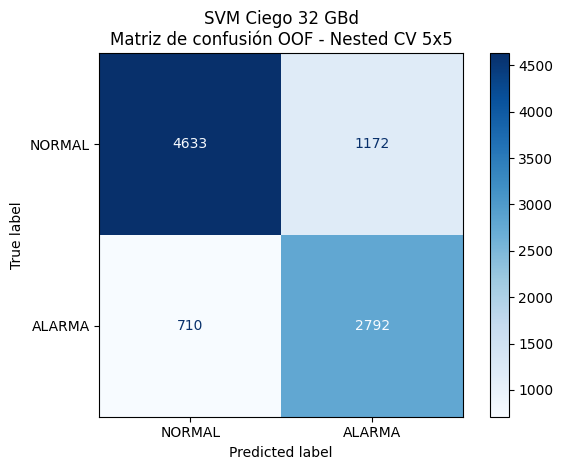


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight svm__gamma  inner_cv_best_f1
    1      10          balanced        0.1          0.750442
    2      10          balanced        0.1          0.746868
    3      10          balanced      scale          0.749601
    4     100          balanced      scale          0.750441
    5      10          balanced        0.1          0.745723

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 145.950 µs/muestra
Inference Std:  3.722 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM CIEGO

Mejores parámetros modelo final:
{'svm__C': 1, 'svm__class_weight': 'balanced', 'svm__gamma': 0.1}
F1 GridSearch final: 0.7508

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
Q_broadening      0.179786             13.02%
   I_peak2_y      0.145213             10.51%
   I_peak3_y      0.112875              8.17%
I_broadening      0.111039              8.04%
   Q_peak2_y      0.105484              7.64%
   Q_peak1_x      0.072071              5.22%
   I_peak1_x      0.056790              4.11%
   I_peak4_x      0.055492              4.02%
   I_peak4_y      0.053265              3.86%
 I_valley3_x      0.052376              3.79%
   Q_peak3_y      0.047592              3.45%
 Q_valley3_y      0.046569              3.37%
 I_valley1_y      0.046250              3.35%
   Q_peak3_x      0.036011              2.61%
   I_peak2_x      0.030951              2.24%
   Q_peak4_x      0.027870              2.02%
 I_valley3_y      0.023775              1.72%
   I_peak3_x      0.023494              1.70%
   Q_peak4_y      0.022934              1.66%
 Q_valley1_y      0.022415              

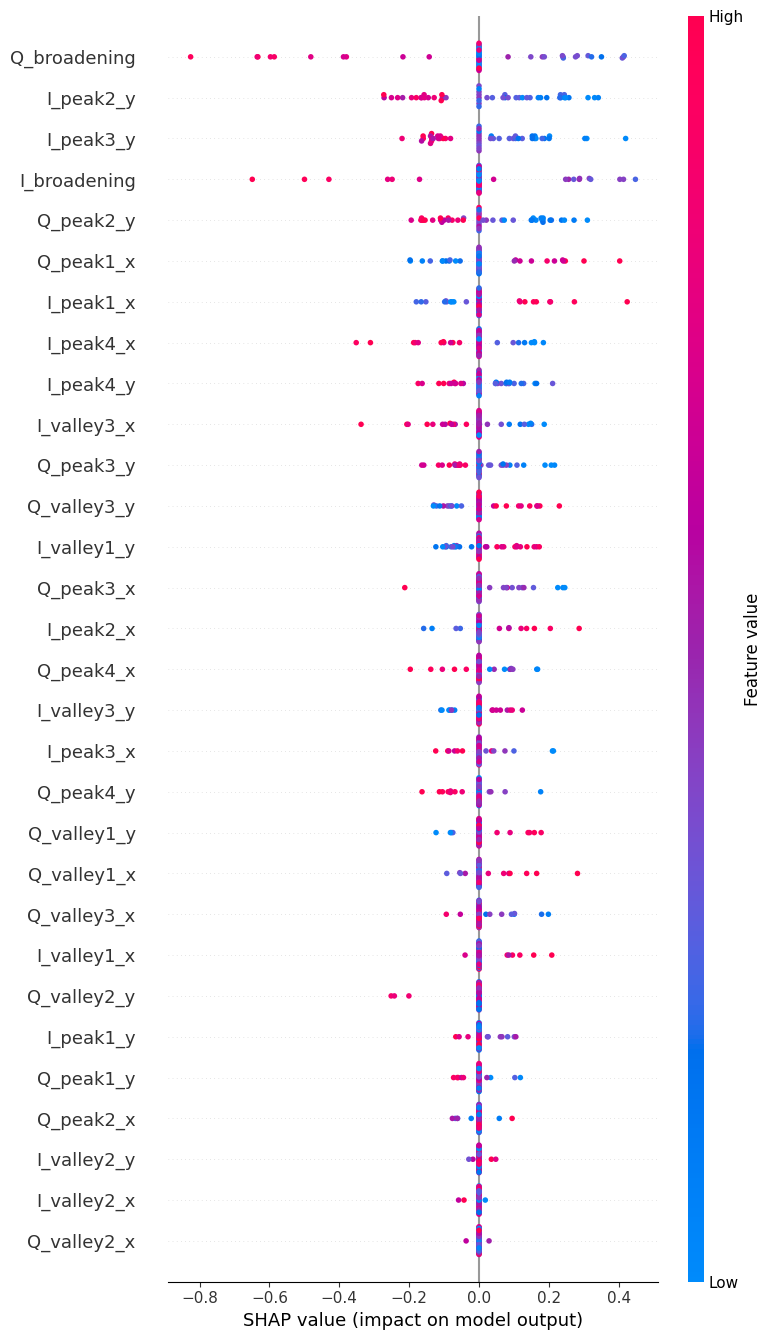

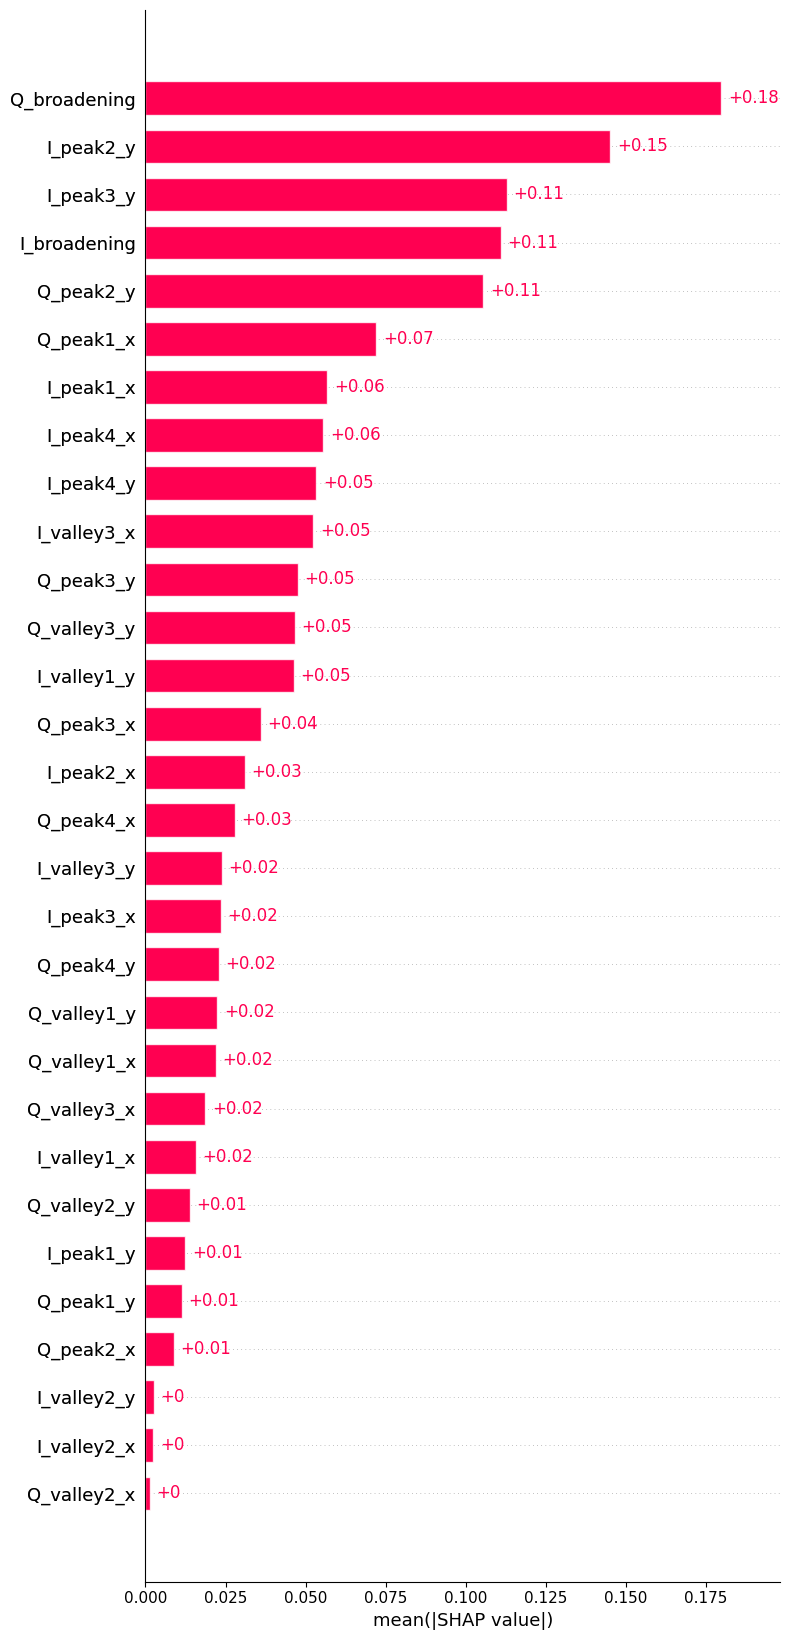

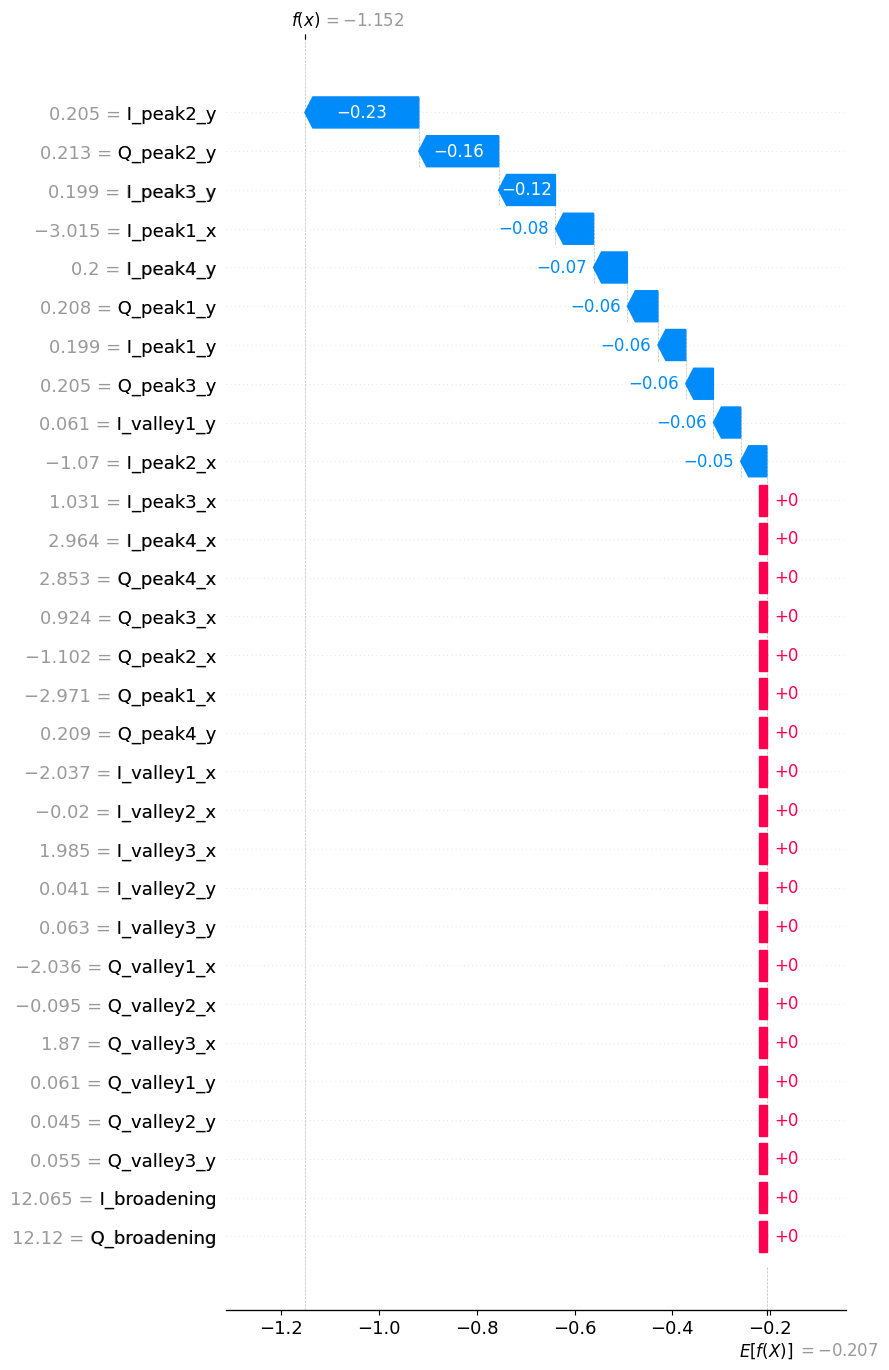


RESUMEN FINAL - SVM CIEGO 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.7978 ± 0.0100
Outer CV PRECISION   : 0.7045 ± 0.0134
Outer CV RECALL      : 0.7973 ± 0.0132
Outer CV F1          : 0.7479 ± 0.0118
Outer CV SPECIFICITY : 0.7981 ± 0.0115

OOF Accuracy: 0.7978
OOF Precision: 0.7043
OOF Recall: 0.7973
OOF F1: 0.7479
OOF Specificity: 0.7981

Inference Mean: 145.950 µs/muestra
Inference Std: 3.722 µs/muestra

Archivos generados:
1. svm_osnr_32GBd_ciego_nested_outer_folds.csv
2. svm_osnr_32GBd_ciego_nested_oof_predictions.csv
3. svm_osnr_32GBd_ciego_nested_best_params.csv
4. svm_osnr_32GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 32 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_KDE_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

n_combinations = (
    len(param_grid["svm__C"]) *
    len(param_grid["svm__gamma"]) *
    len(param_grid["svm__class_weight"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuación de decision_function para cada muestra OOF.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM CIEGO 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Puntuación de decisión del SVM.
    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM Ciego 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Ciego 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve la función de decisión del SVM.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM CIEGO 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_32GBd_ciego_nested_outer_folds.csv")
print("2. svm_osnr_32GBd_ciego_nested_oof_predictions.csv")
print("3. svm_osnr_32GBd_ciego_nested_best_params.csv")
print("4. svm_osnr_32GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## RDF 32GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_KDE_correct.csv
Muestras: 9307
Características utilizadas: 30
NORMAL: 5805
ALARMA: 3502
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RF CIEGO 32 GBd

OUTER FOLD 1/5
Outer Train: 7445 muestras
Outer Test:  1862 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_es

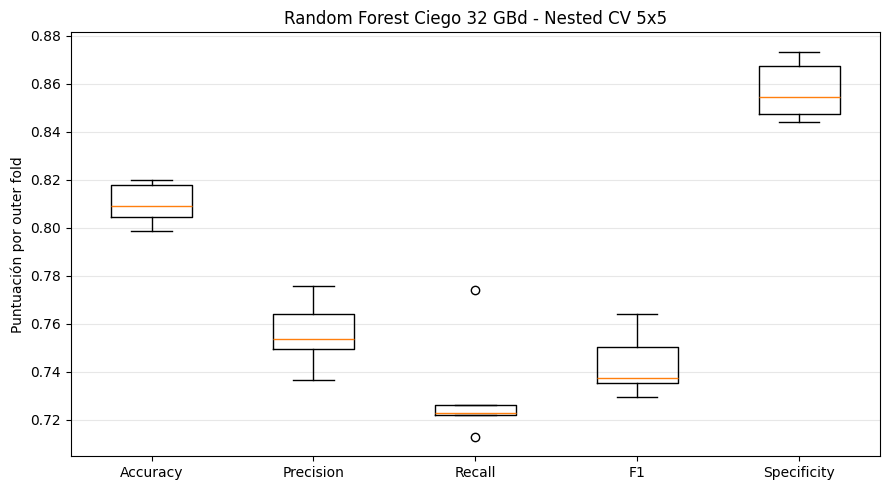


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8100
OOF Precision:   0.7558
OOF Recall:      0.7316
OOF F1:          0.7435
OOF Specificity: 0.8574

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.84      0.86      0.85      5805
      ALARMA       0.76      0.73      0.74      3502

    accuracy                           0.81      9307
   macro avg       0.80      0.79      0.80      9307
weighted avg       0.81      0.81      0.81      9307


Matriz de confusión OOF:
[[4977  828]
 [ 940 2562]]


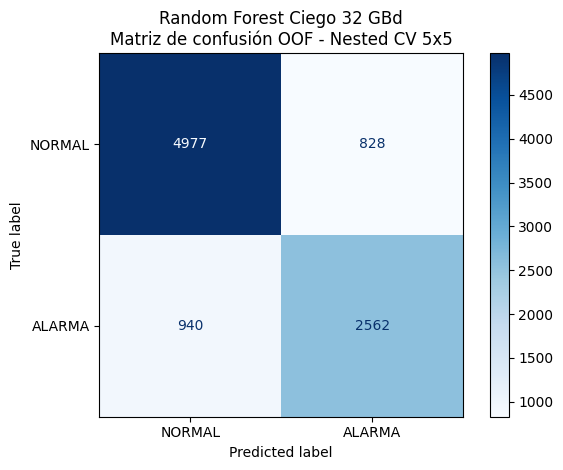


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1       20.0         log2                 1                 10           200          0.745074
    2       20.0         log2                 4                 10           400          0.738405
    3       20.0         log2                 2                  5           400          0.743611
    4        NaN         log2                 1                  5           400          0.745222
    5       20.0         log2                 1                  2           400          0.735502

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 28.389 µs/muestra
Inference Std:  7.120 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye RandomForest.predict().

ENTRENANDO MODELO FINAL - RF CIEGO

Mejores parámetros modelo final:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_sp

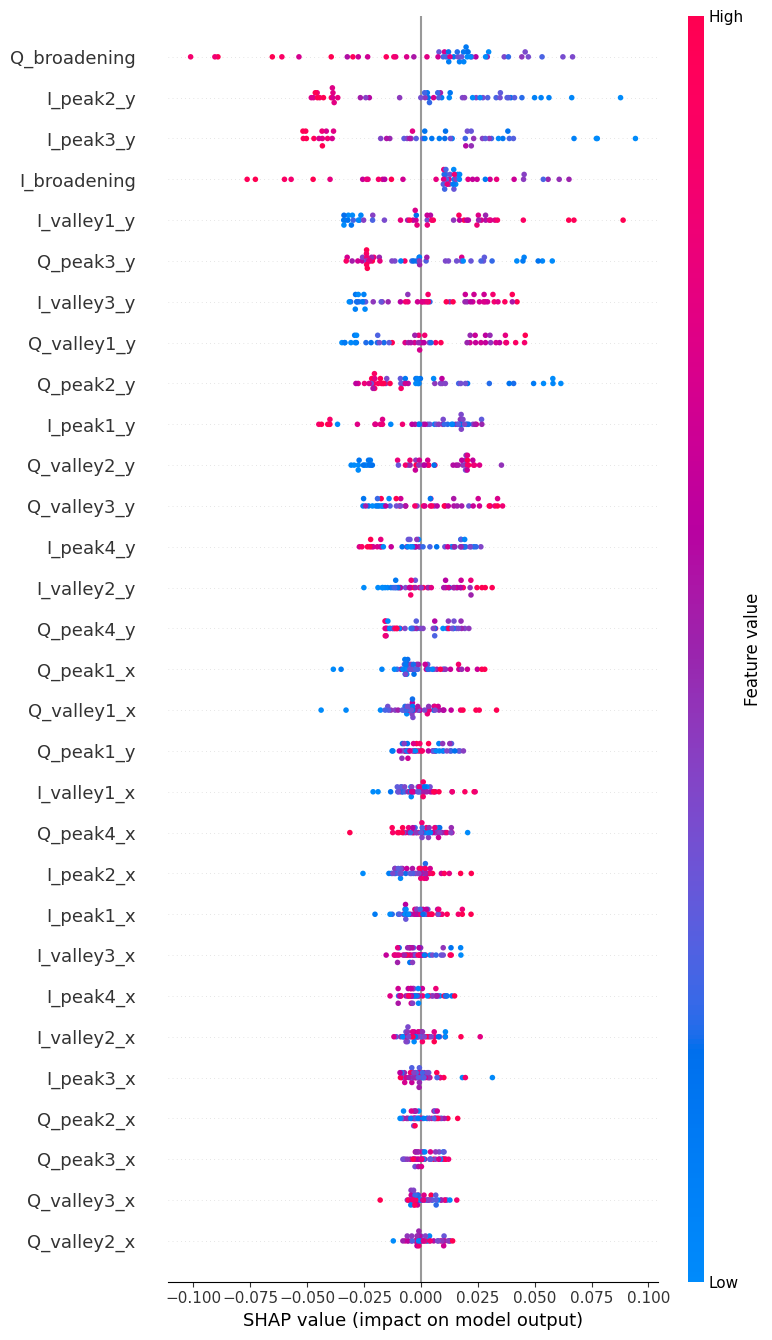

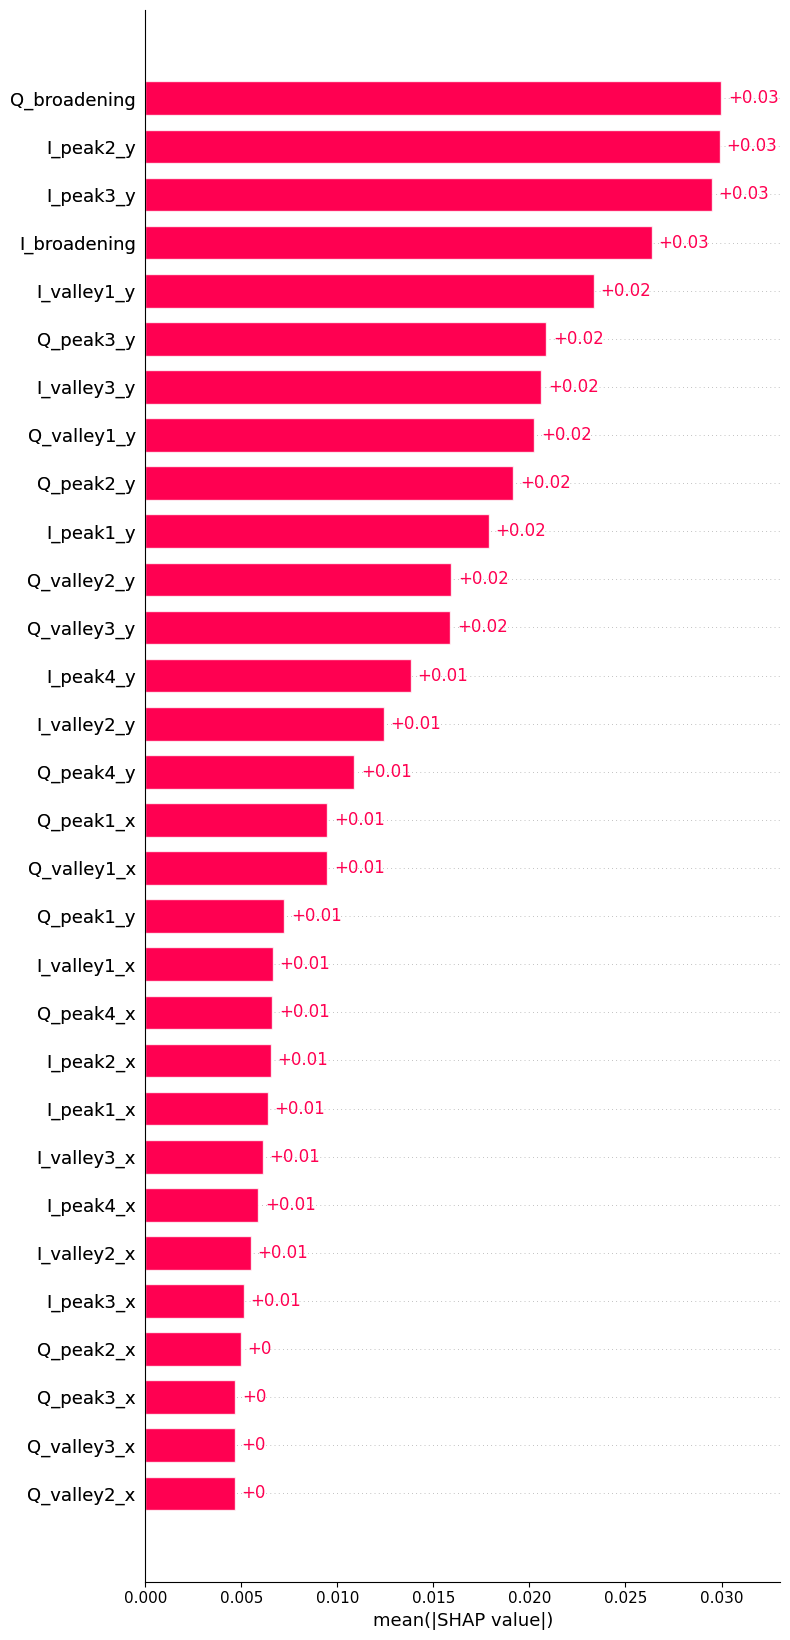

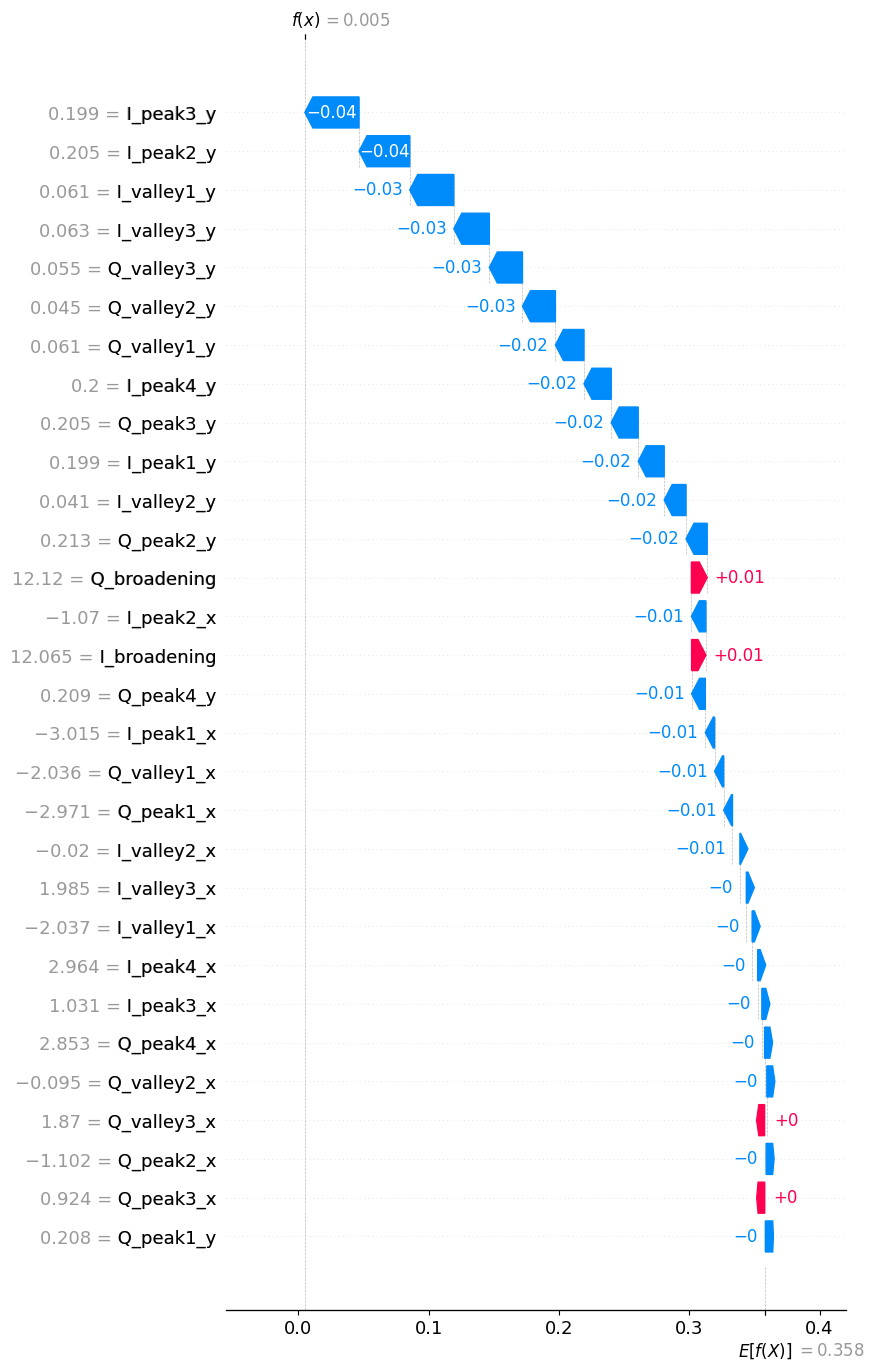


RESUMEN FINAL - RF CIEGO 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8100 ± 0.0081
Outer CV PRECISION   : 0.7560 ± 0.0133
Outer CV RECALL      : 0.7316 ± 0.0218
Outer CV F1          : 0.7434 ± 0.0123
Outer CV SPECIFICITY : 0.8574 ± 0.0113

OOF Accuracy: 0.8100
OOF Precision: 0.7558
OOF Recall: 0.7316
OOF F1: 0.7435
OOF Specificity: 0.8574

Inference Mean: 28.389 µs/muestra
Inference Std: 7.120 µs/muestra

Archivos generados:
1. rf_osnr_32GBd_ciego_nested_outer_folds.csv
2. rf_osnr_32GBd_ciego_nested_oof_predictions.csv
3. rf_osnr_32GBd_ciego_nested_best_params.csv
4. rf_osnr_32GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 32 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP mediante TreeExplainer

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_KDE_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR RANDOM FOREST Y GRID
# ============================================================

def build_model():
    """
    Construye un Random Forest nuevo.

    Random Forest no necesita StandardScaler,
    porque sus árboles realizan divisiones
    basadas en umbrales de las características.

    n_jobs=1 evita paralelismo interno del RF
    mientras GridSearchCV utiliza n_jobs=-1.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva exactamente el grid original.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RF CIEGO 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_model(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest Ciego 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Ciego 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye RandomForest.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RF CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_model(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - TREEEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del RF final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# ============================================================
# 18. COMPATIBILIDAD CON DIFERENTES VERSIONES DE SHAP
# ============================================================

# SHAP puede devolver:
#
# 1. Lista:
#    [valores_clase_0, valores_clase_1]
#
# 2. Arreglo tridimensional:
#    (muestras, características, clases)
#
# Seleccionamos siempre la clase 1 = ALARMA.

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if (
        arr.ndim == 3
        and arr.shape[2] == 2
    ):

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base correspondiente a ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# ============================================================
# 19. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 20. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 21. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 22. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF CIEGO 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_32GBd_ciego_nested_outer_folds.csv")
print("2. rf_osnr_32GBd_ciego_nested_oof_predictions.csv")
print("3. rf_osnr_32GBd_ciego_nested_best_params.csv")
print("4. rf_osnr_32GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")
